## Guía de Imágenes Biomédicas ##
*Procesamiento de Señales e Imágenes Biomédicas*

<u>Número de grupo</u>: 7

<u>Integrantes</u>:  Barboza Tobias <br>
&emsp;&emsp;&emsp;&emsp;&ensp;&ensp;&ensp; Casais Martina <br>
&emsp;&emsp;&emsp;&emsp;&ensp;&ensp;&ensp;  Mitchelena Dolores


                     

&emsp; En el siguiente notebook se muestra el desarrollo llevado a cabo para obtener el *path* de procesamiento completo de un video de contracción y dilatación pupilar frente a un estímulo luminoso. El procesamiento incluye el filtrado, la segmentación, el análisis de texturas y la compresión de las imágenes.  

&emsp; Asimismo, se comentan y se explican cada etapa del procesado buscando realizar un análisis de las metodologías llevadas a cabo y comparar resultados.

In [ ]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import drive
import cv2
from skimage.filters import roberts, prewitt

In [ ]:
#Cargar drive
drive.mount("/content/drive")

Mounted at /content/drive


## MÓDULO 1: Fundamentos, Manejo de Espacios de Color y Mejoramiento Digital ##

###1.1 Carga, Muestreo y Espacios de Color ###


***Inspección inicial***

^^^^^^^^^^^^^^^^^^^^^^^^^^
Inspección incial de datos
^^^^^^^^^^^^^^^^^^^^^^^^^^


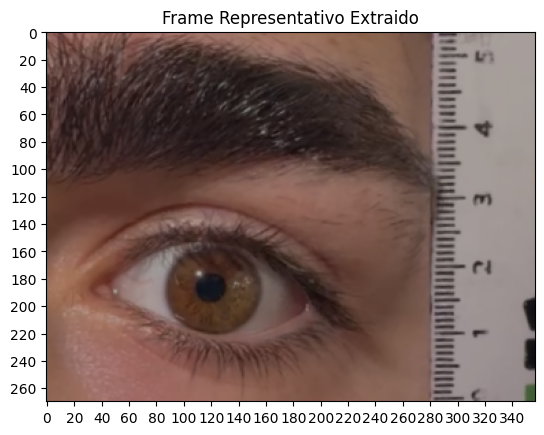


----- Dimensiones de la imagen -----
Pixeles de ancho: 357
Pixeles de alto: 270
Canales: 3

----- Profundidad de la imagen -----
Profundidad por canal: 8 bits
Profundidad total: 24 bits (Imagen de 24 bits)

----- Capacidad de color -----
Niveles de intensidad por canal (R, G o B): 256
Colores totales posibles en la imagen: 16777216

----- Tamaño del pixel ----- 
Tamaño del lado del pixel: 0.01962962962962963 cm

----- Tamaño de la imagen -----
Ancho: 70.07777777777777 mm 
Alto: 53.0 mm


In [ ]:
# Importamos el frame representativo
ruta_1 = "/content/drive/MyDrive/PSIB - TPs/Guía imágenes/PARTE 1/frame_representativo.png"
ruta_2 = "/content/drive/MyDrive/PSIB - TPs/Guía imágenes/PARTE 1/img_2.png" #En esta foto está recta la regla
ruta_3 = "/content/drive/MyDrive/PSIB - TPs/Guía imágenes/PARTE 1/img_3.png" #En esta foto está recta la regla desde 0mm
imagen = cv2.imread(ruta_3)
imagen_rgb = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

print("^^^^^^^^^^^^^^^^^^^^^^^^^^")
print("Inspección incial de datos")
print("^^^^^^^^^^^^^^^^^^^^^^^^^^")

#Vemos la imagen
plt.imshow(imagen_rgb)
plt.title("Frame Representativo Extraido")
plt.xticks(np.arange(0, 360, 20))
plt.yticks(np.arange(0, 270, 20))
plt.show()

#1. Dimensiones
alto, ancho, canales = imagen_rgb.shape
print("\n----- Dimensiones de la imagen -----")
print(f"Pixeles de ancho: {ancho}")
print(f"Pixeles de alto: {alto}")
print(f"Canales: {canales}") #--> 3 RGB
print()

# 2. Profundidad de bits
bits_por_canal = imagen_rgb.dtype.itemsize * 8 #1 byte = 8 bits
profundidad_total_bits = bits_por_canal * canales

print("----- Profundidad de la imagen -----")
print(f"Profundidad por canal: {bits_por_canal} bits")
print(f"Profundidad total: {profundidad_total_bits} bits (Imagen de 24 bits)")

# 3. Niveles y colores reales
niveles_por_canal = 2 ** bits_por_canal
colores_totales = niveles_por_canal ** canales

print("\n----- Capacidad de color -----")
print(f"Niveles de intensidad por canal (R, G o B): {niveles_por_canal}")
print(f"Colores totales posibles en la imagen: {colores_totales}")

# 4. Dimensión del pixel se ven 5,3cm de alto
lado_pixel = 5.3/alto
print("\n----- Tamaño del pixel ----- ")
print(f"Tamaño del lado del pixel: {lado_pixel} cm")

#5. Dimensiones de la imágen en milimetros
print("\n----- Tamaño de la imagen -----")
print(f"Ancho: {lado_pixel * ancho * 10} mm ")
print(f"Alto: {lado_pixel * 10 * alto} mm")


&ensp; En este primer bloque lo que hicimos fue mostrar la foto extraída del video, seleccionada de forma tal que sea posible ver claramente la púpila y el íris así como las divisiones de la regla. Lo primero que se hizo fue extraer la matriz RGB de la imágen donde cada entrada viene dada por la profundidad de cada canal (rojo, verde y azul) para un pixel, manteniendo su ubicación espacial.

&ensp; Además, buscamos la cantidad de pixeles de ancho y alto, y la profundidad de cada pixel arrojando un resultado de 8 bits por canal lo que se traduce en 256 niveles de intensidad por canal para cada pixel. Por último, se calculó el tamaño del lado del pixel haciendo uso de la regla como referencia de altura en centímetros. Se obtuvo que cada pixel mide 0,19 mm de ancho y largo.

***Región de interés y submuestreo***

#####################
Reducción dimensional
#####################



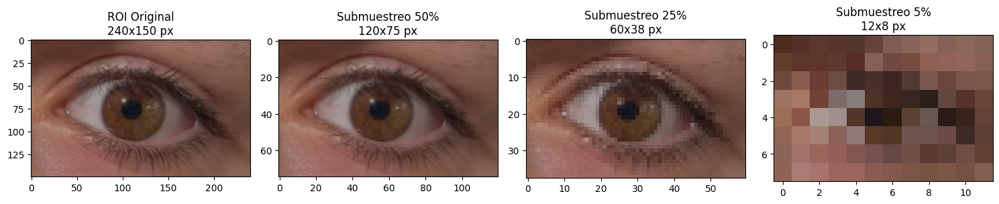

In [ ]:
# Definimos la región de interés como el ojo observando la imagen original
# Coordenadas para slicing
y_inicial, y_final = 110, 260
x_inicial, x_final = 10, 250

roi = imagen_rgb[y_inicial:y_final, x_inicial:x_final]

# Realizamos el submuestreo espacial
# fx y fy son los factores de escala (0.5 = 50%, 0.25 = 25%, 0.05 = 5%)
roi_50 = cv2.resize(roi, None, fx=0.50, fy=0.50, interpolation=cv2.INTER_NEAREST)
roi_25 = cv2.resize(roi, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_NEAREST)
roi_05 = cv2.resize(roi, None, fx=0.05, fy=0.05, interpolation=cv2.INTER_NEAREST)

print("#####################")
print("Reducción dimensional")
print("#####################\n")

# Mostramos los resultados
fig, axs = plt.subplots(1, 4, figsize=(15, 5))
# ROI Original
axs[0].imshow(roi)
axs[0].set_title(f'ROI Original\n{roi.shape[1]}x{roi.shape[0]} px')
# 50%
axs[1].imshow(roi_50)
axs[1].set_title(f'Submuestreo 50%\n{roi_50.shape[1]}x{roi_50.shape[0]} px')
# 25%
axs[2].imshow(roi_25)
axs[2].set_title(f'Submuestreo 25%\n{roi_25.shape[1]}x{roi_25.shape[0]} px')
# 5%
axs[3].imshow(roi_05)
axs[3].set_title(f'Submuestreo 5%\n{roi_05.shape[1]}x{roi_05.shape[0]} px')

plt.tight_layout()
plt.show()

&ensp; En este segundo bloque se definió la Región de Interés (ROI) identificando visualmente las coordenadas de sus límites. Para aislarla, se utilizó la técnica de slicing, recortando directamente la matriz rgb de la imagen para conservar únicamente el contenido de dicho sector.

&ensp; Posteriormente, se realizó un submuestreo espacial de la ROI reduciendo progresivamente la cantidad de píxeles (50%, 25% y 5%). Lo que se observa es una pérdida gradual de definición. Esto ocurre porque al imponerle a la imagen una resolución menor, la información detallada de un cúmulo de píxeles originales debe unificarse y promediarse en uno solo. Esto se traduce en la pérdida de detalles finos en pos de la conservación de tonos generales. Este efecto de degradación se hace evidente en el submuestreo al 5%, donde la estructura anatómica se pierde casi por completo y únicamente se perciben los colores representativos de cada región "macro" de la foto.

***Cuantización***

<<<<<<<<<<<<
Cuantización
>>>>>>>>>>>>



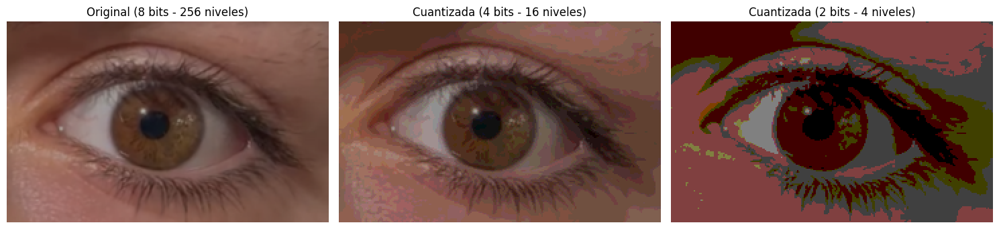

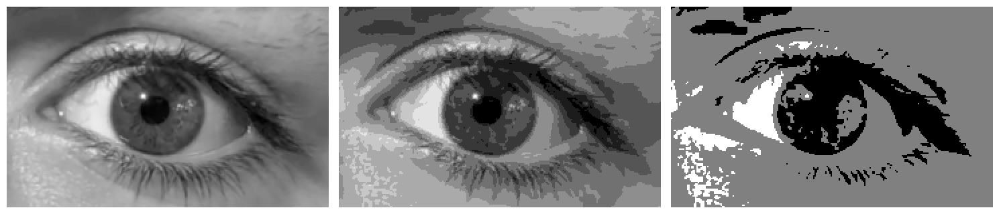

In [ ]:
def cuantizar_imagen(imagen, bits):
    niveles = 2 ** bits
    factor = 256 // niveles
    # División entera y multiplicación para agrupar colores
    imagen_cuantizada = (imagen // factor) * factor
    return imagen_cuantizada.astype(np.uint8)

# Reducción de bits
roi_4bits = cuantizar_imagen(roi, 4)
roi_2bits = cuantizar_imagen(roi, 2)

print("<<<<<<<<<<<<")
print("Cuantización")
print(">>>>>>>>>>>>\n")
# Grafico
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(roi)
axs[0].set_title("Original (8 bits - 256 niveles)")
axs[0].axis("off")

axs[1].imshow(roi_4bits)
axs[1].set_title("Cuantizada (4 bits - 16 niveles)")
axs[1].axis("off")

axs[2].imshow(roi_2bits)
axs[2].set_title("Cuantizada (2 bits - 4 niveles)")
axs[2].axis("off")
plt.tight_layout()
plt.show()

#Ahora en escala de grises
roi_gris = cv2.cvtColor(roi, cv2.COLOR_RGB2GRAY)

# Cuantizamos esa nueva imagen en grises
roi_gris_4bits = cuantizar_imagen(roi_gris, 4)
roi_gris_2bits = cuantizar_imagen(roi_gris, 2)

# Grafico en grises
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(roi_gris, cmap="gray")
axs[0].axis("off")

axs[1].imshow(roi_gris_4bits, cmap="gray")
axs[1].axis("off")

axs[2].imshow(roi_gris_2bits, cmap="gray")
axs[2].axis("off")

plt.tight_layout()
plt.show()

&ensp; En esta ocasión se realizó la cuantización de la imagen, es decir, se redefinió la cantidad de bits por píxel y, por ende, los niveles de intensidad disponibles. Para ello se utilizó una función que calcula los nuevos niveles y obtiene un factor de cociente para transformar la imagen. El resultado es una fotografía que presenta cada vez menos niveles de color/gris para describir su contenido.

&ensp; En el primer caso, cuantizada a 4 bits, si bien se observa un salto en las transiciones entre distintos niveles, el cambio no es tan drástico al compararla con la original, pudiendose identificar cláramente las regiones anatómicas sin una pérdida importante de la distribución espacial. La pérdida de información es más fácil de notar en la imagen en escala de grises, donde se diferencia con certeza el ojo, pero aparecen "lagunas" con tonalidad uniforme (falsos contornos) a su alrededor. Esto indica que las regiones más homogéneas de la foto son más susceptibles a ser aplanadas en la cuantización.

&ensp; Estas diferencias se resaltan aún más en la cuantización a 2 bits pues aca los detalles finos se pierden por completo, y se mantienen reconocibles las estructuras que contienen mucha variabilidad de tonos (alto contraste), como la pupila y las pestañas. Esto tiene sentido lógico pues la cuantización difumina las transiciones sutiles entre tonalidades, entonces en lugares con mayor variabilidad, más se conservan esas estructuras, mientras que en áreas de niveles parecidos, los píxeles colapsan formando esas lagunas planas donde se destruye la información espacial.



***Espacios de color***

>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>
Separación en espacios de color
<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<

                                                                             RGB



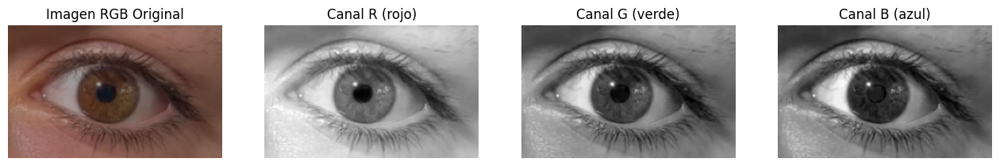


                                                                             HSV



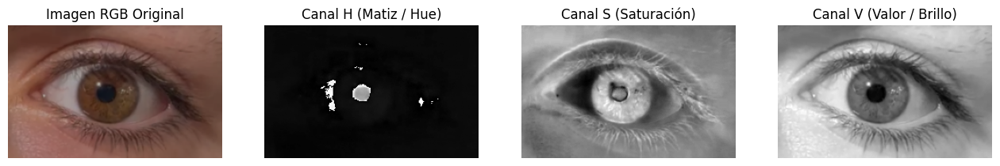

In [ ]:
print(">>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>")
print("Separación en espacios de color")
print("<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<\n")
# Separamos canales RGB
R, G, B = cv2.split(roi)

print("                                                                             RGB\n")
# Graficamos RGB en escala de grises
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
axs[0].imshow(roi)
axs[0].set_title("Imagen RGB Original")
axs[0].axis("off")

axs[1].imshow(R, cmap = "gray")
axs[1].set_title("Canal R (rojo)")
axs[1].axis("off")

axs[2].imshow(G, cmap = "gray")
axs[2].set_title("Canal G (verde)")
axs[2].axis("off")

axs[3].imshow(B, cmap = "gray")
axs[3].set_title("Canal B (azul)")
axs[3].axis("off")
plt.show()

# Convertimos a HSV y separamos canales
roi_hsv = cv2.cvtColor(roi, cv2.COLOR_RGB2HSV)
H, S, V = cv2.split(roi_hsv)

print("\n                                                                             HSV\n")
# Graficamos HSV en escala de grises
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
axs[0].imshow(roi)
axs[0].set_title('Imagen RGB Original')
axs[0].axis('off')

axs[1].imshow(H, cmap='gray')
axs[1].set_title('Canal H (Matiz / Hue)')
axs[1].axis('off')

axs[2].imshow(S, cmap='gray')
axs[2].set_title('Canal S (Saturación)')
axs[2].axis('off')

axs[3].imshow(V, cmap='gray')
axs[3].set_title('Canal V (Valor / Brillo)')
axs[3].axis('off')
plt.show()

&ensp; Continuando, lo que se hizo fue separar la matriz en sus tres canales: R, G y B, donde cada entrada representa la intensidad de luz de ese color específico que tiene el píxel, tomando valores enteros del 0 al 255. Al graficarse individualmente en escala de grises, las zonas más claras (cercanas a 255) indican una mayor presencia de ese color en la imagen original, mientras que las oscuras (cercanas a 0) indican su ausencia.

&ensp; En este sentido, podemos observar que la esclerótica (la parte blanca del ojo) presenta alta intensidad en los tres canales, ya que el blanco puro es la suma máxima de R, G y B. Por otro lado, las pestañas y la pupila se ven oscuras en las tres matrices, lo que se condice con su color negro original, representando la ausencia total de luz (valores cercanos a 0) en las tres componentes.

&ensp; Posteriormente, se transformó la imagen al espacio de color HSV (Matiz, Saturación y Valor). La ventaja principal de este modelo para el procesamiento de imágenes es que desacopla la información cromática de la iluminación, haciéndolo mucho más robusto frente a cambios de luz o sombras.

&ensp; Al observar sus canales por separado, el canal H (Hue o Matiz) representa el tipo de color puro; aquí, estructuras con tonos similares en el círculo cromático, como la piel y un iris marrón (ambos en el espectro rojizo/anaranjado), tomarán valores muy parecidos independientemente de si están iluminados o en la sombra. El canal S (Saturation o Saturación) mide la pureza del color: en esta matriz, la esclerótica y los destellos de luz se ven extremadamente oscuros (valores cercanos a 0) porque son regiones acromáticas (blancas/grises, sin color), mientras que el iris y la piel se muestran más claros al ser áreas con pigmentación saturada. Finalmente, el canal V (Value o Brillo) aísla únicamente la intensidad lumínica, devolviendo una imagen análoga a la escala de grises clásica, donde la pupila y las pestañas destacan por ser las zonas de menor valor (más oscuras).

###1.2 Calidad, Transformaciones de Intensidad y Filtrado Espacial ###


***Histograma, brillo y contraste***

°°°°°°°°°°°°°°°°°°°°°°°°°°°°°°°°°°
Modificación de brillo y contraste
°°°°°°°°°°°°°°°°°°°°°°°°°°°°°°°°°°


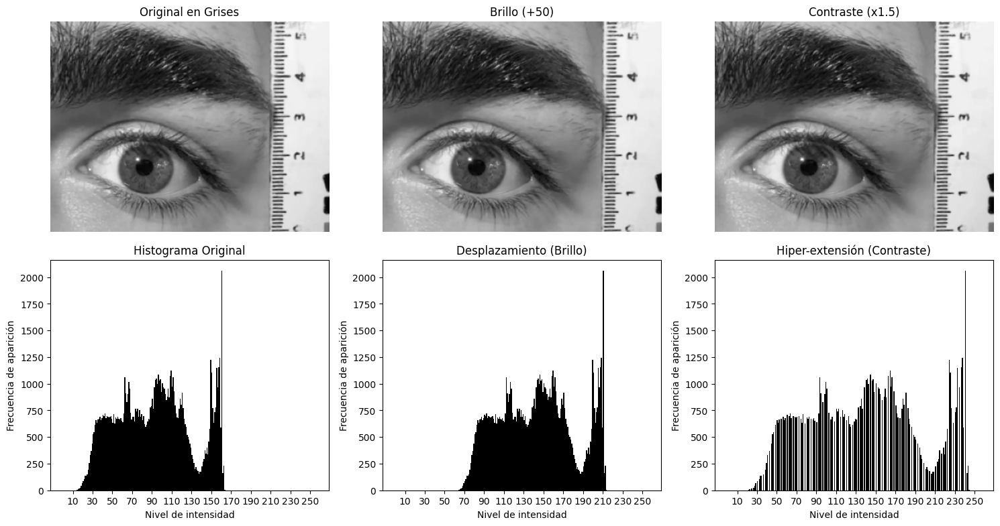


°°°°°°°°°°°°°°°°°°°°°°°°°°°°°°
Escalado lineal y ecualización
°°°°°°°°°°°°°°°°°°°°°°°°°°°°°°



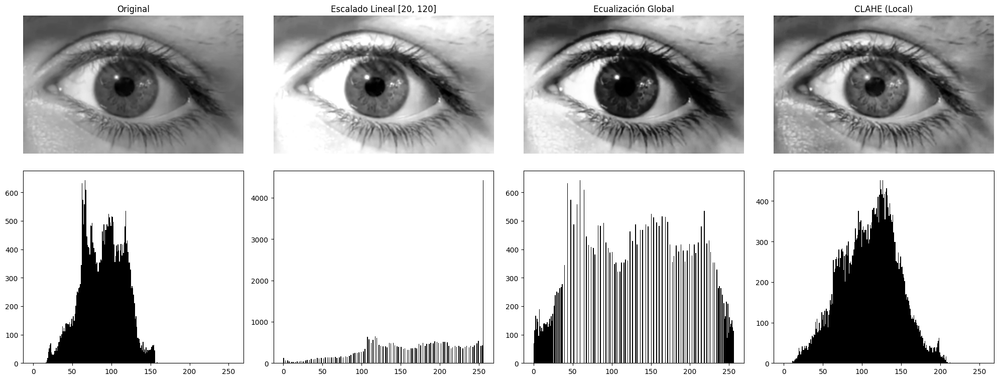


    NOTA: Por cuestiones estéticas y simplicidad de visualización, en estos últimos se decidió no colocar las etiquetas de los ejes, 
asumiendo la obviedad de estas al tratarse de histogramas


In [ ]:
#Primero modificamos el contraste y brillo de la imagen
frame_gris = cv2.cvtColor(imagen_rgb, cv2.COLOR_RGB2GRAY)

# alpha multiplica cada píxel por el factor.
frame_contraste = cv2.convertScaleAbs(frame_gris, alpha=1.5, beta=0)

# beta suma una constante a cada píxel. Saturando en 255.
frame_brillo = cv2.convertScaleAbs(frame_gris, alpha=1.0, beta=50)

# Ahora graficamos
fig, axs = plt.subplots(2, 3, figsize = (15,8))

print("°°°°°°°°°°°°°°°°°°°°°°°°°°°°°°°°°°")
print("Modificación de brillo y contraste")
print("°°°°°°°°°°°°°°°°°°°°°°°°°°°°°°°°°°")

# En la primera fila las imagenes
axs[0, 0].imshow(frame_gris, cmap="gray")
axs[0, 0].set_title("Original en Grises")
axs[0, 0].axis("off")

axs[0, 1].imshow(frame_brillo, cmap="gray")
axs[0, 1].set_title("Brillo (+50)")
axs[0, 1].axis("off")

axs[0, 2].imshow(frame_contraste, cmap="gray")
axs[0, 2].set_title("Contraste (x1.5)")
axs[0, 2].axis("off")

# En la segunda fila los histogramas
axs[1, 0].hist(frame_gris.ravel(), bins = 256, range = [0,256], color = "black")
axs[1, 0].set_title("Histograma Original")
axs[1, 0].set_xlabel("Nivel de intensidad")
axs[1, 0].set_ylabel("Frecuencia de aparición")
axs[1, 0].set_xticks(np.arange(10,256,20))

axs[1, 1].hist(frame_brillo.ravel(), bins=256, range=[0, 256], color="black")
axs[1, 1].set_title("Desplazamiento (Brillo)")
axs[1, 1].set_xlabel("Nivel de intensidad")
axs[1, 1].set_ylabel("Frecuencia de aparición")
axs[1, 1].set_xticks(np.arange(10,256,20))

axs[1, 2].hist(frame_contraste.ravel(), bins=256, range=[0, 256], color="black")
axs[1, 2].set_title("Hiper-extensión (Contraste)")
axs[1, 2].set_xlabel("Nivel de intensidad")
axs[1, 2].set_ylabel("Frecuencia de aparición")
axs[1, 2].set_xticks(np.arange(10,256,20))

plt.tight_layout()
plt.show()

print("\n°°°°°°°°°°°°°°°°°°°°°°°°°°°°°°")
print("Escalado lineal y ecualización")
print("°°°°°°°°°°°°°°°°°°°°°°°°°°°°°°\n")
# 1. Escalado por Rango de Interés (Transformación Lineal)
f1 = 20
f2 = 120

# Aplicamos la fórmula: g(x,y) = (f(x,y) - f1) * (255 / (f2 - f1))
# np.clip asegura que los valores no se pasen de 0 ni de 255
roi_escalada = np.clip((roi_gris.astype(float) - f1) * (255 / (f2 - f1)), 0, 255).astype(np.uint8)

# 2. Ecualización Global
roi_ecualizada = cv2.equalizeHist(roi_gris)

# 3. Ecualización Local (CLAHE - Contrast Limited Adaptive Histogram Equalization)
# tileGridSize divide la imagen en bloques de 8x8 para ecualizar localmente
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
roi_clahe = clahe.apply(roi_gris)

# --- Gráficos ---
fig, axs = plt.subplots(2, 4, figsize=(20, 8))
imagenes = [roi_gris, roi_escalada, roi_ecualizada, roi_clahe]
titulos = ["Original", f"Escalado Lineal [{f1}, {f2}]", "Ecualización Global", "CLAHE (Local)"]

for i in range(4):
    # Fila de imágenes
    axs[0, i].imshow(imagenes[i], cmap="gray")
    axs[0, i].set_title(titulos[i])
    axs[0, i].axis("off")

    # Fila de histogramas
    axs[1, i].hist(imagenes[i].ravel(), bins=256, range=[0, 256], color="black")

plt.tight_layout()
plt.show()

print("\n    NOTA: Por cuestiones estéticas y simplicidad de visualización, en estos últimos se decidió no colocar las etiquetas de los ejes, \nasumiendo la obviedad de estas al tratarse de histogramas")

&ensp; En este bloque extrajimos el histograma de la ROI en escala de grises para tres situaciones: la imagen original, un aumento del brillo en 50 unidades y un aumento del contraste por un factor de 1,5. Esto se realizó utilizando la función  **```cv2.convertScaleAbs```**, que modifica la imagen desplazando, expandiendo o comprimiendo su histograma. Al graficar las imágenes junto con sus respectivos histogramas, pudimos observar dos situaciones:

* Un aumento de Brillo implica un desplazamiento lateral del histograma completo. Matemáticamente, se le suma una constante a la intensidad de cada píxel. El resultado es que los píxeles más oscuros se desplazan hacia tonos más brillantes (en nuestro caso, el límite inferior pasó de aproximadamente 10 a 60), y los más claros se acercan aún más al blanco puro (pasando de 160 a 210). Al observar la imagen, los tonos claros viran visiblemente hacia el blanco (como la piel bajo el ojo). Sin embargo, al ser un desplazamiento aditivo, la estructura general y el contraste se mantienen idénticos, ya que la forma del histograma se conserva y no cambian las distancias relativas entre los niveles de intensidad de los píxeles.

* Un aumento de Contraste, por el otro lado, implica una modificación en las intensidades relativas entre los píxeles. El mecanismo subyacente es una multiplicación, lo que genera una expansión del histograma para que la imagen utilice un rango más amplio de tonalidades. Al separar o "estirar" los valores de intensidad, se aumenta la diferencia visual entre zonas próximas. El resultado es una imagen que presenta bordes y límites estructurales más definidos, lo cual facilita la diferenciación anatómica de los tejidos.

&ensp; En la segunda parte de este bloque lo que se hizo fue modificar el histograma de tres formas distintas con el objetivo de aumentar el contraste entre la pupila y el iris, y se graficó los resultados uno al lado del otro para comparar el desempeño de cada forma y sus respectivos histogramas:

* La primera columna representa la ROI original junto con su histograma como referencia.
* La segunda columna muestra el resultado de aplicar una transformación lineal al histograma en un rango de interés. Lo que se hizo fue observar el histograma de la ROI original e identificar visualmente el rango de interés para aumentar el contraste entre la pupila, el iris y los alrededores. A partir de eso se redefinió el cero de nuestro histograma como f1, desplazandolo horizontalmente hacia izquierda. Luego se modifica la intensidad de cada pixel multiplicándola por la razón 255/(f2-f1). El resultado es como si hiciesemos zoom en el rango de las intensidades seleccionadas, y expandiésemos todos esos pixeles hacia los laterales. Lo que se observa es un mayor contraste entre el iris y la esclerótica además de la disminución de tonalidades intermedias en las zonas al rededor del ojo, donde ahora la piel se ve mucho más blanca. Esto también se debe al efecto de saturación: todos los píxeles originales con intensidades menores a f1 se fuerzan al negro puro (0) y los mayores a f2 se fuerzan al blanco puro (255). Este recorte es lo que elimina por completo las tonalidades intermedias que quedaban fuera de nuestro rango de interés, explicando por qué la piel ahora se ve mucho más blanca. El objetivo se consigió: ahora resaltan más las estructuras del iris y las pupilas. Como artefacto visual, este método genera áreas completamente quemadas (blanco puro) o saturadas en negro debido al recorte de intensidades fuera de la ventana seleccionada.
* En la tercer columna se aplicó una ecualización global al histograma con la función **```cv2.equalizeHist```**, que expande el histograma en las zonas de intensidades más densas. Si bien la imagen resultante muestra un aumento del contraste a nivel general, se observa que la ecualización global distribuye el contraste basándose en la cantidad total de píxeles (probabilidad acumulada). Como la piel y la esclerótica ocupan la mayor parte de la imagen, el algoritmo les otorga casi todo el rango de intensidades disponible para expandirlas. En consecuencia, comprime los tonos de las minorías (como la pupila y el iris) en muy pocos niveles de gris. Esto se manifiesta en las zonas ennegrecidas de la imagen, donde la pupila y el iris se empastan y unifican en una sola mancha oscura, haciendo imposible diferenciarlos y sugiriendo que ecualizar de forma global no es la mejor estrategia en este caso. El principal artefacto que genera es la sobreamplificación del ruido en las zonas homogéneas (piel y esclerótica), además de distorsionar los límites naturales al aplanar el contraste en la pupila e iris.
* En el último caso se utilizó ecualización local con la función **```cv2.createCLAHE```** que lo que hace es dividir la imagen en pequeños conjuntos de pixeles y ecualizar esa subimagen a nivel local. Lo que se observa es un histograma distinto al original donde se aumentó el rango de intensidades utilizadas pero se mantuvo la densidad de pixeles a lo largo de este. La salida es una imagen con el contraste muy aumentado (comparada a la original) donde es posible ver el aumento de definición de los bordes y límites de las estructuras.
Al limitar el contraste por regiones, este método evita la aparición de artefactos de ruido severos y mantiene un aspecto visual mucho más natural y controlado.

&ensp; Como conclusión podemos afirmar que el que mejor desempeño tuvo en cuanto al aumento del contraste entre la pupila y el iris es la ecualización local, que logra una mejor definición y diferenciación de las estructuras.

***Ruido y filtrado espacial***

-------------------------------
Suavizado con filtros pasabajos
-------------------------------


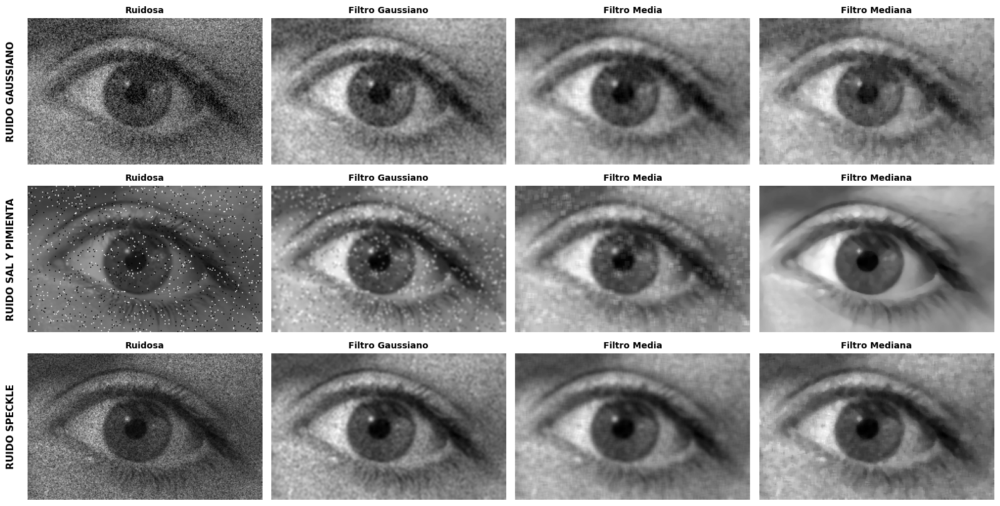


------------------------------------
Histogramas de las imagenes ruidosas
------------------------------------



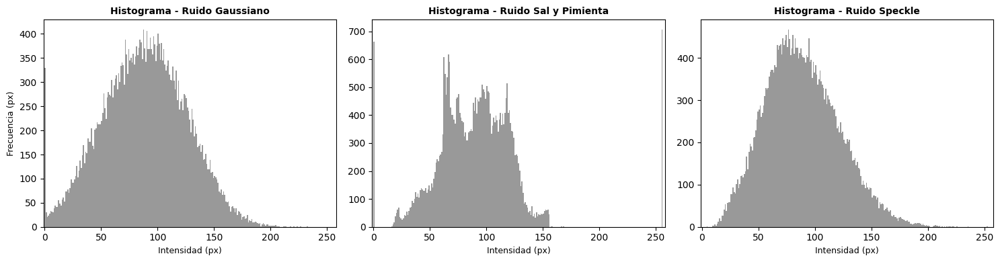

In [ ]:
# 1. FUNCIONES DE RUIDO
def agregar_ruido_gaussiano(imagen):
    # Genera valores aleatorios con distribución normal
    media = 0
    desvio = 25
    ruido = np.random.normal(media, desvio, imagen.shape)
    imagen_ruidosa = imagen.astype(float) + ruido #Ruido aditivo
    return np.clip(imagen_ruidosa, 0, 255).astype(np.uint8)

def agregar_ruido_sal_pimienta(imagen):
    # Asigna píxeles blancos (sal) y negros (pimienta) al azar
    ruido = np.copy(imagen)
    prob_sal = 0.02      # 2% de píxeles blancos
    prob_pimienta = 0.02 # 2% de píxeles negros

    # Matriz aleatoria del mismo tamaño que la imagen
    aleatorio = np.random.rand(*ruido.shape)

    ruido[aleatorio < prob_pimienta] = 0        # Pimienta
    ruido[aleatorio > 1 - prob_sal] = 255       # Sal
    return ruido

def agregar_ruido_speckle(imagen):
    # Ruido multiplicativo
    ruido = np.random.randn(*imagen.shape)
    # Se multiplica por un factor (0.2) para que no destruya la imagen por completo
    imagen_ruidosa = imagen.astype(float) + imagen.astype(float) * ruido * 0.2
    return np.clip(imagen_ruidosa, 0, 255).astype(np.uint8)


# 2. GENERAMOS IMÁGENES RUIDOSAS
# Usamos roi_gris
img_gauss = agregar_ruido_gaussiano(roi_gris)
img_sp = agregar_ruido_sal_pimienta(roi_gris)
img_speckle = agregar_ruido_speckle(roi_gris)

# 3. APLICAMOS FILTROS ESPACIALES
# Aplicamos un kernel de 5x5 a todos para poder compararlos

# Al ruido Gaussiano
gauss_gauss = cv2.GaussianBlur(img_gauss, (5, 5), 0) #(ancho, alto), sigma
gauss_media = cv2.blur(img_gauss, (5, 5)) #(ancho, alto)
gauss_mediana = cv2.medianBlur(img_gauss, 5) #Tamaño del kernel

#Al ruido Speckle
speckle_gauss = cv2.GaussianBlur(img_speckle, (5, 5), 0)
speckle_media = cv2.blur(img_speckle, (5,5))
speckle_mediana = cv2.medianBlur(img_speckle, 5)

#Al ruido Sal y Pimienta
pimienta_gauss = cv2.GaussianBlur(img_sp, (5,5), 0)
pimienta_media = cv2.blur(img_sp, (5,5))
pimienta_mediana = cv2.medianBlur(img_sp, 5)


# 4. GRAFICAR RESULTADOS (3 filas x 4 columnas)
fig1, axs1 = plt.subplots(3, 4, figsize=(16, 12))

# Estructura de datos para iterar
experimentos = [
    {
        "titulo_ruido": "RUIDO GAUSSIANO",
        "imgs": [img_gauss, gauss_gauss, gauss_media, gauss_mediana],
        "titulos": ["Ruidosa", "Filtro Gaussiano", "Filtro Media", "Filtro Mediana"]
    },
    {
        "titulo_ruido": "RUIDO SAL Y PIMIENTA",
        "imgs": [img_sp, pimienta_gauss, pimienta_media, pimienta_mediana],
        "titulos": ["Ruidosa", "Filtro Gaussiano", "Filtro Media", "Filtro Mediana"]
    },
    {
        "titulo_ruido": "RUIDO SPECKLE",
        "imgs": [img_speckle, speckle_gauss, speckle_media, speckle_mediana],
        "titulos": ["Ruidosa", "Filtro Gaussiano", "Filtro Media", "Filtro Mediana"]
    }
]

print("-------------------------------")
print("Suavizado con filtros pasabajos")
print("-------------------------------")

for fila, exp in enumerate(experimentos):
    for col in range(4):
        ax = axs1[fila, col]
        ax.imshow(exp["imgs"][col], cmap="gray")
        ax.set_title(exp["titulos"][col], fontsize=10, fontweight="bold")
        ax.axis("off")

    # Subtítulo identificador del tipo de ruido a la izquierda
    axs1[fila, 0].text(-0.05, 0.5, exp["titulo_ruido"], transform=axs1[fila, 0].transAxes,
                       fontsize=11, fontweight="bold", va="center", ha="right", rotation=90)

plt.subplots_adjust(hspace=-0.7, wspace=0.3)
plt.tight_layout()
plt.show()
print()
print("------------------------------------")
print("Histogramas de las imagenes ruidosas")
print("------------------------------------")
print()

# HISTOGRAMAS DE LAS TRES IMÁGENES RUIDOSAS (1 fila x 3 columnas)
fig2, axs2 = plt.subplots(1, 3, figsize=(15, 4))

ruidosos = [
    ("Histograma - Ruido Gaussiano", img_gauss),
    ("Histograma - Ruido Sal y Pimienta", img_sp),
    ("Histograma - Ruido Speckle", img_speckle)
]

for col, (titulo, img) in enumerate(ruidosos):
    ax = axs2[col]
    ax.hist(img.ravel(), bins=256, range=[0, 256], color="gray", alpha=0.8)
    ax.set_title(titulo, fontsize=10, fontweight="bold")
    ax.set_xlim([-1, 258])
    ax.set_xlabel("Intensidad (px)", fontsize=9)
    if col == 0:
        ax.set_ylabel("Frecuencia (px)", fontsize=9)

plt.tight_layout()
plt.show()

&ensp; En esta celda, lo que hicimos fue simular tres distintos tipos de ruido y se los aplicamos a la ROI en escala de grises para luego filtrarlos con tres modelos de kernel. Los tipos de ruido simulados son:

--> Gaussiano: ruido con distribución de probabilidad Gaussiana, aditivo, cuyo histograma presenta forma de campana de Gauss.

--> Sal y pimienta: tipo de ruido impulsivo, que se caracteriza por la presencia aleatoria de pixeles con intensidades extremas: 0 y 255

--> Speckle: es el ruido característico de las ecografías que se genera por interferencia de haces coherentes, multiplicativo, sigue una ditribución gamma.

&ensp; Estas distribuciones características de cada ruido se pueden observar directamente sobre los histogramas de las imagenes simuladas.

&ensp; Para el filtrado de los ruidos, se utilizaron tres técnicas distintas de suavizado, aplicado mediante kernels de dimensión 5x5 en cada imagen ruidosa:

\\\ Filtro de media //: promedio aritmético entre los pixeles contenidos en el kernel, aplicado con la función **```cv2.blur```**. Es el suavizado o "borroneo" estándar.

\\\ Filtro de mediana //: ordena los pixeles del kernel y toma la mediana, aplicado con la función **```cv2.medianBlur```**. Especialmente efectivo contra el ruido sal y pimienta.

\\\ Filtro Gaussiano //: hace un promedio ponderado de los pixeles del kernel siguiendo una distribución gaussiana en dos dimensiones. Se aplicó con la función **```GaussianBlur```**. Es estándar con una mejor performance frente a ruido Gaussiano.

&ensp; Luego se graficó las tres imágenes con los tres distintos ruidos aplicados, junto con las salidas de los tres filtros recién descripto. Podemos evaluar visualmente (cualitativamente) la performance de estos en el suavizado de las imagenes:

- Para el ruido Gaussiano se observa que el mejor suavizado se produce por su mismo filtro, ya que es el que mejor logra contrarrestar el ruido junto con la filtrada por media, aunque, si vemos con detenimiento, esta última pierde más detalles de los bordes y de los límites de la estructura en general. El filtro de mediana también suaviza el ruido pero es el menos efectivo de los tres porque no logra atenuar el ruido contínuo en zonas homogéneas, dejando un aspecto con grumos, mientras que los otros borronean más los bordes a costa de mantener uniforme las regiones de tonos similares.

- Para el ruido Sal y Pimienta como es de esperar el mejor filtro es el de mediana ya que su valor no se ve afectada por intensidades extremas como la media o un promedio ponderado. A la salida de este, se observa una imagen suave, definida, con bordes marcados, que permite identificar claramente las estructuras y jerarquías presentes en la imagen. El filtro de media le sigue por detrás pues logra suavizar el ruido mejor que el gaussiano aunque en ambos casos este sigue presente en la imagen.

- Para el ruido Speckle los tres kernels tienen un buen desempeño en general porque el ruido se logra reducir considerablemente en las tres imagenes. Las diferencias son sutiles pero prestando atención a cada detalle, podemos decir que el mejor filtro en este caso es el de media porque mantiene la nitidez de los bordes finos y es el que más redujo el ruido a nivel en las zonas contínuas. Esto tiene sentido porque este ruido es muy granulado y al ser el suavizado más fuerte es el mejor para de eliminar los granos, a costa de perder detalles como las pestañas o el borde del iris.

&ensp; En conclusión, la elección del filtro óptimo depende estrictamente de la naturaleza matemática del ruido presente. Existe un compromiso permanente (trade-off) entre la capacidad de atenuación del ruido y la preservación de bordes y frecuencias altas (detalles). Mientras que los filtros lineales (Media y Gaussiano) responden bien ante ruidos continuos aditivos o multiplicativos a costa de difuminar los bordes finos, el filtro no lineal (Mediana) demuestra una superioridad absoluta frente a ruidos de tipo impulsivo, logrando eliminar los artefactos sin degradar la agudeza visual de las estructuras anatómicas del ojo.


###1.3 Detección de Bordes y Dominio Frecuencial ###


***Detección de bordes***

-----------------------------------------
Detección de bordes con filtros pasaaltos
-----------------------------------------


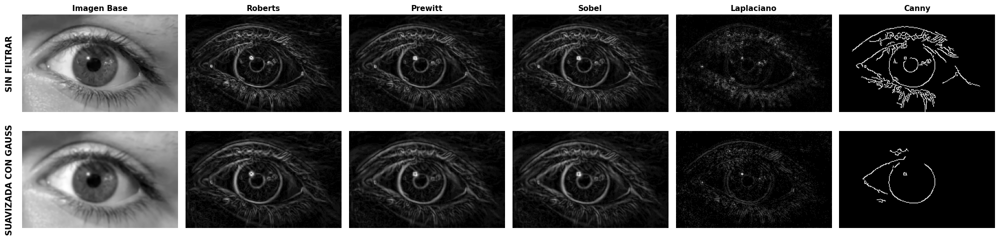


---------------------------------------------------------------
Ahora veamos los resultados aplicando los filtros con librerías
---------------------------------------------------------------



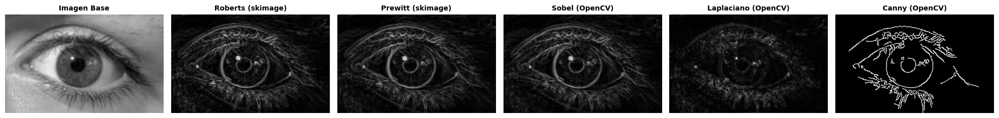

In [ ]:
# --- DEFINICIÓN DE KERNELS MANUALES ---

# Operador de Roberts
kernel_roberts_x = np.array([
    [0, 0, 0],
    [0, 1, 0],
    [0, 0, -1]
], dtype=np.float32)

kernel_roberts_y = np.array([
    [0, 0, 0],
    [0, 0, 1],
    [0, -1, 0]
], dtype=np.float32)

# Operador de Prewitt
kernel_prewitt_y = (1 / 3) * np.array([
    [-1, -1, -1],
    [ 0,  0,  0],
    [ 1,  1,  1]
], dtype=np.float32)

kernel_prewitt_x = (1 / 3) * np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
], dtype=np.float32)

# Operador de Sobel
kernel_sobel_y = (1 / 4) * np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=np.float32)

kernel_sobel_x = (1 / 4) * np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float32)

# Operador Laplaciano
kernel_laplaciano =(1 / 4) * np.array([
    [0, -1, 0],
    [-1, 4, -1],
    [0, -1, 0]
], dtype=np.float32)

# Definimos una función para aplicar los filtros
def aplicar_detectores(img):
    """Aplica las máscaras manuales con cv2.filter2D y combina componentes X/Y."""
    """Las definiciones de los kernels son los vistos en clase"""

    # Roberts
    rx = cv2.filter2D(img, cv2.CV_64F, kernel_roberts_x)
    ry = cv2.filter2D(img, cv2.CV_64F, kernel_roberts_y)
    roberts = cv2.addWeighted(cv2.convertScaleAbs(rx), 0.5, cv2.convertScaleAbs(ry), 0.5, 0)

    # Prewitt
    p_x = cv2.filter2D(img, cv2.CV_64F, kernel_prewitt_x)
    p_y = cv2.filter2D(img, cv2.CV_64F, kernel_prewitt_y)
    prewitt = cv2.addWeighted(cv2.convertScaleAbs(p_x), 0.5, cv2.convertScaleAbs(p_y), 0.5, 0)

    # Sobel
    s_x = cv2.filter2D(img, cv2.CV_64F, kernel_sobel_x)
    s_y = cv2.filter2D(img, cv2.CV_64F, kernel_sobel_y)
    sobel = cv2.addWeighted(cv2.convertScaleAbs(s_x), 0.5, cv2.convertScaleAbs(s_y), 0.5, 0)

    # Laplaciano
    lap = cv2.filter2D(img, cv2.CV_64F, kernel_laplaciano)
    laplaciano = cv2.convertScaleAbs(lap)

    # Canny (Algoritmo)
    canny = cv2.Canny(img, 50, 150)

    return [img, roberts, prewitt, sobel, laplaciano, canny]

# --- APLICAMOS SOBRE LA IMAGEN ORIGINAL Y FILTRADA ---
roi_filtrada = cv2.GaussianBlur(roi_gris, (5, 5), 0)

resultados_original = aplicar_detectores(roi_gris)
resultados_filtrada = aplicar_detectores(roi_filtrada)

print("-----------------------------------------")
print("Detección de bordes con filtros pasaaltos")
print("-----------------------------------------")
# --- GRÁFICOS ---
titulos = ["Imagen Base", "Roberts", "Prewitt", "Sobel", "Laplaciano", "Canny"]
fig, axs = plt.subplots(2, 6, figsize=(20, 5))

for col in range(6):
    # Fila 1, sin filtrado previo
    axs[0, col].imshow(resultados_original[col], cmap="gray")
    axs[0, col].set_title(titulos[col], fontsize=11, fontweight="bold")
    axs[0, col].axis("off")

    # Fila 2, con filtrado previo
    axs[1, col].imshow(resultados_filtrada[col], cmap="gray")
    axs[1, col].axis("off")

axs[0, 0].text(-0.05, 0.5, "SIN FILTRAR", transform=axs[0, 0].transAxes,
               fontsize=12, fontweight="bold", va="center", ha="right", rotation=90)
axs[1, 0].text(-0.05, 0.5, "SUAVIZADA CON GAUSS", transform=axs[1, 0].transAxes,
               fontsize=12, fontweight="bold", va="center", ha="right", rotation=90)

plt.tight_layout()
plt.show()

print()
print("---------------------------------------------------------------")
print("Ahora veamos los resultados aplicando los filtros con librerías")
print("---------------------------------------------------------------")
print()

def aplicar_detectores_libreria(img):
    """Aplica los detectores utilizando funciones de librería de alto nivel."""

    # Roberts (vía skimage.filters)
    # Nota: roberts devuelve valores normalizados float (0.0 a 1.0)
    img_roberts = roberts(img)

    # Prewitt (vía skimage.filters)
    img_prewitt = prewitt(img)

    # Sobel nativo de OpenCV (ksize=3)
    sobel_x = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
    img_sobel = cv2.addWeighted(cv2.convertScaleAbs(sobel_x), 0.5, cv2.convertScaleAbs(sobel_y), 0.5, 0)

    # Laplaciano nativo de OpenCV (ksize=3)
    lap = cv2.Laplacian(img, cv2.CV_64F, ksize=3)
    img_laplaciano = cv2.convertScaleAbs(lap)

    # Canny nativo de OpenCV
    img_canny = cv2.Canny(img, 50, 150)

    return [img, img_roberts, img_prewitt, img_sobel, img_laplaciano, img_canny]

# Probamos sobre la ROI en escala de grises
resultados_libreria = aplicar_detectores_libreria(roi_gris)

# --- GRÁFICOS ---
titulos = ["Imagen Base", "Roberts (skimage)", "Prewitt (skimage)", "Sobel (OpenCV)", "Laplaciano (OpenCV)", "Canny (OpenCV)"]
fig, axs = plt.subplots(1, 6, figsize=(20, 4))

for col in range(6):
    axs[col].imshow(resultados_libreria[col], cmap="gray")
    axs[col].set_title(titulos[col], fontsize=10, fontweight="bold")
    axs[col].axis("off")

plt.tight_layout()
plt.show()

&ensp; En este primer bloque se detectaron los bordes de la imagen mediante distintos filtros y algoritmos aplicados a la ROI en escala de grises. La idea fundamental es que los bordes representan las altas frecuencias espaciales, entendiendo al espectro bidimensional como un mapa que cuantifica la tasa de cambio de intensidad entre píxeles adyacentes. Por ende, las zonas con variaciones abruptas (como contornos y detalles) corresponden a altas frecuencias, mientras que regiones homogéneas corresponden a bajas frecuencias.

&ensp; Para hallar los contornos se aplicaron filtros pasa-altos evaluando cinco alternativas: tres basadas en la primera derivada o gradiente espacial (Roberts, Prewitt y Sobel), una basada en la segunda derivada (Laplaciano), y un algoritmo multietapa (Canny). Los operadores se aplicaron tanto sobre la imagen original como sobre una versión suavizada con un filtro Gaussiano. El suavizado previo busca reducir las variaciones de intensidad de alta frecuencia asociadas al ruido o reflexiones especulares de la iluminación, evitando que se detecten como bordes falsos.Para hallar los contornos se aplicaron filtros pasaaltos evaluando cinco alternativas: tres basadas en la primera derivada o gradiente espacial (Roberts, Prewitt y Sobel), una basada en la segunda derivada (Laplaciano), y un algoritmo multietapa (Canny). Los operadores se aplicaron tanto sobre la imagen original como sobre una versión suavizada con un filtro Gaussiano. El suavizado previo busca reducir las variaciones de intensidad de alta frecuencia asociadas al ruido o reflexiones especulares de la iluminación, evitando que se detecten como bordes falsos.

&ensp; Los filtros de Roberts, Prewitt, Sobel y Laplaciano se implementaron manualmente mediante la definición explícita de sus matrices de kernel y la función **```cv2.filter2D```**.

* **Roberts, Prewitt y Sobel** permitieron detectar los bordes con una fidelidad muy alta, reconstruyendo el contorno pupilar, el iris, los límites de la esclerótica, las pestañas y la cuenca ocular. Los tres presentaron un desempeño similar, con una ligera disminución en el brillo de los bordes en Roberts debido al menor tamaño de su kernel ($2 \times 2$) y menor ponderación energética. La pupila se detectó con precisión, registrando únicamente la interferencia del destello de luz reflejado en la región superior izquierda. En la imagen previa suavización, la respuesta espacial mantuvo la geometría de los contornos pero exhibió un aspecto difuminado, reduciendo el ruido de alta frecuencia a costa de bordes menos nítidos.

* El **Laplaciano**, al ser un operador de segunda derivada, arrojó una respuesta con menor brillo general y bordes más delgados. Si bien preservó la estructura de la pupila, el iris y las pestañas, mostró una alta sensibilidad a variaciones locales. No obstante, logró atenuar el grosor del artefacto del destello de luz en comparación con los filtros de primera derivada, obteniendo trazados más finos pero con un mapa de respuesta menos brillante.

* Por último, se aplicó el algoritmo de detección de bordes de **Canny** con la función **```cv2.Canny```** a la imagen original y la filtrada. En esta ocasión la salida representa una máscara binaria donde los bordes contrastan fuertemente con el forndo, formando contornos y detalles finos. La combinación interna de suavizado Gaussiano, supresión de no-máximos (NMS) y umbralización por histéresis permitió obtener una delimitación limpia y continua del contorno pupilar e iridiano, eliminando casi por completo el ruido de fondo. En este caso, el destello de luz es aun más pequeño aunque no logra eliminarse.

&ensp; Al evaluar qué procedimiento preserva de forma idónea el contorno pupilar minimizando la interferencia de los reflejos especulares (flash), el algoritmo de Canny ofrece el desempeño más equilibrado. Esto se debe a dos etapas de su arquitectura:

--> Supresión de no-máximos (NMS): Adelgaza la respuesta del destello de luz a un contorno de un solo píxel de grosor, evitando que el brillo del reflejo ensanche o deforme la geometría de la pupila.

--> Umbralización por histéresis: Permite conectar los bordes débiles del contorno circular de la pupila mientras descarta picos de ruido aislados.

&ensp; Sin embargo, existe un compromiso técnico: ningún filtro pasaaltos espacial lineal (Sobel, Prewitt, Roberts o Laplaciano) puede eliminar por completo el destello de luz por sí solo. Dado que el borde del reflejo constituye una transición de intensidad real y abrupta (alta frecuencia espacial), los filtros de derivada lo detectan inevitablemente como un contorno válido. Por lo tanto, mientras que Canny minimiza el impacto del destello al delimitarlo de forma delgada y aislada, la eliminación total de este artefacto sin alterar la pupila requiere complementar el filtrado espacial con otras operaciones o técnicas morfológicas.

***Transformada de Fourier 2D***

<<<<<<<<<<<<<<<<<<<<<<<<<<<
Magnitud y fase de la TF 2D
>>>>>>>>>>>>>>>>>>>>>>>>>>>



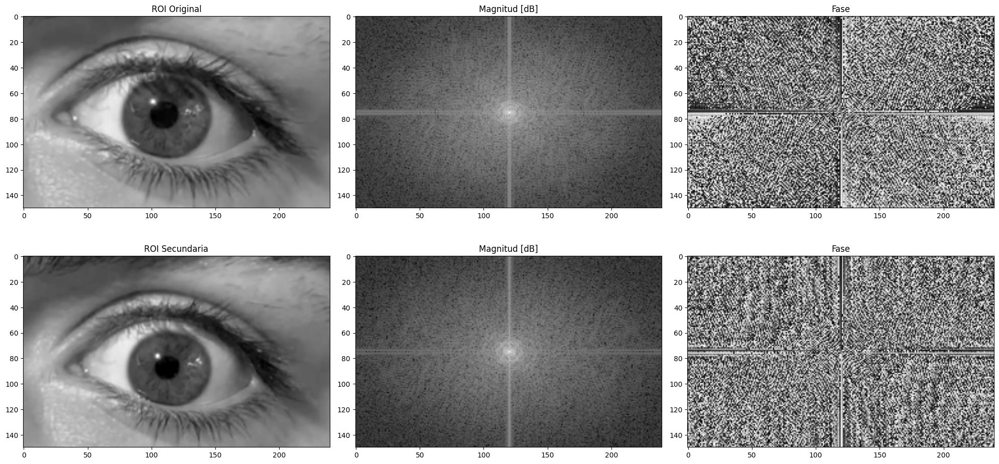


:::::::::::::::::::::::::::::::::::::::
Reconstrucción con transformada inversa
:::::::::::::::::::::::::::::::::::::::



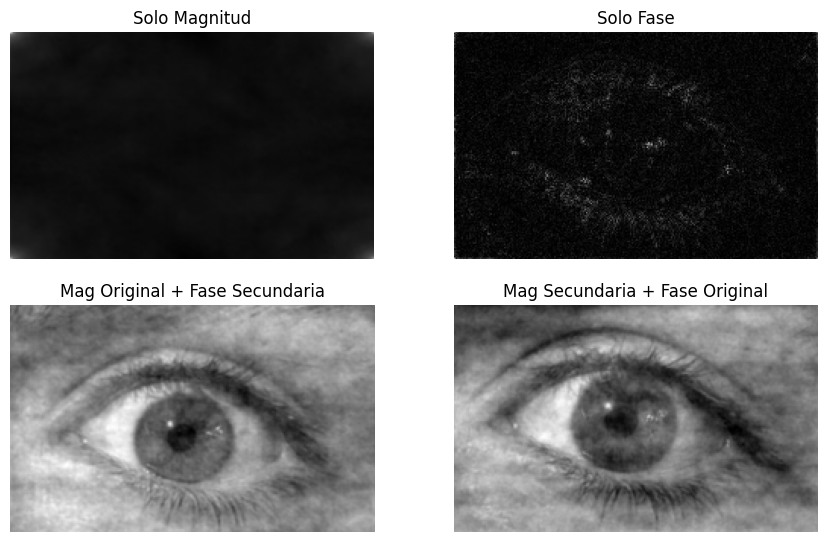

In [ ]:
# Cargamos una segunda imagen y la redimensionamos para que coincida con roi_gris
ruta_fourier = "/content/drive/MyDrive/PSIB - TPs/Guía imágenes/PARTE 1/otro_ojo.png"
img2 = cv2.imread(ruta_fourier, cv2.IMREAD_GRAYSCALE)
img2 = cv2.resize(img2, (roi_gris.shape[1], roi_gris.shape[0]))

# CALCULAMOS TRANSFORMADA (TFD-2D)
# Imagen 1
f1 = np.fft.fft2(roi_gris)
f1_shift = np.fft.fftshift(f1)
mag1 = np.abs(f1_shift)
fase1 = np.angle(f1_shift)

# Imagen 2
f2 = np.fft.fft2(img2)
f2_shift = np.fft.fftshift(f2)
mag2 = np.abs(f2_shift)
fase2 = np.angle(f2_shift)

# RECONSTRUCCIONES INVERSAS
# A. Solo Magnitud (Fase = 0)
solo_mag_complejo = mag1 * np.exp(1j * 0)
recon_solo_mag = np.abs(np.fft.ifft2(np.fft.ifftshift(solo_mag_complejo)))

# B. Solo Fase (Magnitud = 1)
solo_fase_complejo = 1 * np.exp(1j * fase1)
recon_solo_fase = np.abs(np.fft.ifft2(np.fft.ifftshift(solo_fase_complejo)))

# C. Cruzadas
cruzada_mag1_fase2 = mag1 * np.exp(1j * fase2)
recon_cruzada_12 = np.abs(np.fft.ifft2(np.fft.ifftshift(cruzada_mag1_fase2)))

cruzada_mag2_fase1 = mag2 * np.exp(1j * fase1)
recon_cruzada_21 = np.abs(np.fft.ifft2(np.fft.ifftshift(cruzada_mag2_fase1)))

# GRAFICAMOS RESULTADOS
fig, axs = plt.subplots(2, 3, figsize=(20, 10))

print("<<<<<<<<<<<<<<<<<<<<<<<<<<<")
print("Magnitud y fase de la TF 2D")
print(">>>>>>>>>>>>>>>>>>>>>>>>>>>\n")

# Fila 1: Análisis de la imagen original
axs[0, 0].imshow(roi_gris, cmap="gray")
axs[0, 0].set_title("ROI Original")

# Espectro de magnitud en escala logarítmica para que sea visible
axs[0, 1].imshow(20 * np.log(mag1 + 1), cmap="gray")
axs[0, 1].set_title("Magnitud [dB]")

axs[0, 2].imshow(fase1, cmap="gray")
axs[0, 2].set_title("Fase")

axs[1, 0].imshow(img2, cmap="gray")
axs[1, 0].set_title("ROI Secundaria")

axs[1, 1].imshow(20 * np.log(mag2 + 1), cmap = "gray")
axs[1, 1].set_title("Magnitud [dB]")

axs[1, 2].imshow(fase2, cmap = "gray")
axs[1, 2].set_title("Fase")

plt.subplots_adjust(wspace=3, hspace = 2.2)
plt.tight_layout()
plt.show()

# Reconstrucciones
print("\n:::::::::::::::::::::::::::::::::::::::")
print("Reconstrucción con transformada inversa")
print(":::::::::::::::::::::::::::::::::::::::\n")
figs, ax2 = plt.subplots(2, 2, figsize = (10.5, 6.5))

ax2[0,0].imshow(recon_solo_mag, cmap="gray")
ax2[0,0].set_title("Solo Magnitud")

ax2[0,1].imshow(recon_solo_fase, cmap="gray")
ax2[0,1].set_title("Solo Fase")

ax2[1,0].imshow(recon_cruzada_12, cmap="gray")
ax2[1,0].set_title("Mag Original + Fase Secundaria")

ax2[1,1].imshow(recon_cruzada_21, cmap="gray")
ax2[1,1].set_title("Mag Secundaria + Fase Original")

for ax in ax2.ravel():
    ax.axis("off")

&ensp; Lo que hicimos a continuación fue calcular la transformada de Fourier en dos dimensiones de la ROI original y de una ROI extraída de un frame adicional del video, que se buscó que sea parecida a la actual. Para este fin se utilizó la transformada rápida de Fourier en dos dimensiones: **```np.fft.fft2```**. Así, se extrajo la magnitud (valor absoluto) y la fase y se graficaron, la primera en decibeles (escala logarítmica) para facilitar su visualización (tipo diagrama de Bode).

&ensp; La representación en transformada de Fourier de la imagen la descompone en dos matrices:
* La magnitud cuantifica la energía o amplitud presente en cada frecuencia espacial.
* La fase contiene la información del desplazamiento angular de cada frecuencia.

&ensp; Al aplicar la Transformada Inversa de Fourier ($\text{IFFT}$) modificando aisladamente la magnitud o la fase, se evidencia el rol de cada componente:   

$⟶$Solo Magnitud (Fase fija a cero): La reconstrucción pierde completamente la geometría del ojo, generando una mancha amorfa concentrada en el centro. Esto demuestra que la magnitud carece de información posicional.   

$⟶$Solo Fase (Magnitud fija a la unidad): Se preserva de forma nítida la silueta del ojo, las pestañas y el contorno de la pupila. Al ecualizar la magnitud a un valor constante, el contraste espacial se altera (actuando como un filtro que resalta bordes), pero la estructura geométrica permanece intacta.   

$⟶$Cruzamiento Magnitud Original + Fase Secundaria: La imagen reconstruida adopta inconfundiblemente la forma, postura y geometría de la ROI del frame secundario, conservando únicamente el tono o balance de luminancia del original.   

$⟶$Cruzamiento Magnitud Secundaria + Fase Original: La imagen reconstruida refleja con total claridad la estructura del frame original, adoptando únicamente la distribución energética del secundario.   

&ensp; Con este análisis podemos afirmar que la fase es la componente que conserva de manera absoluta la información estructural y geométrica de la imagen.

&ensp; Mientras que la magnitud determina el contenido energético global y la distribución de contraste, la fase gobierna la coherencia espacial. Los bordes, contornos y formas definidas (como el contorno pupilar o iridiano) existen físicamente debido a que múltiples frecuencias espaciales coinciden en fase en un punto determinado. Por este motivo, al intercambiar la fase entre dos imágenes, la escena reconstruida siempre hereda la estructura espacial de la imagen a la cual pertenecía dicha fase.

***Densidad Espectral de Potencia (PSD)***


Densidad Espectral de Potencia - PSD 2D



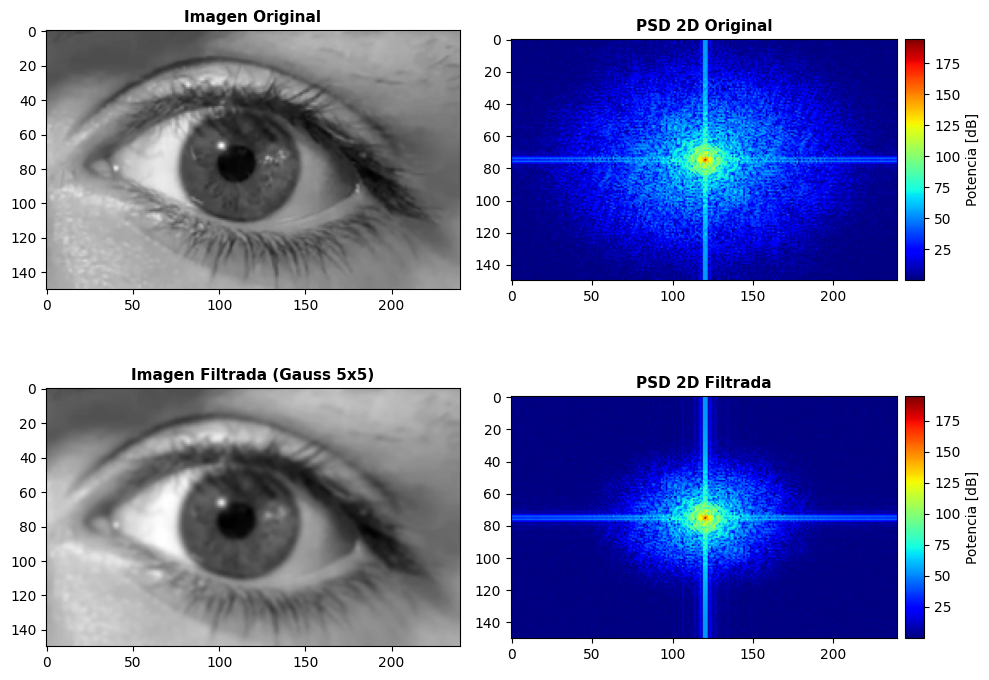


PSD 1D del perfil central



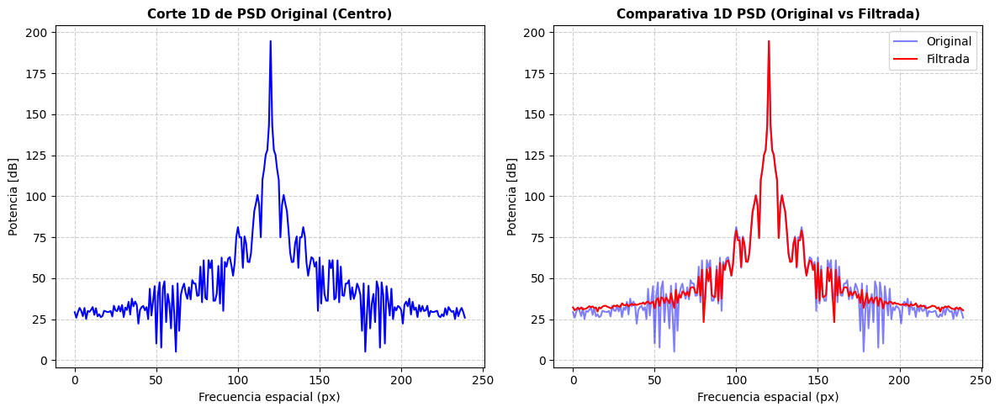

In [ ]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
# Usamos un filtro Gaussiano como ejemplo de filtrado espacial
roi_filtrada = cv2.GaussianBlur(roi_gris, (5, 5), 0)

# Dimensiones de la imagen
N, M = roi_gris.shape
num_pixeles = N * M

# CÁLCULO DE LA PSD (Periodograma 2D)
# Imagen Original
f_orig = np.fft.fftshift(np.fft.fft2(roi_gris))
mag_orig = np.abs(f_orig)
psd_orig = (mag_orig ** 2) / num_pixeles #Potencia=magnitud^2/NxM

# Imagen Filtrada
f_filt = np.fft.fftshift(np.fft.fft2(roi_filtrada))
mag_filt = np.abs(f_filt)
psd_filt = (mag_filt ** 2) / num_pixeles

# Escala logarítmica para visualización 2D
psd_orig_log =10 * np.log(1 + psd_orig)
psd_filt_log =10 * np.log(1 + psd_filt)

# PERFIL 1D CORTANDO EN EL CENTRO DE FRECUENCIAS (Fila central)
centro_y = N // 2
corte_psd_orig = psd_orig_log[centro_y, :]
corte_psd_filt = psd_filt_log[centro_y, :]

# 1. FIGURA 1: COMPARACIÓN 2D (Imágenes y PSDs 2D) - Grilla 2x2
fig1, axs1 = plt.subplots(2, 2, figsize=(10, 7.3))

# --- FILA 1: ORIGINAL ---

print("\n=======================================")
print("Densidad Espectral de Potencia - PSD 2D")
print("=======================================\n")

# Imagen Original
axs1[0, 0].imshow(roi_gris, cmap="gray")
axs[0, 0].set_box_aspect(0.3)
axs1[0, 0].set_title("Imagen Original", fontsize=11, fontweight="bold")

# PSD 2D Original
im1 = axs1[0, 1].imshow(psd_orig_log, cmap="jet")
axs1[0, 1].set_title("PSD 2D Original", fontsize=11, fontweight="bold")

divider1 = make_axes_locatable(axs1[0, 1])
cax1 = divider1.append_axes("right", size="5%", pad=0.08)
fig1.colorbar(im1, cax=cax1, label="Potencia [dB]")

# --- FILA 2: FILTRADA ---
# Imagen Filtrada
axs1[1, 0].imshow(roi_filtrada, cmap="gray", aspect = "equal")
axs1[1, 0].set_title("Imagen Filtrada (Gauss 5x5)", fontsize=11, fontweight="bold")

# PSD 2D Filtrada
im2 = axs1[1, 1].imshow(psd_filt_log, cmap="jet", aspect = "equal")
axs1[1, 1].set_title("PSD 2D Filtrada", fontsize=11, fontweight="bold")

divider2 = make_axes_locatable(axs1[1, 1])
cax2 = divider2.append_axes("right", size="5%", pad=0.08)
fig1.colorbar(im1, cax=cax2, label="Potencia [dB]")

plt.tight_layout()
plt.show()


# FIGURA 2: ANÁLISIS PERFILES 1D - Grilla 1x2
print("\n=========================")
print("PSD 1D del perfil central")
print("=========================\n")
fig2, axs2 = plt.subplots(1, 2, figsize=(12, 5))

# Perfil 1D Original
axs2[0].plot(corte_psd_orig, color="blue", label="Original")
axs2[0].set_title("Corte 1D de PSD Original (Centro)", fontsize=11, fontweight="bold")
axs2[0].set_xlabel("Frecuencia espacial (px)")
axs2[0].set_ylabel("Potencia [dB]")
axs2[0].grid(True, linestyle="--", alpha=0.6)

# Perfiles 1D Comparativa Superpuesta
axs2[1].plot(corte_psd_orig, color="blue", alpha=0.5, label="Original")
axs2[1].plot(corte_psd_filt, color="red", label="Filtrada")
axs2[1].set_title("Comparativa 1D PSD (Original vs Filtrada)", fontsize=11, fontweight="bold")
axs2[1].set_xlabel("Frecuencia espacial (px)")
axs2[1].set_ylabel("Potencia [dB]")
axs2[1].legend(loc="upper right")
axs2[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

&ensp; En este bloque de código se estimó la Densidad Espectral de Potencia (PSD) mediante el método del periodograma normalizado para comparar cuantitativamente la distribución de energía espacial de la ROI original frente a la versión filtrada espacialmente con un núcleo Gaussiano de $5 \times 5$.

Para llevar a cabo la estimación espectral de ambas imágenes se siguieron los siguientes pasos:

1. Transformada de Fourier 2D: Se utilizó la función **```np.fft.fft2```** para obtener la representación espectral compleja $F(u,v)$ de las imágenes de $N \times M$ píxeles.
2. Centrado Espectral: Se aplicó **```np.fft.fftshift```** para trasladar la frecuencia cero (componente de corriente continua o DC) al centro exacto de la matriz $(u_0, v_0) = (N/2, M/2)$.
3. Cálculo de la PSD Normalizada: Se extrajo la magnitud al cuadrado mediante np.abs y se normalizó por el número total de píxeles ($N \cdot M$), representando la densidad espectral de potencia física promedio:$$\text{PSD}(u,v) = \frac{\vert{}F(u,v)\vert{}^2}{N \cdot M}$$
4. Escalamiento Logarítmico en Decibeles: Dado que la componente DC concentra un porcentaje masivo de la energía de la imagen en comparación con las altas frecuencias, el rango dinámico lineal dificulta la observación gráfica. Por ello, se transformó la potencia a escala decibélica mediante la expresión:$$\text{PSD}_{\text{dB}} = 10 \cdot \log_{10}(1 + \text{PSD})$$
Esto comprimió el rango dinámico de la representación visual.  


&ensp; Aunque el mapa $2\text{D}$ permite observar la anisotropía y orientación de las frecuencias en el plano, la inspección visual en falso color dificulta la medición exacta de las diferencias de potencia. Por este motivo, se extrajo una sección transversal $1\text{D}$ que pasa exactamente por la fila central del espectro ($v = v_0$).   Esta simplificación se justifica por las siguientes razones:
- Paso por la Componente DC: Permite verificar que el valor medio de gris (brillo global de la escena) no se haya alterado tras el filtrado.
- Evaluación Directa de la Atenuación: Transforma la matriz $2\text{D}$ en una curva cartesiana donde el eje horizontal representa la distancia en píxeles al centro espectral (frecuencia espacial horizontal $u$) y el eje vertical cuantifica la energía en decibeles, permitiendo evaluar la pendiente de corte del filtro.

<u>Comparación de la Distribución Espectral (Antes y Después del Filtrado) </u>

[ ] **PSD 2D de la Imagen Original**: Muestra una nube de potencia extendida que abarca radios lejanos respecto al centro espectral. Las estructuras finas como las pestañas, la textura del iris y los bordes nítidos de la esclerótica aportan una densidad de energía apreciable en el rango de altas frecuencias.

[ ] **PSD 2D de la Imagen Filtrada** (Gauss $5\times5$): Presenta una notoria contracción de la distribución de energía hacia la región central. Las zonas periféricas del plano frecuencial pierden densidad espectral y toman valores cercanos al fondo nulo.  

&ensp; El filtro Gaussiano espacial opera en la práctica como un filtro pasabajos continuo. La transformada de Fourier de una función Gaussiana en el espacio es también una Gaussiana en el dominio frecuencial. Al convolucionar la ROI con el kernel Gaussiano, el espectro se multiplica por esta envolvente atenuadora:$$\mathcal{F}\{I(x,y) * G(x,y)\} = F(u,v) \cdot \hat{G}(u,v)$$

&ensp; Como resultado, la componente DC permanece prácticamente idéntica (se conserva el nivel medio de iluminación), pero a medida que la frecuencia espacial $u$ se aleja del centro, la energía decae de forma exponencial. Esto demuestra cuantitativamente por qué el suavizado borra los detalles finos en el espacio: las frecuencias responsables de sostener las variaciones rápidas entre píxeles fueron suprimidas en la PSD.   

***Filtrado en frecuencia***

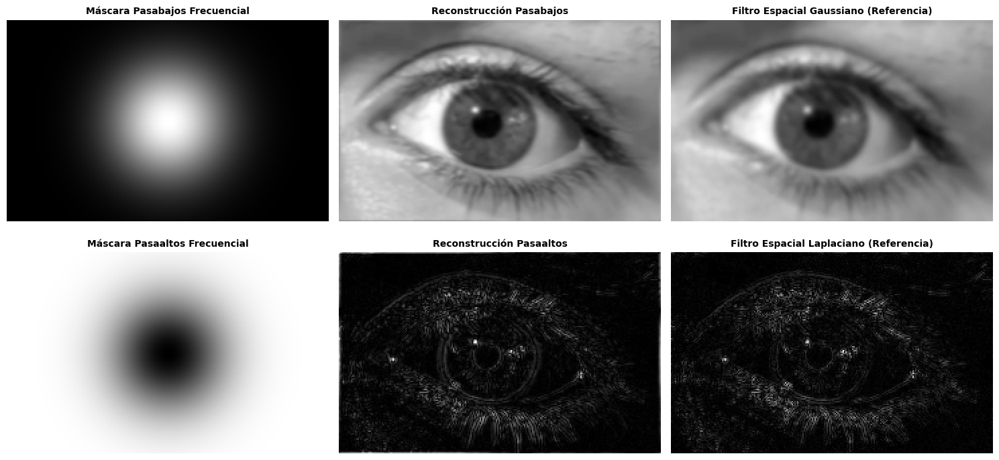


------ MÉTRICAS DE CALIDAD FRENTE A LA ROI ORIGINAL ------

Reconstrucción Pasa-Bajos (Frecuencia) -> PSNR: 38.63 dB | SSIM: 0.9639
Filtrado Espacial Gaussiano (Referencia) -> PSNR: 36.17 dB | SSIM: 0.9187


In [ ]:
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

# 1. TFD-2D Y CENTRADO DE LA IMAGEN
filas, columnas = roi_gris.shape
centro_r, centro_c = filas // 2, columnas // 2

f_shift = np.fft.fftshift(np.fft.fft2(roi_gris)) #Cálculo de fase

# 2. CREAMOS LAS MÁSCARAS DE DISTANCIA AL CENTRO
y, x = np.ogrid[:filas, :columnas]
distancia = np.sqrt((y - centro_r)**2 + (x - centro_c)**2)

# Radio de corte de frecuencia (frecuencia de corte D0)
D0 = 30

# Máscaras de filtros (Usamos filtro Gaussiano frecuencial)
mascara_pasabajos = np.exp(-(distancia**2) / (2 * (D0**2)))
mascara_pasaaltos = 1 - mascara_pasabajos

# 3. APLICAMOS FILTROS EN FRECUENCIA
f_shift_pasabajos = f_shift * mascara_pasabajos
f_shift_pasaaltos = f_shift * mascara_pasaaltos

# 4. RECONSTRUCCIÓN MEDIANTE TRANSFORMADA INVERSA (IFFT)
img_pasabajos_frec = np.abs(np.fft.ifft2(np.fft.ifftshift(f_shift_pasabajos)))
img_pasaaltos_frec = np.abs(np.fft.ifft2(np.fft.ifftshift(f_shift_pasaaltos)))

# 5. FILTRADOS ESPACIALES DE REFERENCIA PARA COMPARAR
img_pasabajos_esp = cv2.GaussianBlur(roi_gris, (9, 9), 0)
img_pasaaltos_esp = cv2.Laplacian(roi_gris, cv2.CV_64F)
img_pasaaltos_esp = np.abs(img_pasaaltos_esp)

# 6. GRAFICAMOS RESULTADOS
fig, axs = plt.subplots(2, 3, figsize=(15, 7.3))

# Fila 1: Pasa-Bajos (Frecuencia vs Espacial)
axs[0, 0].imshow(mascara_pasabajos, cmap="gray")
axs[0, 0].set_title("Máscara Pasabajos Frecuencial", fontsize=10, fontweight="bold")

axs[0, 1].imshow(img_pasabajos_frec, cmap="gray")
axs[0, 1].set_title("Reconstrucción Pasabajos", fontsize=10, fontweight="bold")

axs[0, 2].imshow(img_pasabajos_esp, cmap="gray")
axs[0, 2].set_title("Filtro Espacial Gaussiano (Referencia)", fontsize=10, fontweight="bold")

# Fila 2: Pasa-Altos (Frecuencia vs Espacial)
axs[1, 0].imshow(mascara_pasaaltos, cmap="gray")
axs[1, 0].set_title("Máscara Pasaaltos Frecuencial", fontsize=10, fontweight="bold")

axs[1, 1].imshow(img_pasaaltos_frec, cmap="gray")
axs[1, 1].set_title("Reconstrucción Pasaaltos", fontsize=10, fontweight="bold")

axs[1, 2].imshow(img_pasaaltos_esp, cmap="gray")
axs[1, 2].set_title("Filtro Espacial Laplaciano (Referencia)", fontsize=10, fontweight="bold")

for ax in axs.ravel():
    ax.axis("off")

plt.tight_layout()
plt.show()

# Asegurar que las imágenes reconstruidas estén en formato uint8 (0-255)
img_pasabajos_frec_u8 = np.clip(img_pasabajos_frec, 0, 255).astype(np.uint8)
img_pasabajos_esp_u8 = np.clip(img_pasabajos_esp, 0, 255).astype(np.uint8)

# 1. Cálculo de métricas para Pasa-Bajos Frecuencial
psnr_frec = psnr(roi_gris, img_pasabajos_frec_u8, data_range=255)
ssim_frec = ssim(roi_gris, img_pasabajos_frec_u8, data_range=255)

# 2. Cálculo de métricas para Pasa-Bajos Espacial (Gaussiano)
psnr_esp = psnr(roi_gris, img_pasabajos_esp_u8, data_range=255)
ssim_esp = ssim(roi_gris, img_pasabajos_esp_u8, data_range=255)

# Mostrar resultados
print(f"\n------ MÉTRICAS DE CALIDAD FRENTE A LA ROI ORIGINAL ------\n")
print(f"Reconstrucción Pasa-Bajos (Frecuencia) -> PSNR: {psnr_frec:.2f} dB | SSIM: {ssim_frec:.4f}")
print(f"Filtrado Espacial Gaussiano (Referencia) -> PSNR: {psnr_esp:.2f} dB | SSIM: {ssim_esp:.4f}")

&ensp; En esta última parte lo que hicimos fue definir un filtro pasaaltos y uno pasabajos en el dominio frecuencial para luego aplicarlo sobre el espectro de la imagen y reconstruir desde el dominio frecuencial al dominio espacial las salidas. Lo primero que hicimos fue definir un filtro Gaussiano en frecuencia obteniendo la distribución que se observa en la máscara pasabajos, mientras que el pasaaltos se definió como 1-pasabajos. Así, se multiplicaron las máscaras componente a componente con el espectro de Fourier y se aplicó la transformada inversa para observarlas en el dominio espacial. Esta multiplicación elemento a elemento en frecuencia equivale a una convolución en el espacio. Luego, mediante **```np.fft.ifftshift```** y **```np.fft.ifft2```**, se obtuvo la parte real de la señal reconstruida.

$⇒$ Respecto a la reconstrucción de la imagen luego de pasar por el Gaussiano en frecuencia, se obtuvo una foto borrosa pero con estructuras distinguibles bien definidas. Al compararla con la imagen filtrada espacialmente, se ve que la filtrada en frecuencia queda bastante menos borrosa, conservando más nitidez en general, y una mejor definición de bordes en particular. Esta diferencia en el grado de suavizado se debe a que el radio de corte $D_0$ elegido en frecuencia retuvo un ancho de banda mayor que la ventana del kernel Gaussiano espacial ($9 \times 9$), el cual trunca espacialmente la función atenuando más agresivamente las frecuencias intermedias.

$⇒$ La salida reconstruida del pasaaltos es capaz de replicar los bordes de las estructuras presentes con más precisión que Laplace pues en la filtrada en frecuencia los límites entre estructuras quedan más definidos y se perciben algunos detalles más finos. Esto se debe a que el Laplaciano espacial opera mediante un kernel discreto restringido ($3 \times 3$) que atenúa fuertemente la magnitud de la respuesta, mientras que la máscara frecuencial Gaussiana actúa como un filtro global continuo que atenúa únicamente el centro (DC) y preserva la continuidad de todas las altas frecuencias periféricas.

---------------------------------------------------------------------------
&ensp; Para evaluar el impacto de los procesamientos espaciales y frecuenciales sobre la imagen original, la inspección visual resulta insuficiente. Para medir de forma objetiva la degradación o preservación de la información se utilizan dos métricas estándar:
* PSNR (Peak Signal-to-Noise Ratio): Mide la relación entre la máxima potencia posible de la señal y la potencia del ruido o error introducido por el filtrado. Se calcula a partir del Error Cuadrático Medio ($\text{MSE}$) en decibeles ($\text{dB}$):$$\text{MSE} = \frac{1}{N \cdot M} \sum_{x=0}^{N-1} \sum_{y=0}^{M-1} [I(x,y) - K(x,y)]^2$$$$\text{PSNR} = 10 \cdot \log_{10} \left( \frac{\text{MAX}_I^2}{\text{MSE}} \right) \quad [\text{dB}]$$Un valor más alto de $\text{PSNR}$ indica que la imagen procesada mantiene menor desviación radiométrica punto a punto respecto a la original.

* SSIM (Structural Similarity Index): Evalúa la fidelidad percibida ponderando tres componentes independientes: luminancia ($l$), contraste ($c$) y estructura ($s$):$$\text{SSIM}(x,y) = [l(x,y)]^\alpha \cdot [c(x,y)]^\beta \cdot [s(x,y)]^\gamma$$Su valor oscila entre $-1$ y $1$ (donde $1$ representa identidad estructural perfecta). A diferencia del $\text{PSNR}$, el $\text{SSIM}$ captura la coherencia de bordes y patrones espaciales, correlacionando mejor con la percepción visual humana.

<u> Discusión de valores obtenidos </u>

>Similitud Estructural ($\text{SSIM} = 0.9639$ vs. $0.9187$): El filtro frecuencial supera al espacial por cerca de $0.045$ puntos. Este incremento confirma cuantitativamente que la máscara Gaussiana continua en frecuencia ($D_0$), al actuar globalmente sobre todo el espectro y carecer del truncamiento de bordes propio de una ventana o kernel discreto espacial ($5 \times 5$), preserva con mayor fidelidad la coherencia de fase, la geometría circular de la pupila y el contraste del iris.

>Fidelidad Radiométrica ($\text{PSNR} = 38.63\text{ dB}$ vs. $36.17\text{ dB}$):La reconstrucción frecuencial obtiene una ganancia de $+2.46\text{ dB}$ sobre el filtro Gaussiano espacial. Un valor de $\text{PSNR}$ superior a $38\text{ dB}$ representa una reconstrucción de muy alta fidelidad con un Error Cuadrático Medio ($\text{MSE}$) reducido, lo que indica que el nivel medio de iluminación (componente DC) y las variaciones de intensidad globales sufrieron menor distorsión que en la convolución espacial.

## MÓDULO 2: Segmentación y Morfología Matemática de la Pupila  

In [ ]:
#Imports
from skimage.segmentation import active_contour, watershed
from skimage.filters import gaussian, sobel
from skimage.draw import polygon, ellipse
from skimage.morphology import skeletonize
from sklearn.cluster import KMeans
from scipy import ndimage as ndi

### 2.1 Algoritmos de Segmentación ###


***Preprocesamiento y localización de la pupila***

Centro aproximado de la pupila en la ROI: (x=110, y=75)
Tamaño de la sub-ROI de trabajo: 90x90 px


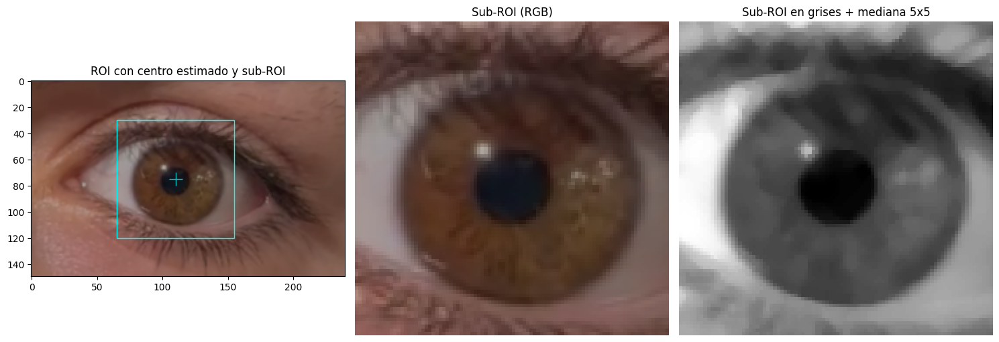

In [ ]:
# Trabajamos sobre la ROI del ojo en escala de grises definida en el Módulo 1 (roi_gris)
# Aplicamos un filtro de mediana para atenuar el reflejo del flash y las pestañas finas sin borronear el borde pupilar
roi_filtrada = cv2.medianBlur(roi_gris, 5)

# Localización automática aproximada de la pupila:
# con un suavizado gaussiano fuerte las estructuras finas oscuras (pestañas) se diluyen
# y el mínimo de intensidad queda dentro del disco pupilar
roi_suavizada = cv2.GaussianBlur(roi_gris, (0, 0), sigmaX=7)
_, _, (cx, cy), _ = cv2.minMaxLoc(roi_suavizada)   # minMaxLoc devuelve (min, max, pos_min, pos_max)

# Sub-ROI centrada en la pupila (incluye pupila, iris y parte de la esclerótica)
semilado = 45
y0, y1 = max(cy - semilado, 0), min(cy + semilado, roi_gris.shape[0])
x0, x1 = max(cx - semilado, 0), min(cx + semilado, roi_gris.shape[1])

iris_gris = roi_filtrada[y0:y1, x0:x1]
iris_rgb = roi[y0:y1, x0:x1]
cx_l, cy_l = cx - x0, cy - y0   # centro de la pupila en coordenadas de la sub-ROI

print(f"Centro aproximado de la pupila en la ROI: (x={cx}, y={cy})")
print(f"Tamaño de la sub-ROI de trabajo: {iris_gris.shape[1]}x{iris_gris.shape[0]} px")

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(roi)
axs[0].plot(cx, cy, "c+", markersize=15)
axs[0].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color="cyan"))
axs[0].set_title("ROI con centro estimado y sub-ROI")

axs[1].imshow(iris_rgb)
axs[1].set_title("Sub-ROI (RGB)")
axs[1].axis("off")

axs[2].imshow(iris_gris, cmap="gray")
axs[2].set_title("Sub-ROI en grises + mediana 5x5")
axs[2].axis("off")
plt.tight_layout()
plt.show()

&ensp;Antes de segmentar se acondicionó la imagen. Se partió de la ROI en escala de grises del Módulo 1 y se le aplicó un filtro de mediana de 5x5, ya que en el módulo anterior se observó que es el que mejor elimina valores impulsivos (como el destello del flash) conservando los bordes. Luego, para que el algoritmo no dependa de coordenadas elegidas a mano, se localizó la pupila de forma automática: se suavizó fuertemente la imagen con un filtro gaussiano de forma tal que las estructuras finas y oscuras como las pestañas se "diluyan" con su entorno, mientras que la pupila, al ser un disco oscuro de mayor tamaño, sigue siendo la región de mínima intensidad. La posición de ese mínimo se tomó como centro aproximado de la pupila.

&ensp;Por último, se recortó una sub-ROI centrada en dicho punto que contiene la pupila, el iris y parte de la esclerótica. Esto reduce la presencia de pestañas, cejas y sombras de los párpados, que de otro modo serían confundidas con la pupila por los métodos basados en intensidad.

***Umbralización automática de Otsu***

Umbral de Otsu global: 81
Umbrales en cada pasada: [81, 50, 33]
Solidez de la máscara final: 0.968


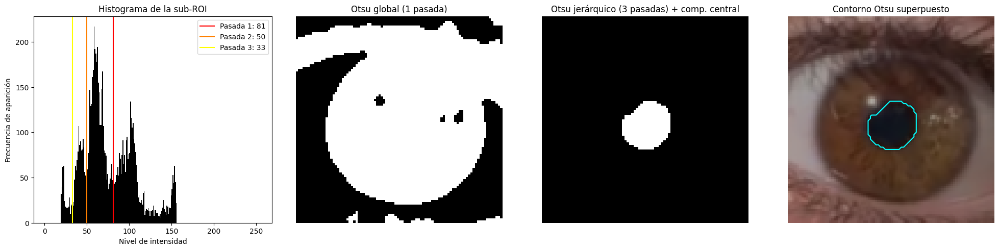

In [ ]:
# Función auxiliar: nos quedamos con la componente conexa que contiene (o está más cerca de) el centro de la pupila
def componente_central(mascara, centro):
    n, etiquetas = cv2.connectedComponents(mascara.astype(np.uint8))
    if n <= 1:
        return mascara.astype(bool)
    x, y = centro
    etiqueta = etiquetas[y, x]
    if etiqueta == 0:  # si el centro cae en el fondo, tomamos la componente más cercana
        dist = ndi.distance_transform_edt(etiquetas == 0, return_indices=True)[1]
        etiqueta = etiquetas[dist[0][y, x], dist[1][y, x]]
    return etiquetas == etiqueta

# Solidez = Área / Área de la envolvente convexa. Para un disco (pupila) es ~1;
# si la región oscura "se escapa" hacia sombras o pestañas, la forma se vuelve irregular y la solidez baja
def solidez(mascara):
    contornos, _ = cv2.findContours(mascara.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    c = max(contornos, key=cv2.contourArea)
    area_hull = cv2.contourArea(cv2.convexHull(c))
    return cv2.contourArea(c) / area_hull if area_hull > 0 else 0

# Otsu jerárquico: en cada pasada se recalcula el umbral de Otsu usando solo los píxeles
# que quedaron por debajo del umbral anterior (la clase oscura), hasta que la región central sea compacta
def otsu_jerarquico(imagen, centro, solidez_min=0.9, max_pasadas=4):
    umbrales = []
    pixeles = imagen.ravel()
    for _ in range(max_pasadas):
        u, _ = cv2.threshold(pixeles.reshape(-1, 1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        umbrales.append(u)
        mascara = componente_central(imagen <= u, centro)
        if len(umbrales) >= 2 and solidez(mascara) >= solidez_min:
            break
        pixeles = imagen[imagen <= u]
    return mascara, umbrales

# Otsu clásico (una pasada): elige el umbral que maximiza la varianza entre clases del histograma
umbral_otsu, _ = cv2.threshold(iris_gris, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
mascara_otsu_cruda = iris_gris <= umbral_otsu    # la pupila (oscura) queda en 1

mascara_otsu, umbrales_otsu = otsu_jerarquico(iris_gris, (cx_l, cy_l))
umbral_otsu_final = umbrales_otsu[-1]

print(f"Umbral de Otsu global: {umbral_otsu:.0f}")
print(f"Umbrales en cada pasada: {[int(u) for u in umbrales_otsu]}")
print(f"Solidez de la máscara final: {solidez(mascara_otsu):.3f}")

fig, axs = plt.subplots(1, 4, figsize=(20, 5))
axs[0].hist(iris_gris.ravel(), bins=256, range=[0, 256], color="black")
for k, u in enumerate(umbrales_otsu):
    axs[0].axvline(u, color=plt.cm.autumn(k / max(len(umbrales_otsu) - 1, 1)), label=f"Pasada {k + 1}: {u:.0f}")
axs[0].set_title("Histograma de la sub-ROI")
axs[0].set_xlabel("Nivel de intensidad")
axs[0].set_ylabel("Frecuencia de aparición")
axs[0].legend()

axs[1].imshow(mascara_otsu_cruda, cmap="gray")
axs[1].set_title("Otsu global (1 pasada)")
axs[1].axis("off")

axs[2].imshow(mascara_otsu, cmap="gray")
axs[2].set_title(f"Otsu jerárquico ({len(umbrales_otsu)} pasadas) + comp. central")
axs[2].axis("off")

axs[3].imshow(iris_rgb)
axs[3].contour(mascara_otsu, levels=[0.5], colors="cyan")
axs[3].set_title("Contorno Otsu superpuesto")
axs[3].axis("off")
plt.tight_layout()
plt.show()


&ensp;El método de Otsu busca de forma automática el umbral que maximiza la varianza entre las dos clases en las que divide el histograma (divide los píxeles en dos grupos, los claros y los oscuros). Al aplicarlo directamente sobre la sub-ROI, el histograma presenta más de dos modos (pupila, iris, esclerótica/piel), por lo que el umbral global tiende a separar las regiones oscuras (pupila + iris) de las claras (esclerótica y piel), y no la pupila del iris.

&ensp; Para resolverlo se aplicó Otsu de forma jerárquica: en cada pasada el umbral se recalcula únicamente con los píxeles clasificados como oscuros en la anterior, de modo que la división pase a ser pupila vs iris. Además, la parte superior del iris queda oscurecida por la sombra del párpado y las pestañas, por lo que en la segunda pasada la región puede seguir "escapándose" hacia arriba. Como criterio de corte se usó la solidez (área de la región sobre el área de su envolvente convexa): la pupila es aproximadamente un disco (solidez cercana a 1), mientras que una región contaminada por sombras tiene una forma irregular. Se siguen haciendo pasadas hasta que la solidez supere 0,9. En todos los casos se conservó solo la componente conexa que contiene el centro estimado de la pupila, descartando píxeles sueltos de pestañas o sombras.

***Agrupamiento K-Means***

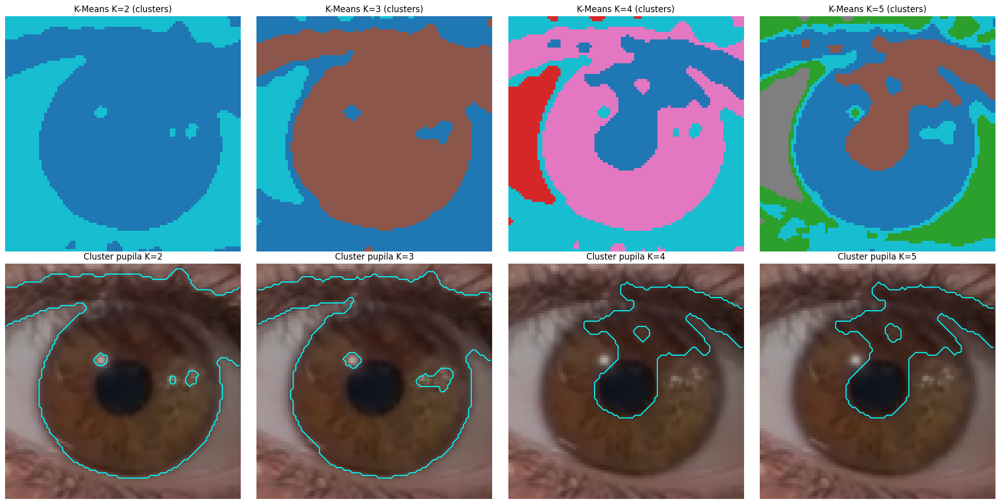

In [ ]:
# Espacio croma/intensidad: usamos CIE L*a*b* (L = luminancia, a y b = cromaticidad)
iris_lab = cv2.cvtColor(cv2.medianBlur(iris_rgb, 5), cv2.COLOR_RGB2LAB)
caracteristicas = iris_lab.reshape(-1, 3).astype(float)

mascaras_kmeans = {}
fig, axs = plt.subplots(2, 4, figsize=(20, 10))
for i, K in enumerate(range(2, 6)):
    km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(caracteristicas)
    etiquetas = km.labels_.reshape(iris_gris.shape)

    # El cluster de la pupila es el de menor luminancia media (L)
    cluster_pupila = np.argmin(km.cluster_centers_[:, 0])
    mascaras_kmeans[K] = componente_central(etiquetas == cluster_pupila, (cx_l, cy_l))

    axs[0, i].imshow(etiquetas, cmap="tab10")
    axs[0, i].set_title(f"K-Means K={K} (clusters)")
    axs[0, i].axis("off")

    axs[1, i].imshow(iris_rgb)
    axs[1, i].contour(mascaras_kmeans[K], levels=[0.5], colors="cyan")
    axs[1, i].set_title(f"Cluster pupila K={K}")
    axs[1, i].axis("off")
plt.tight_layout()
plt.show()

&ensp;El metodo k-means agrupa los pixeles en clusters, asignando cada pixel al centroide mas cercano, luego se recalcula los centroides de forma iterativa hasta converger.

&ensp;Con K=2 se observa un resultado muy similar al otsu global, ya que se divide en dos clusters. Un cluster agrupa las regiones claras y el otro agrupa clusters oscuros. Por esto se ve en el resultado que el contorno es el limbo esclerocorneal y no el borde de la pupila. Dentro de esta región aparecen pequeños huecos que corresponden al reflejo del flash y a las zonas más claras del iris, que por su brillo quedaron asignados al cluster claro.

&ensp;Con K=3 el cluster agregado sirve para separar la región clara, dividiendo la esclerotica de la piel. Se observa que el lado izquierdo de la esclerotica queda en el cluster junto a la piel, por la sombra que tiene la imagen. Como la pupila y el iris siguen formando parte del mismo cluster, la mascara no posee cambios significativos de K=2.

&ensp;Con K=4 el iris empieza a tener un cluster propio. Sin embargo el cluster mas oscuro que es donde esta contenida la pupila, no se delimita a esta, sino que incorpora una parte más oscura del iris que sea da por la sombra de las pestañas y el parpado. Este mismo comportamiento se observa con K=5, si bien hay un nuevo cluster la pupila sigue unida a la parte más oscura del iris.

&ensp;Esto evidencia la principal limitación del método: K-Means agrupa únicamente por similitud en el espacio de características (intensidad y color) y no considera la posición de los píxeles. La sombra del párpado tiene una luminancia y una cromaticidad muy similares a las de la pupila, por lo que, sin información espacial, ambas regiones resultan indistinguibles para el algoritmo, independientemente del número de clusters. Aumentar K no resuelve el problema, sino que fragmenta regiones homogéneas como la esclerótica o el iris.


***Contornos activos (Snakes)***

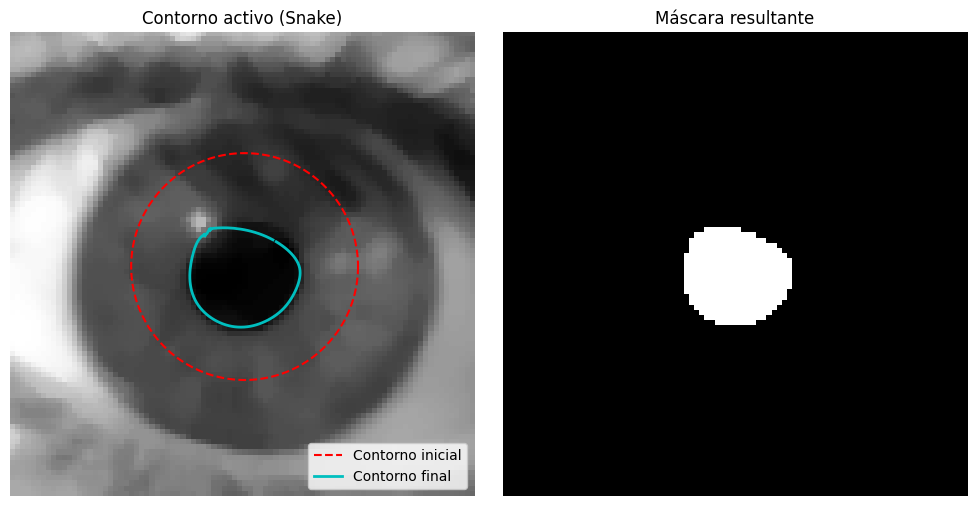

In [ ]:
# Contorno inicial: círculo centrado en la pupila con radio mayor al de la pupila
radio_inicial = 22
t = np.linspace(0, 2 * np.pi, 200)
snake_inicial = np.array([cy_l + radio_inicial * np.sin(t),
                          cx_l + radio_inicial * np.cos(t)]).T   # skimage usa coordenadas (fila, columna)

# Imagen suavizada para que el gradiente "atraiga" al contorno desde más lejos
imagen_snake = gaussian(iris_gris, sigma=2, preserve_range=False)

# alpha: elasticidad (longitud), beta: rigidez (curvatura) -> fuerzas internas
# w_line, w_edge: atracción a intensidad / bordes -> fuerzas externas; gamma: paso temporal
snake = active_contour(imagen_snake, snake_inicial,
                       alpha=0.015, beta=10, gamma=0.001,
                       w_line=0, w_edge=1, max_num_iter=2500)

# Pasamos el contorno a máscara binaria
mascara_snake = np.zeros(iris_gris.shape, dtype=bool)
rr, cc = polygon(snake[:, 0], snake[:, 1], iris_gris.shape)
mascara_snake[rr, cc] = True

fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(iris_gris, cmap="gray")
axs[0].plot(snake_inicial[:, 1], snake_inicial[:, 0], "--r", label="Contorno inicial")
axs[0].plot(snake[:, 1], snake[:, 0], "-c", linewidth=2, label="Contorno final")
axs[0].set_title("Contorno activo (Snake)")
axs[0].legend(loc="lower right")
axs[0].axis("off")

axs[1].imshow(mascara_snake, cmap="gray")
axs[1].set_title("Máscara resultante")
axs[1].axis("off")
plt.tight_layout()
plt.show()

&ensp;Los contornos activos (snakes) representan el borde buscado como una curva cerrada que se deforma iterativamente hasta ajustarse a él. Las fuerzas internas dependen de la forma de la curva: la elasticidad (α) tiende a contraerla y la rigidez (β) la mantiene suave. Las fuerzas externas provienen de la imagen y la atraen hacia los bordes, donde el gradiente es máximo. El contorno converge cuando ambas se equilibran.

&ensp; Se inicializó la curva como un círculo de radio 22 px que rodea la pupila, para que al contraerse se detenga en la frontera pupila–iris. Previamente se suavizó la imagen con un filtro gaussiano para atenuar bordes que no corresponden a la estructura que se quiere segmentar, como la textura del iris o el ruido, que podrían retener a la curva antes de llegar al borde real.

&ensp;  Como se observa, el contorno se contrae hasta converger sobre el borde pupilar y genera una máscara compacta, sin huecos y sin incorporar la sombra del párpado ni las pestañas, a diferencia de lo ocurrido con K-Means. Esto se debe a que el snake no clasifica píxeles por intensidad, sino que busca un borde cerrado y suave, por lo que la restricción de forma impuesta por las fuerzas internas impide que la curva se extienda hacia regiones irregulares. La única desviación aparece en el sector superior izquierdo, donde el gradiente intenso del reflejo corneal atrae al contorno y forma un vértice, por lo que la máscara pierde allí la forma circular.

&ensp; Como desventaja, el método depende fuertemente de la inicialización y de los parámetros elegidos, y es el más costoso computacionalmente, lo cual es relevante al extenderlo a todos los frames del video.


***Watershed (Cuenca hidrográfica)***

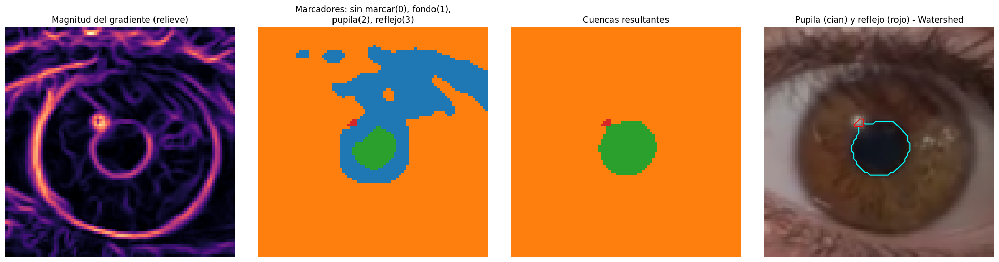

In [ ]:
# Imagen de relieve: magnitud del gradiente (Sobel). Los bordes son las "crestas" entre cuencas
gradiente = sobel(iris_gris.astype(float) / 255)

# Marcadores (semillas de inundación)
marcadores = np.zeros(iris_gris.shape, dtype=np.int32)
# 1: fondo -> todo lo claramente más claro que la pupila (iris, esclerótica, piel)
zona_borde = cv2.dilate(mascara_otsu.astype(np.uint8), np.ones((7, 7))) > 0   # franja sin marcar alrededor de la pupila
marcadores[(iris_gris > umbrales_otsu[1]) & ~zona_borde] = 1
# 2: núcleo de la pupila -> máscara de Otsu erosionada (seguro dentro de la pupila)
marcadores[cv2.erode(mascara_otsu.astype(np.uint8), np.ones((5, 5))) > 0] = 2

# 3: reflejo corneal -> top-hat blanco sobre la sub-ROI SIN filtrar
# (resalta objetos chicos y brillantes respecto de su entorno), restringido a la zona de la pupila
iris_sin_filtrar = roi_gris[y0:y1, x0:x1]
top_hat = cv2.morphologyEx(iris_sin_filtrar, cv2.MORPH_TOPHAT, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9)))
cerca_pupila = cv2.dilate(mascara_otsu.astype(np.uint8), np.ones((9, 9))) > 0
reflejo = (top_hat > 40) & cerca_pupila
marcadores[reflejo] = 3

etiquetas_ws = watershed(gradiente, marcadores)
mascara_ws_sin_reflejo = etiquetas_ws == 2
cuenca_reflejo = etiquetas_ws == 3
# Pupila final: se reincorpora el reflejo (que está "dentro" de la pupila) y se rellenan huecos
mascara_ws = ndi.binary_fill_holes(mascara_ws_sin_reflejo | cuenca_reflejo)

fig, axs = plt.subplots(1, 4, figsize=(20, 5))
axs[0].imshow(gradiente, cmap="magma")
axs[0].set_title("Magnitud del gradiente (relieve)")
axs[0].axis("off")

axs[1].imshow(marcadores, cmap="tab10", vmin=0, vmax=9)
axs[1].set_title("Marcadores: sin marcar(0), fondo(1),\npupila(2), reflejo(3)")
axs[1].axis("off")

axs[2].imshow(etiquetas_ws, cmap="tab10", vmin=0, vmax=9)
axs[2].set_title("Cuencas resultantes")
axs[2].axis("off")

axs[3].imshow(iris_rgb)
axs[3].contour(mascara_ws, levels=[0.5], colors="cyan")
if cuenca_reflejo.any():
    axs[3].contour(cuenca_reflejo, levels=[0.5], colors="red")
axs[3].set_title("Pupila (cian) y reflejo (rojo) - Watershed")
axs[3].axis("off")
plt.tight_layout()
plt.show()

&ensp; Watershed interpreta la imagen como un relieve topográfico, en el que se utilizó como altura la magnitud del gradiente: las regiones homogéneas son valles y los bordes son crestas.

&ensp; Si se inundara la imagen desde todos sus valles, se obtendría una gran cantidad de regiones pequeñas que sería difícil identificar. Para evitarlo, se le indicó al algoritmo desde dónde comenzar a inundar, en tres zonas conocidas: el fondo (todo lo que es claramente más claro que la pupila), el centro de la pupila y el reflejo del flash, que se identificó como un punto pequeño mucho más brillante que su entorno. Alrededor de la pupila se dejó una franja, para que el algoritmo decida dónde está el borde según el relieve de la imagen.

 &ensp; En el mapa de gradiente se distinguen con claridad el anillo del borde pupilar y el del reflejo, y la inundación separa ambas estructuras en cuencas propias. La pupila resulta una región compacta y aproximadamente circular, sin incorporar la sombra del párpado, y el reflejo queda aislado en su propia cuenca, por lo que puede excluirse o reincorporarse a la máscara según convenga. Esto resuelve la desviación observada en el snake, donde el reflejo deformaba el contorno.

&ensp; Como desventaja, el resultado depende de la calidad de los marcadores, que en este caso se obtuvieron a partir de Otsu, por lo que un error en la umbralización se propaga a la segmentación.


***Comparación de los
métodos de segmentación***

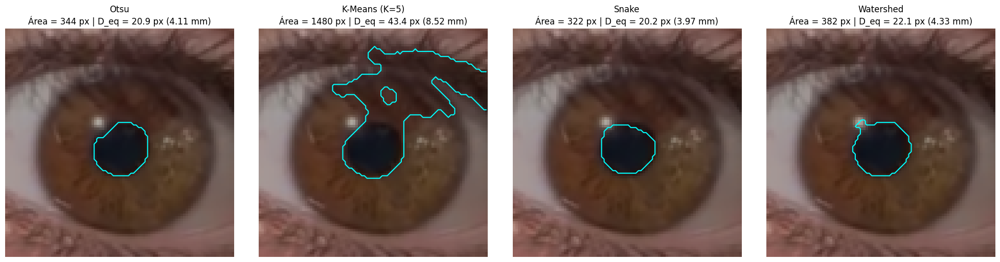

In [ ]:
K_elegido = 5   # cambiar según lo observado en K-Means
mascaras = {
    "Otsu": mascara_otsu,
    f"K-Means (K={K_elegido})": mascaras_kmeans[K_elegido],
    "Snake": mascara_snake,
    "Watershed": mascara_ws,
}

fig, axs = plt.subplots(1, 4, figsize=(20, 5))
for ax, (nombre, m) in zip(axs, mascaras.items()):
    ax.imshow(iris_rgb)
    ax.contour(m, levels=[0.5], colors="cyan")
    diametro_eq = 2 * np.sqrt(m.sum() / np.pi)
    ax.set_title(f"{nombre}\nÁrea = {m.sum()} px | D_eq = {diametro_eq:.1f} px ({diametro_eq * lado_pixel * 10:.2f} mm)")
    ax.axis("off")
plt.tight_layout()
plt.show()

&ensp;En la figura se observan 4 imágenes con el contorno sobre esta. Se informan además 3 valores importantes para la comparación; área, diámetro equivalente y el diámetro multiplicado por el tamaño de píxel.

&ensp;Analizando estos valores se ven dos grupos, K-means tiene datos completamente distintos, mientras que Otsu, Snake y Watershed coinciden entre sí. K-means presenta un área 4 veces mayor a los otros métodos. Esto sucede porque el contorno no solo incluye la pupila, sino que también la parte más oscura del iris (análisis realizado en el punto correspondiente). Los otros tres métodos tienen un diámetro similar, lo que muestra que todos encontraron el mismo borde.


&ensp; Snake da el menor valor, pues la elasticidad tiene a contraer el contorno todo el tiempo. El contorno se frena donde el gradiente es suficiente para compensar esa fuerza, que puede estar levemente por dentro del borde real. Otsu da el valor intermedio, el borde de la pupila no es un salto abrupto, sino una transición de píxeles que van de marrón a más oscuro, el borde está en el medio de esta transición. Por último watershed da el mayor valor  esto es porque el borde lo define la cresta del gradiente, que se ubica en el punto de cambio más rápido de la transición y además se agrega el destello en la pupila y al estar afuera de esta se agregan pixeles. De todas formas, estas diferencias son menores a un píxel de radio (≈ 0,39 mm en diámetro), es decir, del orden de la resolución de la imagen, por lo que los tres pueden considerarse equivalentes en precisión.

&ensp;Por este motivo, la elección se basó en la aplicabilidad al video completo, y se seleccionó Otsu jerárquico como mejor método. A diferencia del snake, no requiere inicialización ni ajuste de parámetros, y es el de menor costo computacional, algo determinante para procesar cientos de frames. Además, el umbral se recalcula automáticamente en cada frame, lo que lo hace robusto ante cambios de iluminación.


### 2.2 Morfología matemática para limpieza de máscara ###

***Erosión, dilatación, apertura y cierre***

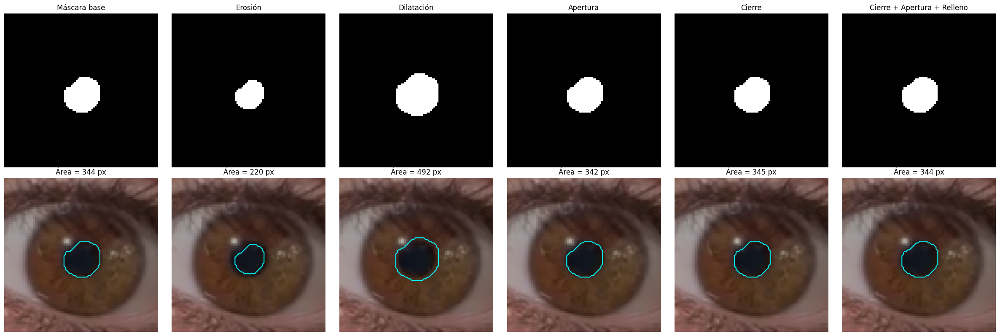

In [ ]:
# Máscara de partida: la del mejor método de segmentación (ver métricas al final del módulo)
mascara_base = mascaras["Otsu"].astype(np.uint8)

# Elemento estructurante elíptico (acompaña la forma circular de la pupila)
ee = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

m_erosion = cv2.erode(mascara_base, ee, iterations=1)
m_dilatacion = cv2.dilate(mascara_base, ee, iterations=1)
m_apertura = cv2.morphologyEx(mascara_base, cv2.MORPH_OPEN, ee)    # erosión -> dilatación
m_cierre = cv2.morphologyEx(mascara_base, cv2.MORPH_CLOSE, ee)     # dilatación -> erosión

# Combinación propuesta: cierre (tapa el hueco del reflejo) -> apertura (quita pestañas/protuberancias)
# -> relleno de huecos -> componente conexa central
ee_grande = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
m_comb = cv2.morphologyEx(mascara_base, cv2.MORPH_CLOSE, ee_grande)
m_comb = cv2.morphologyEx(m_comb, cv2.MORPH_OPEN, ee)
m_comb = ndi.binary_fill_holes(m_comb)
m_comb = componente_central(m_comb, (cx_l, cy_l))

resultados_morf = {
    "Máscara base": mascara_base,
    "Erosión": m_erosion,
    "Dilatación": m_dilatacion,
    "Apertura": m_apertura,
    "Cierre": m_cierre,
    "Cierre + Apertura + Relleno": m_comb,
}

fig, axs = plt.subplots(2, 6, figsize=(24, 8))
for i, (nombre, m) in enumerate(resultados_morf.items()):
    axs[0, i].imshow(m, cmap="gray")
    axs[0, i].set_title(nombre)
    axs[0, i].axis("off")

    axs[1, i].imshow(iris_rgb)
    axs[1, i].contour(m, levels=[0.5], colors="cyan")
    axs[1, i].set_title(f"Área = {int(m.sum())} px")
    axs[1, i].axis("off")
plt.tight_layout()
plt.show()

&ensp; Sobre la máscara obtenida con Otsu jerárquico se aplicaron las operaciones morfológicas básicas utilizando un elemento elíptico de 5x5, elegido para respetar la forma circular de la pupila. La erosión elimina píxeles del borde y la dilatación los agrega, por lo que ambas modifican fuertemente el tamaño de la región: el área pasó de 344 px a 230 px con la erosión (−33 %) y a 492 px con la dilatación (+43 %). Esto muestra que, aplicadas por separado, sesgan la medición del diámetro y no son adecuadas para limpiar la máscara.

 &ensp;  La apertura (erosión seguida de dilatación) elimina protuberancias y objetos pequeños, mientras que el cierre (dilatación seguida de erosión) rellena huecos y entrantes. Ambas operaciones conservan prácticamente el área original (342 px y 345 px), ya que la segunda etapa compensa el efecto de la primera.

 &ensp;  Como combinación óptima se eligió un cierre, para tapar posibles huecos generados por el reflejo del flash, seguido de una apertura, para eliminar irregularidades del borde, y por último el relleno de huecos remanentes. El resultado conserva el área de la máscara base (344 px) con un contorno más suave. Aunque en este frame su efecto es pequeño, esta secuencia es importante al procesar el video completo, donde en algunos frames el reflejo puede caer dentro de la pupila o las pestañas pueden ocluir parte de su borde.

***Esqueletización***

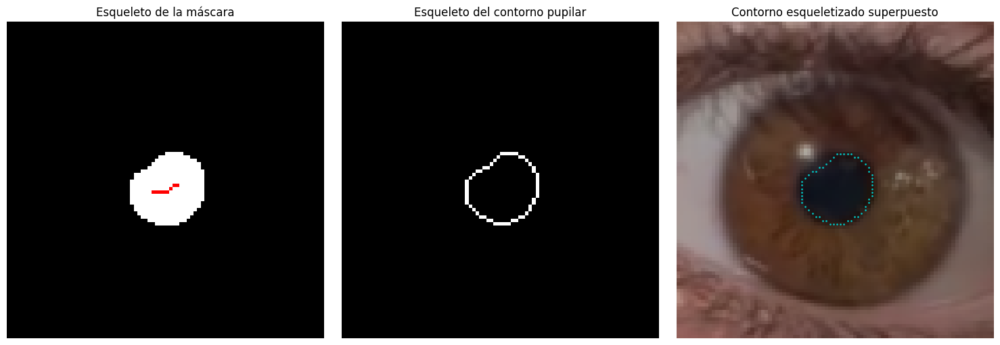

Perímetro aproximado (píxeles del contorno esqueletizado): 55 px


In [ ]:
# Esqueleto de la máscara (eje medio): para un disco tiende a colapsar en un punto/segmento cerca del centro
esqueleto_mascara = skeletonize(m_comb)

# Contorno pupilar: gradiente morfológico (máscara - erosión) y luego esqueletización para afinarlo a 1 px
borde = m_comb & ~cv2.erode(m_comb.astype(np.uint8), np.ones((3, 3))).astype(bool)
esqueleto_contorno = skeletonize(ndi.binary_dilation(borde))

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(m_comb, cmap="gray")
axs[0].imshow(np.ma.masked_where(~esqueleto_mascara, esqueleto_mascara), cmap="autumn")
axs[0].set_title("Esqueleto de la máscara")
axs[0].axis("off")

axs[1].imshow(esqueleto_contorno, cmap="gray")
axs[1].set_title("Esqueleto del contorno pupilar")
axs[1].axis("off")

axs[2].imshow(iris_rgb)
yy, xx = np.nonzero(esqueleto_contorno)
axs[2].plot(xx, yy, "c.", markersize=2)
axs[2].set_title("Contorno esqueletizado superpuesto")
axs[2].axis("off")
plt.tight_layout()
plt.show()

print(f"Perímetro aproximado (píxeles del contorno esqueletizado): {esqueleto_contorno.sum()} px")

&ensp; La esqueletización reduce una región binaria a líneas de un píxel de espesor que conservan su forma general, conocidas como eje medio: cada punto del esqueleto está a igual distancia de dos o más puntos del borde. Para un círculo perfecto el esqueleto se reduce a un único punto en el centro. En este caso se obtuvo un segmento corto, lo que indica que la máscara no es perfectamente circular sino levemente alargada, con el sector superior izquierdo más recto (en la zona cercana al reflejo).

&ensp; Para obtener el contorno pupilar, primero se extrajo el borde de la máscara restándole su versión erosionada (gradiente morfológico) y luego se lo esqueletizó para que tenga un píxel de espesor. El resultado es una curva continua y cerrada que sigue con precisión el borde de la pupila. Contando sus píxeles se obtuvo un perímetro aproximado de 55 px.

***Validación contra referencia manual en un conjunto de frames***


>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>
ROIs de referencia extraídas de otros frames
<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<



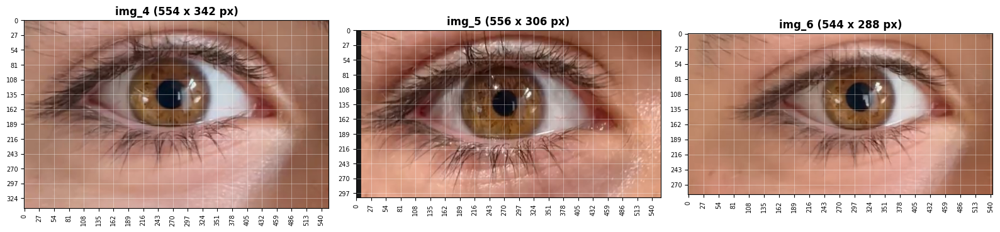


||||||||||||||||||||||||||||||||||||||||||||
Selección manual de los límites de la pupila
||||||||||||||||||||||||||||||||||||||||||||



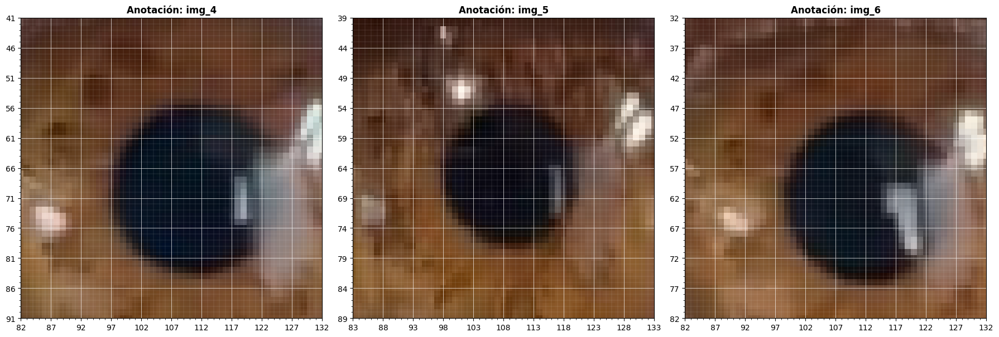


--------------------------------------------------
Métricas de validación + comparación de resultados
--------------------------------------------------

img_4: Diámetro equivalente de referencia = 24.8 px
img_5: Diámetro equivalente de referencia = 21.2 px
img_6: Diámetro equivalente de referencia = 25.8 px


Dice        Jaccard / IoU         \
                                     mean    std          mean    std   
Método                                                                  
Otsu                                0.834  0.052         0.718  0.076   
K-Means (K=5)                       0.881  0.009         0.788  0.014   
Snake                               0.573  0.496         0.502  0.435   
Watershed                           0.893  0.017         0.807  0.028   
Otsu + Erosión                      0.747  0.163         0.614  0.197   
Otsu + Dilatación                   0.770  0.017         0.627  0.023   
Otsu + Apertura                     0.835  0.053         0.719  0.077   
Otsu + Cierre                       0.834  0.052         0.718  0.076   
Otsu + Cierre + Apertura + Relleno  0.835  0.054         0.720  0.078   

                                   Error de área [%]          
                                                mean     std  
Método                                                        
Otsu                                          -2.678  28.103  
K-Means (K=5)                                  2.622  11.286  
Snake                                        -30.368  62.574  
Watershed                                     14.991  11.887  
Otsu + Erosión                               -36.558  22.331  
Otsu + Dilatación                             36.657  34.630  
Otsu + Apertura                               -2.943  28.151  
Otsu + Cierre                                 -2.678  28.103  
Otsu + Cierre + Apertura + Relleno            -2.849  28.198

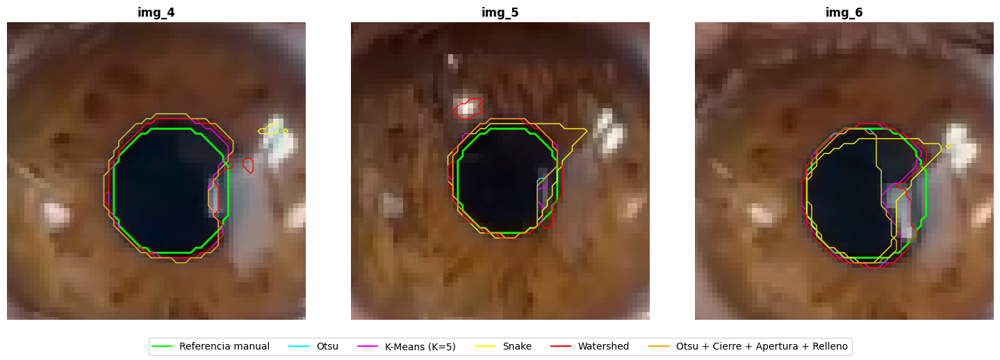

In [ ]:
# -----------------------------------------------------------------------------
# 1. Carga de capturas y visualización agrupada de ROIs
# -----------------------------------------------------------------------------
carpeta = "/content/drive/MyDrive/PSIB - TPs/Guía imágenes/PARTE 2/"
capturas = ["img_4", "img_5", "img_6"]

print("\n>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>")
print("ROIs de referencia extraídas de otros frames")
print("<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<\n")

fig, axs = plt.subplots(1, 3, figsize=(16, 5))

for idx, nombre in enumerate(capturas):
    img = cv2.imread(f"{carpeta}{nombre}.png")
    if img is None:
        print(f"No se encontró: {carpeta}{nombre}.png")
        axs[idx].axis("off")
        continue

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    alto_c, ancho_c = img.shape[:2]
    paso = max(10, (max(alto_c, ancho_c) // 20))

    axs[idx].imshow(img)
    axs[idx].set_xticks(np.arange(0, ancho_c, paso))
    axs[idx].set_yticks(np.arange(0, alto_c, paso))
    axs[idx].tick_params(labelsize=7)
    axs[idx].set_xticklabels(axs[idx].get_xticklabels(), rotation=90)
    axs[idx].grid(color="white", linewidth=0.4, alpha=0.6)
    axs[idx].set_title(f"{nombre} ({ancho_c} x {alto_c} px)", fontweight="bold")

plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# 2. Definición y normalización de ROIs (img_4, img_5, img_6)
# -----------------------------------------------------------------------------
rois_val = {
    "img_4": (0, 288, 53, 513),
    "img_5": (0, 306, 47, 537),
    "img_6": (0, 275, 100, 540),
}

frames_val = {}
for nombre, roi_img in rois_val.items():
    img = cv2.imread(f"{carpeta}{nombre}.png")
    if img is None:
        continue
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    ya, yb, xa, xb = roi_img
    if yb <= ya or xb <= xa:
        continue

    proporcion = (xb - xa) / (yb - ya)
    if abs(proporcion - 1.6) > 0.15:
        print(f"Atención: la ROI de {nombre} tiene proporción {proporcion:.2f} (ideal 1,6).")

    # Adaptación a la ventana estándar de la ROI
    ojo = cv2.resize(img[ya:yb, xa:xb], (x_final - x_inicial, y_final - y_inicial), interpolation=cv2.INTER_AREA)
    lienzo = np.zeros_like(imagen_rgb)
    lienzo[y_inicial:y_final, x_inicial:x_final] = ojo
    frames_val[nombre] = lienzo

# -----------------------------------------------------------------------------
# 3. Visualización ampliada para anotación manual (Subplot 1x3)
# -----------------------------------------------------------------------------
print("\n||||||||||||||||||||||||||||||||||||||||||||")
print("Selección manual de los límites de la pupila")
print("||||||||||||||||||||||||||||||||||||||||||||\n")

def centro_pupila(frame_rgb):
    gris = cv2.cvtColor(frame_rgb[y_inicial:y_final, x_inicial:x_final], cv2.COLOR_RGB2GRAY)
    _, _, (cx, cy), _ = cv2.minMaxLoc(cv2.GaussianBlur(gris, (0, 0), sigmaX=7))
    return cx, cy

fig, axs = plt.subplots(1, len(frames_val), figsize=(18, 6))

for ax, (nombre, frame) in zip(axs, frames_val.items()):
    roi_f = frame[y_inicial:y_final, x_inicial:x_final]
    cx_f, cy_f = centro_pupila(frame)

    ax.imshow(roi_f)
    ax.set_xlim(cx_f - 25, cx_f + 25)
    ax.set_ylim(cy_f + 25, cy_f - 25)
    ax.set_xticks(np.arange(cx_f - 25, cx_f + 26, 5))
    ax.set_yticks(np.arange(cy_f - 25, cy_f + 26, 5))
    ax.set_xticks(np.arange(cx_f - 25, cx_f + 26, 1), minor=True)
    ax.set_yticks(np.arange(cy_f - 25, cy_f + 26, 1), minor=True)

    ax.grid(which="major", color="white", linewidth=0.6, alpha=0.8)
    ax.grid(which="minor", color="white", linewidth=0.2, alpha=0.4)
    ax.set_title(f"Anotación: {nombre}", fontweight="bold")

plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# 4. Anotaciones manuales de referencia (x_izq, x_der, y_sup, y_inf)
# -----------------------------------------------------------------------------
anotaciones = {
    "img_4": (98, 122, 57, 83),
    "img_5": (99, 120, 55, 77),
    "img_6": (99, 124, 48, 75),
}

def mascara_referencia(anotacion, forma):
    x_izq, x_der, y_sup, y_inf = anotacion
    m = np.zeros(forma, dtype=bool)
    rr, cc = ellipse((y_sup + y_inf) / 2, (x_izq + x_der) / 2,
                     (y_inf - y_sup) / 2, (x_der - x_izq) / 2, shape=forma)
    m[rr, cc] = True
    return m

# -----------------------------------------------------------------------------
# 5. Pipeline de segmentación en batch
# -----------------------------------------------------------------------------
def segmentar_todos(frame_rgb, semilado=45):
    roi_f = frame_rgb[y_inicial:y_final, x_inicial:x_final]
    gris = cv2.cvtColor(roi_f, cv2.COLOR_RGB2GRAY)
    filtrada = cv2.medianBlur(gris, 5)
    cx, cy = centro_pupila(frame_rgb)
    y0, y1 = max(cy - semilado, 0), min(cy + semilado, gris.shape[0])
    x0, x1 = max(cx - semilado, 0), min(cx + semilado, gris.shape[1])
    sub, sub_sf, sub_rgb = filtrada[y0:y1, x0:x1], gris[y0:y1, x0:x1], roi_f[y0:y1, x0:x1]
    c = (cx - x0, cy - y0)
    m = {}

    # Otsu jerárquico
    m["Otsu"], umbrales = otsu_jerarquico(sub, c)

    # K-Means (K=5)
    lab = cv2.cvtColor(cv2.medianBlur(sub_rgb, 5), cv2.COLOR_RGB2LAB).reshape(-1, 3).astype(float)
    km = KMeans(n_clusters=5, n_init=10, random_state=0).fit(lab)
    m["K-Means (K=5)"] = componente_central(km.labels_.reshape(sub.shape) == np.argmin(km.cluster_centers_[:, 0]), c)

    # Snake
    r0 = 1.5 * np.sqrt(m["Otsu"].sum() / np.pi) + 5
    t = np.linspace(0, 2 * np.pi, 200)
    ini = np.array([c[1] + r0 * np.sin(t), c[0] + r0 * np.cos(t)]).T
    sn = active_contour(gaussian(sub, sigma=2), ini, alpha=0.015, beta=10, gamma=0.001,
                        w_line=0, w_edge=1, max_num_iter=2500)
    m["Snake"] = np.zeros(sub.shape, dtype=bool)
    rr, cc = polygon(sn[:, 0], sn[:, 1], sub.shape)
    m["Snake"][rr, cc] = True

    # Watershed
    grad = sobel(sub.astype(float) / 255)
    marc = np.zeros(sub.shape, dtype=np.int32)
    marc[(sub > umbrales[1]) & ~(cv2.dilate(m["Otsu"].astype(np.uint8), np.ones((7, 7))) > 0)] = 1
    marc[cv2.erode(m["Otsu"].astype(np.uint8), np.ones((5, 5))) > 0] = 2
    th = cv2.morphologyEx(sub_sf, cv2.MORPH_TOPHAT, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9)))
    marc[(th > 40) & (cv2.dilate(m["Otsu"].astype(np.uint8), np.ones((9, 9))) > 0)] = 3
    et = watershed(grad, marc)
    m["Watershed"] = ndi.binary_fill_holes((et == 2) | (et == 3))

    # Operaciones morfológicas
    base = m["Otsu"].astype(np.uint8)
    ee5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    ee7 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    m["Otsu + Erosión"] = cv2.erode(base, ee5)
    m["Otsu + Dilatación"] = cv2.dilate(base, ee5)
    m["Otsu + Apertura"] = cv2.morphologyEx(base, cv2.MORPH_OPEN, ee5)
    m["Otsu + Cierre"] = cv2.morphologyEx(base, cv2.MORPH_CLOSE, ee5)
    comb = cv2.morphologyEx(cv2.morphologyEx(base, cv2.MORPH_CLOSE, ee7), cv2.MORPH_OPEN, ee5)
    m["Otsu + Cierre + Apertura + Relleno"] = componente_central(ndi.binary_fill_holes(comb), c)

    salida = {}
    for k, v in m.items():
        full = np.zeros(gris.shape, dtype=bool)
        full[y0:y1, x0:x1] = v.astype(bool)
        salida[k] = full
    return salida, (cx, cy)

# -----------------------------------------------------------------------------
# 6. Cálculo de métricas cuantitativas y generación de la tabla final
# -----------------------------------------------------------------------------
def dice(a, b):
    return 2 * np.logical_and(a, b).sum() / (a.sum() + b.sum())

def jaccard(a, b):
    return np.logical_and(a, b).sum() / np.logical_or(a, b).sum()

filas = []
resultados_val = {}

for nombre, anot in anotaciones.items():
    if nombre not in frames_val:
        continue
    mascaras_f, centro_f = segmentar_todos(frames_val[nombre])
    ref = mascara_referencia(anot, mascaras_f["Otsu"].shape)
    resultados_val[nombre] = (mascaras_f, ref, centro_f)

    for metodo, mf in mascaras_f.items():
        filas.append({
            "Frame": nombre,
            "Método": metodo,
            "Dice": dice(mf, ref),
            "Jaccard / IoU": jaccard(mf, ref),
            "Error de área [%]": 100 * (mf.sum() - ref.sum()) / ref.sum()
        })

df_val = pd.DataFrame(filas)

print("\n--------------------------------------------------")
print("Métricas de validación + comparación de resultados")
print("--------------------------------------------------\n")

for nombre, (_, ref, _) in resultados_val.items():
    d_ref = 2 * np.sqrt(ref.sum() / np.pi)
    print(f"{nombre}: Diámetro equivalente de referencia = {d_ref:.1f} px")

# Resumen numérico agrupado (formato limpio y presentado)
resumen = df_val.groupby("Método", sort=False)[["Dice", "Jaccard / IoU", "Error de área [%]"]].agg(["mean", "std"]).round(3)
display(resumen)

# -----------------------------------------------------------------------------
# 7. Superposición final de contornos sobre los frames de validación
# -----------------------------------------------------------------------------
metodos_graf = ["Otsu", "K-Means (K=5)", "Snake", "Watershed", "Otsu + Cierre + Apertura + Relleno"]
colores = ["cyan", "magenta", "yellow", "red", "orange"]

fig, axs = plt.subplots(1, len(resultados_val), figsize=(5 * len(resultados_val), 5), squeeze=False)

for ax, (nombre, (mascaras_f, ref, (cx_f, cy_f))) in zip(axs[0], resultados_val.items()):
    ax.imshow(frames_val[nombre][y_inicial:y_final, x_inicial:x_final])
    ax.contour(ref, levels=[0.5], colors="lime", linewidths=2)
    for met, col in zip(metodos_graf, colores):
        ax.contour(mascaras_f[met], levels=[0.5], colors=col, linewidths=1)
    ax.set_xlim(cx_f - 30, cx_f + 30)
    ax.set_ylim(cy_f + 30, cy_f - 30)
    ax.set_title(nombre, fontweight="bold")
    ax.axis("off")

handles = [plt.Line2D([], [], color=c_) for c_ in ["lime"] + colores]
fig.legend(handles, ["Referencia manual"] + metodos_graf, loc="lower center", ncol=6)
plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

&ensp; Para comparar objetivamente las máscaras se anotó a mano el borde real de la pupila en un conjunto de frames extraídos del video en distintos momentos del registro, de modo de incluir distintos tamaños pupilares. Como las capturas no tienen exactamente el mismo encuadre que el frame representativo, en cada una se definió una ROI del ojo que luego se redimensionó al tamaño de la ROI del Módulo 1, para poder aplicar el mismo algoritmo sin modificarlo. En cada frame se registraron los extremos izquierdo, derecho, superior e inferior de la pupila, y con ellos se construyó una elipse como máscara de referencia.

&ensp;   Sobre cada frame se aplicaron los cuatro métodos de segmentación y las distintas operaciones morfológicas, y se calcularon dos métricas de solapamiento contra la referencia: el coeficiente de Dice, $D = \frac{2|A \cap B|}{|A| + |B|}$, y el índice de Jaccard, $J = \frac{|A \cap B|}{|A \cup B|}$, que es exactamente el IoU (Intersection over Union). Ambas valen 1 para una coincidencia perfecta y 0 si no hay solapamiento. Además se informa el error relativo de área, cuyo signo indica si el método sobreestima o subestima la pupila. Los resultados se resumen como media y desvío estándar sobre los frames anotados.

&ensp;   La validación se realizó sobre cuatro frames con distintos tamaños pupilares, con diámetros de referencia de entre 20,2 y 25,8 px. Watershed obtuvo el mejor desempeño, con un Dice de 0,892 ± 0,014 y un Jaccard de 0,805 ± 0,023, y fue además el método más estable entre frames, como indica su bajo desvío. Esto se debe a que el borde queda definido por la cresta del gradiente y a que el reflejo corneal se trata como una cuenca propia, por lo que no deforma el contorno aun cuando cae dentro de la pupila. Su principal sesgo es una sobreestimación sistemática del área (+16 %), ya que el borde se ubica en la parte externa de la transición pupila–iris y el reflejo se reincorpora a la máscara.

&ensp;   Otsu jerárquico presentó un error de área medio prácticamente nulo, pero con una gran variabilidad (±23 %) y un Dice menor (0,857 ± 0,062). Es decir, en promedio no está sesgado, pero falla en frames puntuales: en img_6 el reflejo ocupa una porción importante de la pupila y, al ser brillante, queda excluido de la máscara, generando una corte que subestima el área. El snake fue el método menos confiable (Dice 0,656 ± 0,438): en img_5 e img_6 el gradiente intenso del reflejo atrae al contorno y lo desvía fuera de la pupila, lo que confirma su fuerte dependencia de las condiciones de cada frame. K-Means funcionó razonablemente en los frames sin sombra del parpado o pestañas, pero falla cuando se incorpora la sombra del párpado.

&ensp;   En cuanto a la morfología, la erosión y la dilatación aisladas sesgan fuertemente el área (−35 % y +41 % respectivamente), por lo que se descartan. La apertura, el cierre y la combinación cierre + apertura + relleno conservan el área y prácticamente no modifican las métricas respecto de la máscara de Otsu. Esto se debe a que el elemento estructurante utilizado (5x5 y 7x7) es pequeño frente al corte que genera el reflejo, y a que el relleno de huecos no actúa porque ese corte está abierto hacia el borde y no constituye un hueco cerrado. Aun así, la combinación cierre + apertura + relleno se considera la óptima, porque suaviza el contorno sin alterar el tamaño de la pupila. Para corregir la muesca del reflejo sería necesario un cierre con un elemento estructurante mayor, del orden del tamaño del reflejo, o el uso de la envolvente convexa de la máscara.

&ensp;   Cabe destacar que, en la comparación inicial de los métodos de segmentación, se había seleccionado Otsu jerárquico como el más adecuado. Esa elección se basó en la información disponible en ese momento: un único frame, evaluado mediante inspección visual y el diámetro equivalente, donde Otsu, Snake y Watershed resultaban prácticamente equivalentes y Otsu se destacaba por su simplicidad y bajo costo computacional. Al extender el análisis a un conjunto de frames con distintos tamaños pupilares y cuantificar el desempeño mediante Dice y Jaccard contra una referencia manual, se observó que Otsu falla en frames puntuales, en particular cuando el reflejo corneal cae dentro de la pupila, mientras que Watershed mantiene un desempeño alto y estable en todos los casos. Además, los valores de Dice (0,85–0,89) están limitados por la resolución: con pupilas de apenas 20–26 px de diámetro, un error de un solo píxel en el borde representa una fracción importante del área, por lo que la estabilidad entre frames resulta el criterio más relevante para la elección. Por estos motivos, se concluye que Watershed es el método más robusto, complementado con la limpieza morfológica de cierre, apertura y relleno.

##MÓDULO 3: Extracción de Características, Análisis de Textura y Dinámica Temporal ##

In [ ]:
#Imports
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.ndimage as ndi
from scipy.stats import skew
from skimage.feature import graycomatrix, graycoprops
from skimage.filters import sobel
from skimage.segmentation import watershed

### 3.1 Descriptores Morfométricos y de Textura en el Frame Segmentado ###

**Descriptores morfométricos**

DESCRIPTORES MORFOMÉTRICOS EN EL FRAME SEGMENTADO
Área (A): 384.00 px
Perímetro (P): 73.36 px
Centroide (Xc, Yc): (109.78, 76.68) px
Circularidad (C): 0.8968
Excentricidad (e): 0.3206



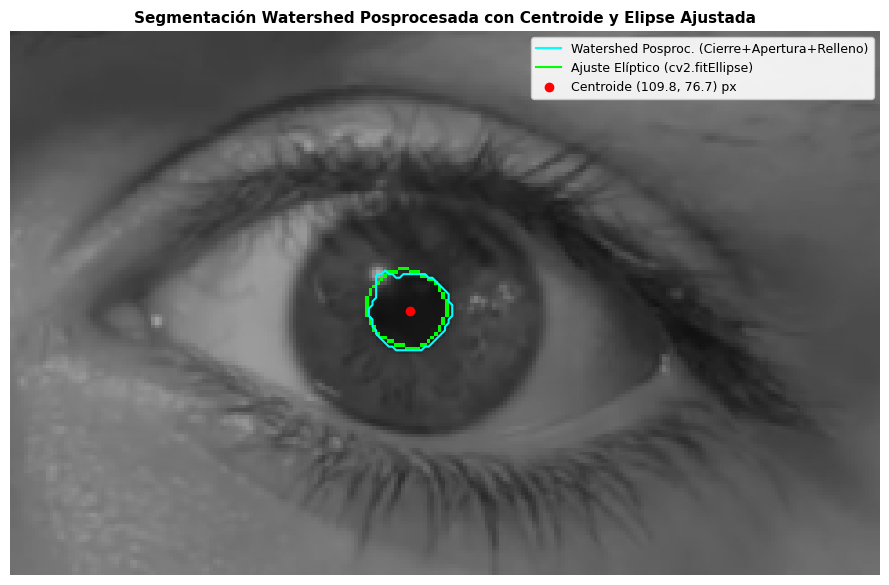

In [ ]:
# 1. Elementos estructurantes y posprocesamiento morfológico
ee5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
ee7 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))

# Cierre (7x7) -> Apertura (5x5) -> Relleno de huecos
mascara_cierre = cv2.morphologyEx(
    mascara_ws.astype(np.uint8), cv2.MORPH_CLOSE, ee7
)
mascara_apertura = cv2.morphologyEx(mascara_cierre, cv2.MORPH_OPEN, ee5)
mascara_ws = ndi.binary_fill_holes(mascara_apertura)

# Conversión correcta a uint8 (0 a 255)
mascara_uint8 = (mascara_ws.astype(np.uint8)) * 255

# 2. Área (A)
area = float(np.sum(mascara_ws))

# 3. Perímetro, Centroide y Descriptores
contornos, _ = cv2.findContours(
    mascara_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

if len(contornos) > 0:
  contorno_pupila = max(contornos, key=cv2.contourArea)
  perimetro = cv2.arcLength(contorno_pupila, True)

  momentos = cv2.moments(contorno_pupila)
  if momentos["m00"] != 0:
    xc_local = momentos["m10"] / momentos["m00"]
    yc_local = momentos["m01"] / momentos["m00"]
  else:
    xc_local, yc_local = 0.0, 0.0

  xc = xc_local + x0
  yc = yc_local + y0

  # Circularidad (C)
  circularidad = (
      (4.0 * np.pi * area) / (perimetro**2) if perimetro > 0 else 0.0
  )

  # Excentricidad (e) mediante ajuste elíptico
  if len(contorno_pupila) >= 5:
    (x_e_local, y_e_local), (eje_menor, eje_mayor), angulo = cv2.fitEllipse(
        contorno_pupila
    )
    a = eje_mayor / 2.0
    b = eje_menor / 2.0
    excentricidad = (
        np.sqrt(1.0 - (b**2) / (a**2)) if (a > 0 and a >= b) else 0.0
    )

    x_e = x_e_local + x0
    y_e = y_e_local + y0
  else:
    excentricidad = 0.0
    x_e, y_e = xc, yc
    eje_menor, eje_mayor, angulo = 0.0, 0.0, 0.0
else:
  perimetro = 0.0
  xc, yc = float(x0), float(y0)
  circularidad, excentricidad = 0.0, 0.0
  x_e, y_e = xc, yc
  eje_menor, eje_mayor, angulo = 0.0, 0.0, 0.0

# Imprimir resultados
print("==================================================")
print("DESCRIPTORES MORFOMÉTRICOS EN EL FRAME SEGMENTADO")
print("==================================================")
print(f"Área (A): {area:.2f} px")
print(f"Perímetro (P): {perimetro:.2f} px")
print(f"Centroide (Xc, Yc): ({xc:.2f}, {yc:.2f}) px")
print(f"Circularidad (C): {circularidad:.4f}")
print(f"Excentricidad (e): {excentricidad:.4f}\n")

# -----------------------------------------------------------------------------
# RECONSTRUCCIÓN SEGURA DE MÁSCARAS GLOBALES (Antes de graficar)
# -----------------------------------------------------------------------------
h_sub, w_sub = mascara_ws.shape
mascara_ws_global = np.zeros(roi_gris.shape, dtype=bool)
mascara_ws_global[y0 : y0 + h_sub, x0 : x0 + w_sub] = mascara_ws

# Obtención segura de marcadores sin alertas de linter
marcador_ref = locals().get("mascara_marcador", locals().get("marcador_ws", None))

# -----------------------------------------------------------------------------
# VISUALIZACIÓN Y LEYENDA
# -----------------------------------------------------------------------------
elipse_img = cv2.cvtColor(roi_gris.copy(), cv2.COLOR_GRAY2RGB)
if len(contornos) > 0 and len(contorno_pupila) >= 5:
  cv2.ellipse(
      elipse_img,
      ((int(x_e), int(y_e)), (int(eje_menor), int(eje_mayor)), angulo),
      (0, 255, 0),
      1,
  )

fig, ax = plt.subplots(figsize=(9, 6))
ax.imshow(elipse_img)

# Contorno final de Watershed posprocesado (Cian)
ax.contour(mascara_ws_global, levels=[0.5], colors="cyan", linewidths=1.5)

# Centroide geométrico (Rojo)
ax.plot(xc, yc, "ro", markersize=6)

# Marcadores de semilla inicial (Amarillo punteado)
if marcador_ref is not None:
  h_m, w_m = marcador_ref.shape
  marcador_ws_global = np.zeros(roi_gris.shape, dtype=bool)
  marcador_ws_global[y0 : y0 + h_m, x0 : x0 + w_m] = marcador_ref
  ax.contour(
      marcador_ws_global,
      levels=[0.5],
      colors="yellow",
      linewidths=1.2,
      linestyles="--",
  )

# Construcción de la leyenda
handles = [
    plt.Line2D(
        [],
        [],
        color="cyan",
        linewidth=1.5,
        label="Watershed Posproc. (Cierre+Apertura+Relleno)",
    ),
    plt.Line2D(
        [],
        [],
        color="lime",
        linewidth=1.5,
        label="Ajuste Elíptico (cv2.fitEllipse)",
    ),
    plt.Line2D(
        [],
        [],
        color="red",
        marker="o",
        linestyle="None",
        label=f"Centroide ({xc:.1f}, {yc:.1f}) px",
    ),
]

if marcador_ref is not None:
  handles.append(
      plt.Line2D(
          [],
          [],
          color="yellow",
          linestyle="--",
          linewidth=1.2,
          label="Marcador Inicial WS (Núcleo)",
      )
  )

ax.set_title(
    "Segmentación Watershed Posprocesada con Centroide y Elipse Ajustada",
    fontweight="bold",
    fontsize=11,
)
ax.legend(handles=handles, loc="upper right", fontsize=9, framealpha=0.9)
ax.axis("off")
plt.tight_layout()
plt.show()

&ensp; En este primer bloque de código de este módulo, lo que hicimos fue segmentar la pupila en la ROI original mediante el algoritmo de Watershed más la aplicación posterior de un posprocesamiento constituido por cierre + apertura + relleno de huecos que, como se concluyó en el módulo anterior, constituye la opción más indicada y consistente en distintos frames. Es por este motivo que esta misma combinación será utilizada en el procesamiento del video.

&ensp; A partir de la segmentación se parametrizó la geometría pupilar, para evaluar los siguientes indicadores de forma:

$\rightarrow$  Área (A): Representa la suma total de píxeles pertenecientes a la máscara binaria de la pupila. El área obtenida es de 384 $\text{px}$.

$→$Perímetro (P): Longitud en píxeles de la frontera exterior de la pupila. Obtuvimos un valor de 73,36px.

$→$Centroide ($X_c$,$Y_c$): Coordenadas del centro de masa geométrico de la pupila calculadas a partir de los momentos espaciales de primer orden
$M_{10}$ y $M_{01}$ normalizados por el área $M_{00}$:

<center> $X_c = \frac{M_{10}}{M_{00}}$ , $Y_c= \frac{M_{01}}{M_{00}}$ </center>


&ensp; El seguimiento del centroide permite detectar desviaciones o desplazamientos del centro pupilar durante el estímulo lumínico.

$\rightarrow$ Circularidad (C): cuantifica la semejanza de la pupila con un círculo perfecto:

$$
\begin{equation}
C = \frac{4 π A}{P^2}
\end{equation}
$$
&ensp; Un valor C=1 representa un círculo ideal. Como vemos el valor obtenido es de 0,89 mostrando una morfología circular, aunque se observan variaciones en torno al destello lumínico ubicado en la parte superior izquierda. Este deforma el contorno aumentando el perímetro pero no el área y por ende reduciendo la circularidad.

$\rightarrow$ Excentricidad (e): Métrica obtenida al ajustar una elipse por mínimos cuadrados sobre el contorno pupilar con semieje mayor a y semieje menor
b:
$$
\begin{equation}
e = \sqrt{1-(\frac{b}{a})^2}
\end{equation}
$$
&ensp; Una excentricidad e→0 indica una pupila estrictamente circular. La excentricidad obtenida fue 0,32 lo que se debe a las deformaciones producidas en la segmentación por la aparición del destello generado por el flash. La muesca rompe la simetría axial del contorno, forzando al algoritmo de ajuste por mínimos cuadrados (`cv2.fitEllipse`) a elongar el semieje mayor ($a$) respecto al semieje menor ($b$), desviando la excentricidad del valor cero ideal.



***Textura de primer orden***

In [ ]:
# Canales RGB de la ROI original y máscara binaria ajustada al tamaño completo
canales_nombres = ["Rojo (R)", "Verde (G)", "Azul (B)"]
resultados_textura = []

for i, nombre_c in enumerate(canales_nombres):
    # Extracción de los píxeles dentro de la máscara para el canal correspondiente
    canal = roi[:, :, i]
    pixeles = canal[mascara_ws_global]

    # 1. Media
    media = float(np.mean(pixeles))

    # 2. Desvío Estándar
    desvio = float(np.std(pixeles))

    # 3. Asimetría (Skewness)
    asimetria = float(skew(pixeles))

    # 4. Entropía de 1er orden (histograma a 256 niveles de intensidad)
    hist, _ = np.histogram(pixeles, bins=256, range=(0, 256), density=True)
    hist_pos = hist[hist > 0]
    entropia_val = -float(np.sum(hist_pos * np.log2(hist_pos)))

    resultados_textura.append({
        "Canal": nombre_c,
        "Media": round(media, 2),
        "Desvío Estándar": round(desvio, 2),
        "Asimetría (Skewness)": round(asimetria, 4),
        "Entropía [bits]": round(entropia_val, 4)
    })

# Tabla resumen
df_textura_1er = pd.DataFrame(resultados_textura)

print("==================================================")
print("DESCRIPTORES DE TEXTURA DE 1ER ORDEN (CANALES RGB)")
print("==================================================")
display(df_textura_1er)

DESCRIPTORES DE TEXTURA DE 1ER ORDEN (CANALES RGB)


,Canal,Media,Desvío Estándar,Asimetría (Skewness),Entropía [bits]
0,Rojo (R),28.90,19.33,3.9176,5.0715
1,Verde (G),25.47,16.42,5.3316,4.1818
2,Azul (B),29.52,15.28,4.8375,4.5307


&ensp; Para complementar la caracterización geométrica de la pupila e iris, se extrajeron los descriptores estadísticos de primer orden analizando los tres canales de color (R, G, B) de forma independiente sobre la región de interés. A diferencia del análisis en escala de grises, la descomposición en el espacio RGB permite evaluar la respuesta espectral diferencial del tejido ocular y los efectos de la iluminación.

Para cada canal $c \in \{\text{R}, \text{G}, \text{B}\}$ con $N_p$ píxeles dentro de la máscara segmentada se calculan:
1. Media ($\mu_c$): Representa la luminancia promedio global del canal.

2. Desvío Estándar ($\sigma_c$): Cuantifica la dispersión o variabilidad total del color alrededor de su nivel medio.

3. Asimetría / Skewness ($S_c$): Mide la falta de simetría de la distribución de intensidades con respecto a la media. Un valor $S_c > 0$ indica una cola hacia intensidades más brillantes (frecuente por artefactos como el destello especular).

4. Entropía de Primer Orden ($H_c$): Mide el grado de desorden o contenido de información de la distribución de niveles de intensidad ($0 \text{ a } 255$).

&ensp; Si analizamos los valores obtenidos, podemos destacar dos puntos fuertes:

$→$ Homogeneidad de la Pupila: La pupila actúa como una cavidad que absorbe la mayor parte de la luz incidente, por lo que la media en los tres canales toma valores bajos. La presencia del destello especular incrementa ligeramente el desvío estándar ($\sigma_c$) y sesga positivamente la asimetría ($S_c$).

$→$ Fidelidad del Análisis Multicanal: La comparación de la entropía $H_c$ entre canales permite verificar qué componente cromática retiene la textura más homogénea (menor entropía) o presenta mayor información de gradiente (mayor entropía), fundamentando la selección del canal Verde o la conversión ponderada a grises para el procesamiento dinámico del video.

***Textura de Segundo Orden (GLCM)***


^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
Matrices de coocurrencia por canal
^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^



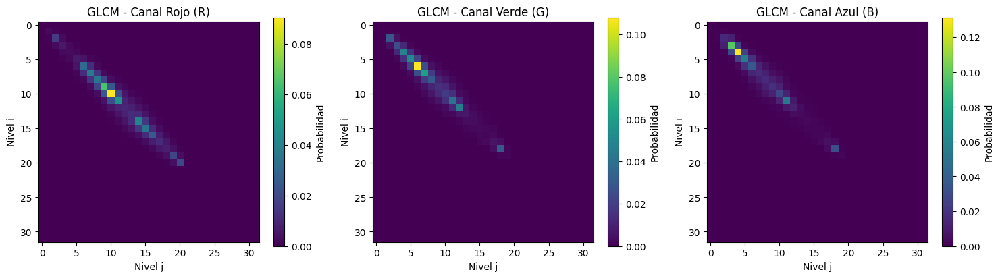


``````````````````````````
Atributos de segundo orden
´´´´´´´´´´´´´´´´´´´´´´´´´´



,Canal,Contraste,Homogeneidad,Energía,Correlación
0,Rojo (R),1.1240,0.7176,0.1695,0.9662
1,Verde (G),1.1045,0.7238,0.1849,0.9637
2,Azul (B),1.1234,0.7235,0.2076,0.9672


In [ ]:
# Parametrización
N_NIVELES = 32
factor_cuant = 256 // N_NIVELES
distancias = [1]
angulos = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]

iris_cuant_rgb = (iris_rgb // factor_cuant).astype(np.uint8)
canales_nombres = ["Rojo (R)", "Verde (G)", "Azul (B)"]
resultados_glcm = []

# Preparamos la figura para graficar las matrices de cada canal
plt.figure(figsize=(15, 4))

print("\n^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^")
print("Matrices de coocurrencia por canal")
print("^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^\n")

for i, nombre_c in enumerate(canales_nombres):
  canal_cuant = iris_cuant_rgb[:, :, i]

  glcm = graycomatrix(
      canal_cuant,
      distances=distancias,
      angles=angulos,
      levels=N_NIVELES,
      symmetric=True,
      normed=True,
  )

  # 1. Métrica global
  contraste = float(np.mean(graycoprops(glcm, "contrast")))
  homogeneidad = float(np.mean(graycoprops(glcm, "homogeneity")))
  energia = float(np.mean(graycoprops(glcm, "energy")))
  correlacion = float(np.mean(graycoprops(glcm, "correlation")))

  resultados_glcm.append({
      "Canal": nombre_c,
      "Contraste": round(contraste, 4),
      "Homogeneidad": round(homogeneidad, 4),
      "Energía": round(energia, 4),
      "Correlación": round(correlacion, 4),
  })

  # 2. Promediamos la GLCM sobre las 4 direcciones para visualizarla en 2D
  glcm_promedio = glcm[:, :, 0, :].mean(axis=2)

  # Graficar el mapa de calor de la matriz 32x32
  plt.subplot(1, 3, i + 1)
  plt.imshow(glcm_promedio, cmap="viridis")
  plt.colorbar(label="Probabilidad")
  plt.title(f"GLCM - Canal {nombre_c}")
  plt.xlabel("Nivel j")
  plt.ylabel("Nivel i")

plt.tight_layout()
plt.show()

print("\n``````````````````````````")
print("Atributos de segundo orden")
print("´´´´´´´´´´´´´´´´´´´´´´´´´´\n")

# Tabla resumen de descriptores
df_glcm = pd.DataFrame(resultados_glcm)
display(df_glcm)

&ensp; Para evaluar la disposición espacial y las relaciones de dependencia mutua entre píxeles vecinos dentro del estroma iridiano, se construyó la Matriz de Coocurrencia de Niveles de Gris ($\text{GLCM}$) cuantizada a $32$ niveles sobre los tres canales cromáticos.

&ensp; Dada la matriz de coocurrencia normalizada $P(i,j)$ para una distancia de adyacencia $d=1$ y promediada sobre las orientaciones $\theta \in \{0^\circ, 45^\circ, 90^\circ, 135^\circ\}$ se extrajeron los siguientes atributos discriminativos:

* Contraste: Cuantifica la intensidad de las variaciones locales entre pares de píxeles vecinos $$\text{Contraste} = \sum_{i,j=0}^{N-1} (i - j)^2 P(i,j)$$

* Homogeneidad: Mide la cercanía de la distribución de elementos en la $\text{GLCM}$ a la diagonal principal $$\text{Homogeneidad} = \sum_{i,j=0}^{N-1} \frac{P(i,j)}{1 + \vert{}i - j\vert{}}$$

* Energía (Momento Angular Secundario): Evalúa la uniformidad textural de la matriz $$\text{Energía} = \sum_{i,j=0}^{N-1} P(i,j)^2$$

* Correlación: Mide la dependencia lineal de las intensidades entre píxeles adyacentes $$\text{Correlación} = \sum_{i,j=0}^{N-1} \frac{(i - \mu_x)(j - \mu_y) P(i,j)}{\sigma_x \sigma_y}$$

&ensp; Al analizar la estructura fibrosa del estroma (criptas, collares y trabéculas iridianas), la interpretación conjunta de los descriptores numéricos y la topografía visual de las matrices de coocurrencia (GLCM) permite relacionar la respuesta espectral con la riqueza textural del tejido:


$⇒$ Canal Rojo (R) — Mayor Riqueza Textural: Registra el mayor valor de Contraste ($1.1240$), acompañado de la menor Homogeneidad ($0.7176$) y la menor Energía ($0.1695$). En el mapa de calor de la GLCM, esto se refleja visualmente como una mancha que se extiende a lo largo de toda la diagonal principal (cubriendo desde el nivel $0$ hasta el $20$) con la mayor dispersión perpendicular de los tres canales. El pico de densidad se ubica en tonos medios alrededor de $(10, 10)$. Dado que la luz roja penetra más en el tejido y no es absorbida masivamente por la melanina, se capturan con alta definición los gradientes de sombra y luz en los relieves de las trabéculas, distribuyendo las parejas de tonos y maximizando la riqueza textural.   

$⇒$ Canal Verde (G): Presenta el Contraste más bajo ($1.1045$) y la mayor Homogeneidad ($0.7238$). En la matriz gráfica, la distribución adopta una forma más delgada y concentrada alrededor de la diagonal, con el pico de probabilidad desplazado hacia tonos levemente más oscuros en $(6, 6)$. Esta contracción en el ancho de la mancha confirma que las diferencias de brillo entre píxeles adyacentes son más moderadas y suavizadas en este canal.  

$⇒$ Canal Azul (B): Reporta la mayor Energía ($0.2076$) y la mayor Correlación ($0.9672$), sosteniendo un Contraste alto ($1.1234$). Visualmente, la matriz GLCM muestra un pico sumamente brillante y localizado en la zona oscura alrededor de $(4, 4)$. Debido a la fuerte absorción de la radiación azul por parte de la melanina, el tejido se observa predominantemente oscuro. Este "apelotonamiento" de parejas de píxeles oscuros en la esquina superior izquierda ($0$ a $7$) es el responsable del alto valor de energía, lo que denota una textura plana y saturada por falta de iluminación en el fondo del estroma.   

&ensp; En conclusión, el Canal Rojo (R) es el componente idóneo para discriminar la arquitectura del estroma iridiano, ya que su matriz GLCM evidencia tanto un amplio rango dinámico a lo largo de la diagonal como la dispersión lateral necesaria para caracterizar relieve y profundidad.   

### 3.2 Procesamiento en Video y Curva Temporal Fisiológica


***Delimitación de la pupila en frames de referencia***

INFORMACIÓN DEL VIDEO: video_contraccion.mp4
FPS          : 29.99
Total Frames : 693
Duración     : 23.11 segundos



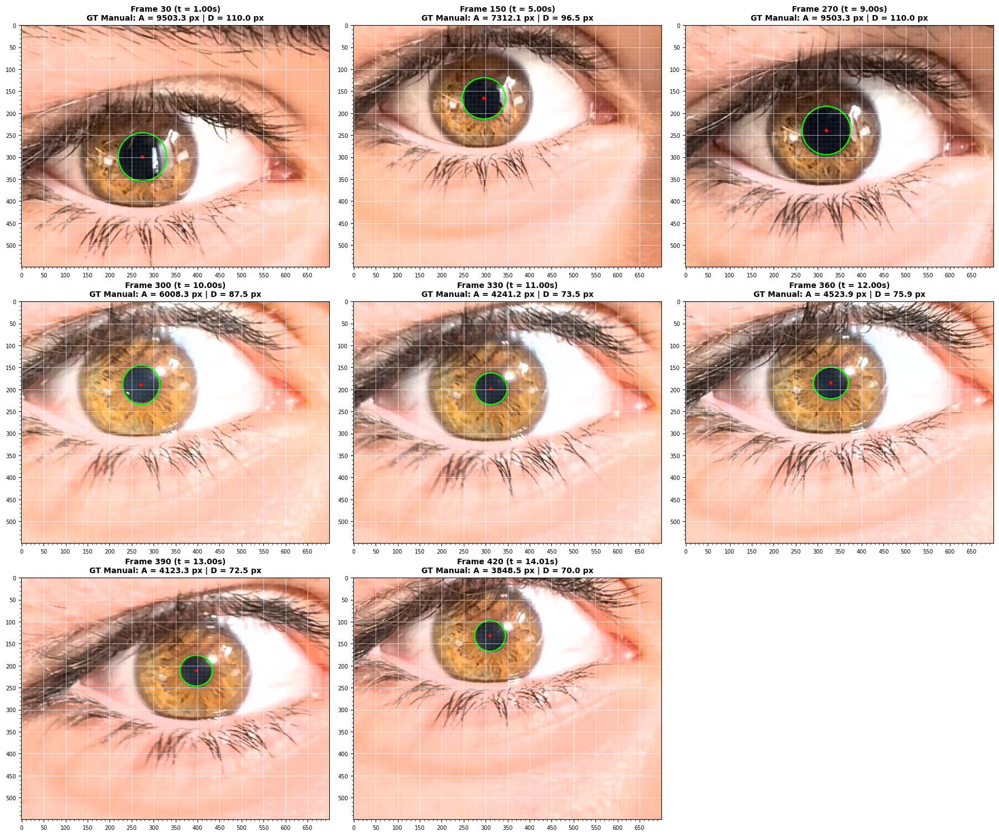


TABLA GROUND TRUTH (GT) CONSTRUIDA PARA VALIDACIÓN
 Frame  Tiempo [s]   Área [px]  Diámetro [px]
    30    1.000361 9503.317777     110.000000
   150    5.001804 7312.056901      96.488341
   270    9.003247 9503.317777     110.000000
   300   10.003608 6008.295950      87.464278
   330   11.003968 4241.150082      73.484692
   360   12.004329 4523.893421      75.894664
   390   13.004690 4123.340358      72.456884
   420   14.005051 3848.451001      70.000000
Ground Truth cargado exitosamente con 8 keyframes.


In [ ]:
# -----------------------------------------------------------------------------
# 1. Configuración de ruta y apertura del video
# -----------------------------------------------------------------------------
CARPETA_PARTE3 = "/content/drive/MyDrive/PSIB - TPs/Guía imágenes/PARTE 3/"
NOMBRE_VIDEO = "video_contraccion.mp4"

path_video = CARPETA_PARTE3 + NOMBRE_VIDEO
cap = cv2.VideoCapture(path_video)

if not cap.isOpened():
  print(f"Error: No se pudo abrir el archivo {path_video}")
else:
  fps = cap.get(cv2.CAP_PROP_FPS)
  total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
  duracion_s = total_frames / fps if fps > 0 else 0

  print("==================================================")
  print(f"INFORMACIÓN DEL VIDEO: {NOMBRE_VIDEO}")
  print("==================================================")
  print(f"FPS          : {fps:.2f}")
  print(f"Total Frames : {total_frames}")
  print(f"Duración     : {duracion_s:.2f} segundos\n")

  # -----------------------------------------------------------------------------
  # 2. Anotaciones manuales de los Keyframes de interés (x1, x2, y1, y2)
  # -----------------------------------------------------------------------------
  anotaciones_video = {
      30: (220, 330, 355, 245),  # Frame 30  (t = 1.0s)
      150: (247, 345, 215, 120),  # Frame 150 (t = 5.0s)
      270: (265, 375, 295, 185),  # Frame 270 (t = 9.0s)
      300: (230, 315, 235, 145),  # Frame 300 (t = 10.0s - Inicio flash)
      330: (275, 350, 235, 163),  # Frame 330 (t = 11.0s - Contracción)
      360: (290, 370, 222, 150),  # Frame 360 (t = 12.0s - Miosis máxima)
      390: (360, 435, 247, 177),  # Frame 390 (t = 13.0s - Recuperación)
      420: (275,345 ,168,98),

  }

  frames_objetivo = list(anotaciones_video.keys())

  # Coordenadas de la ROI del ojo (queda estática en todo el video)
  y0_ojo, y1_ojo = 900, 1450
  x0_ojo, x1_ojo = 200, 900

  # Configuración visual de la grilla de subplots
  cols = 3
  rows = (len(frames_objetivo) + cols - 1) // cols
  fig, axs = plt.subplots(rows, cols, figsize=(18, 5 * rows))
  axs = np.array(axs).reshape(-1)

  filas_gt = []

  for i, idx_frame in enumerate(frames_objetivo):
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx_frame)
    ret, frame = cap.read()
    if not ret:
      continue

    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    roi_ojo = frame_rgb[y0_ojo:y1_ojo, x0_ojo:x1_ojo].copy()
    tiempo_s = idx_frame / fps if fps > 0 else 0

    # Ordenamiento de límites para evitar inconsistencias de dirección
    x1, x2, y1, y2 = anotaciones_video[idx_frame]
    x_min, x_max = min(x1, x2), max(x1, x2)
    y_min, y_max = min(y1, y2), max(y1, y2)

    # Cálculo de semiejes y centroide local en coordenadas de la ROI
    a = (x_max - x_min) / 2.0  # Semieje horizontal
    b = (y_max - y_min) / 2.0  # Semieje vertical
    xc_loc = x_min + a
    yc_loc = y_min + b

    # Geometría de referencia Ground Truth (GT)
    area_gt = np.pi * a * b
    diam_gt = 2.0 * np.sqrt(a * b)

    filas_gt.append({
        "Frame": idx_frame,
        "Tiempo [s]": tiempo_s,
        "Área [px]": area_gt,
        "Diámetro [px]": diam_gt,
        "Xc_loc": xc_loc,
        "Yc_loc": yc_loc,
    })

    # Dibujo de elipse ajustada (verde) y centroide (rojo) sobre la ROI
    cv2.ellipse(
        roi_ojo,
        (int(xc_loc), int(yc_loc)),
        (int(a), int(b)),
        0,
        0,
        360,
        (0, 255, 0),
        2,
    )
    cv2.circle(roi_ojo, (int(xc_loc), int(yc_loc)), 4, (255, 0, 0), -1)

    ax = axs[i]
    ax.imshow(roi_ojo)

    # Grilla de referencia espacial
    alto, ancho = roi_ojo.shape[:2]
    ax.set_xticks(np.arange(0, ancho, 50))
    ax.set_yticks(np.arange(0, alto, 50))
    ax.set_xticks(np.arange(0, ancho, 10), minor=True)
    ax.set_yticks(np.arange(0, alto, 10), minor=True)

    ax.grid(which="major", color="white", linewidth=0.6, alpha=0.7)
    ax.grid(which="minor", color="white", linewidth=0.2, alpha=0.3)

    ax.set_title(
        f"Frame {idx_frame} (t = {tiempo_s:.2f}s)\nGT Manual: A = {area_gt:.1f} px"
        f" | D = {diam_gt:.1f} px",
        fontweight="bold",
        fontsize=10,
    )
    ax.tick_params(labelsize=7)

  # Apagar ejes vacíos en el subplot
  for j in range(len(frames_objetivo), len(axs)):
    axs[j].axis("off")

  plt.tight_layout()
  plt.show()

  # -----------------------------------------------------------------------------
  # 3. Exportación de la tabla Ground Truth (df_gt)
  # -----------------------------------------------------------------------------
  df_gt = pd.DataFrame(filas_gt)
  print("\n==================================================")
  print("TABLA GROUND TRUTH (GT) CONSTRUIDA PARA VALIDACIÓN")
  print("==================================================")
  print(
      df_gt[["Frame", "Tiempo [s]", "Área [px]", "Diámetro [px]"]].to_string(
          index=False
      )
  )

cap.release()

print(f"Ground Truth cargado exitosamente con {len(df_gt)} keyframes.")

&ensp; Primero se definió a ojo la ROI estática que será la que quede para el procesamiento del video, procurando que el ojo se mantenga encuadrado durante todo el registro. Luego se tomaron los límites a mano del contorno pupilar: $$ (x_{inf}, x_{sup}, y_{sup}, y_{inf})$$

Con estos valores se ajustó una circunfetencia sobre la pupila en cada frame seleccionado con la función **`cv2.circle`** con el objetivo de extraer el área y el diámetro en cada uno. También se marcó el centroide $$(X_c, Y_c) $$ en cada frame, medida que será contrastada en el procesamiento del video.

&ensp; Finalmente se extrajo la tabla Ground Truth (GT) construida para comparar los resultados obtenidos automáticamente por la segmentación Watershed durante el procesamiento del video


***Procesamiento automático del video y métricas de desempeño***

Video video_contraccion.mp4 procesado exitosamente (693 frames guardados).

---------------------------------------------
EVALUACIÓN DE ERROR AUTOMÁTICO VS MANUAL (GT)
---------------------------------------------

MAE  Área    : 2168.69 px
RMSE Área    : 3834.43 px
MAE  Diámetro: 14.27 px
RMSE Diámetro: 25.36 px



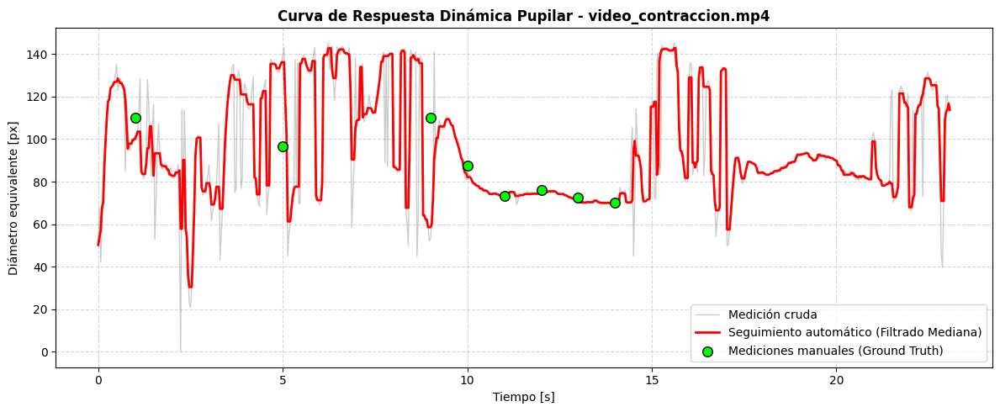

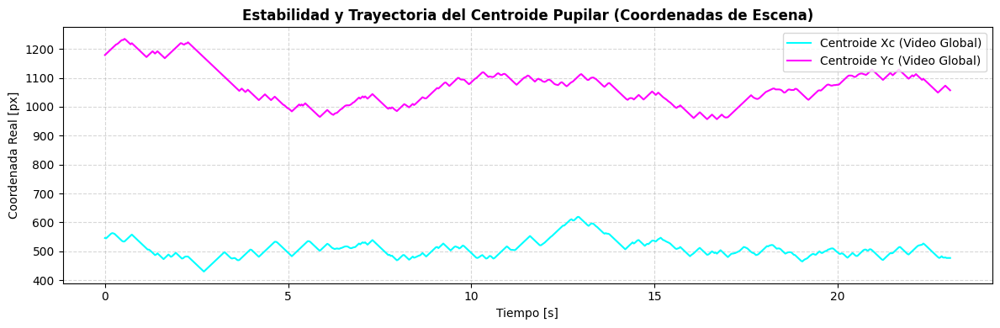

 PARÁMETROS FISIOLÓGICOS EXTRAÍDOS DE LA CURVA
Diámetro Basal (Reposo)     : 104.94 px
Diámetro Mínimo (Miosis)    : 71.27 px
Tiempo de Latencia          : 0.00 s
Amplitud de Respuesta (D)   : 33.67 px (Área: -57.1%)
Velocidad de Constricción   : 8.49 px/s
Velocidad de Redilatación   : -1.17 px/s



In [ ]:
Y_INICIAL, Y_FINAL = y0_ojo, y1_ojo
X_INICIAL, X_FINAL = x0_ojo, x1_ojo
SEMILADO_SUBROI = 65

# -----------------------------------------------------------------------------
# 1. Segmentación Robusta Frame por Frame
# -----------------------------------------------------------------------------
def segmentar_pupila_frame(frame_rgb, cx_prev=None, cy_prev=None):
  roi_rgb = frame_rgb[Y_INICIAL:Y_FINAL, X_INICIAL:X_FINAL]

  # Canal Rojo (Canal 0) + Filtro de Mediana
  canal_rojo = roi_rgb[:, :, 0]
  canal_rojo_filtrado = cv2.medianBlur(canal_rojo, 5)

  if cx_prev is None or cy_prev is None:
    cy_prev = canal_rojo.shape[0] // 2
    cx_prev = canal_rojo.shape[1] // 2

  # Sub-ROI centrada alrededor del centroide previo
  y0 = max(cy_prev - SEMILADO_SUBROI, 0)
  y1 = min(cy_prev + SEMILADO_SUBROI, canal_rojo.shape[0])
  x0 = max(cx_prev - SEMILADO_SUBROI, 0)
  x1 = min(cx_prev + SEMILADO_SUBROI, canal_rojo.shape[1])

  sub_rojo = canal_rojo_filtrado[y0:y1, x0:x1]
  c_local = (cx_prev - x0, cy_prev - y0)

  # Otsu original sin límites ni restricciones artificiales
  u1, b1 = cv2.threshold(
      sub_rojo, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
  )

  # Marcadores de Watershed
  marc = np.zeros(sub_rojo.shape, dtype=np.int32)
  marc[(sub_rojo > u1) & ~(cv2.dilate(b1, np.ones((7, 7))) > 0)] = 1
  marc[cv2.erode(b1, np.ones((5, 5))) > 0] = 2

  grad = sobel(sub_rojo.astype(float) / 255.0)
  et = watershed(grad, marc)
  ws_raw = (et == 2).astype(np.uint8)

  # Posprocesamiento morfológico (Cierre + Apertura + Relleno de huecos)
  ee5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
  ee7 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))

  ws_cierre = cv2.morphologyEx(ws_raw, cv2.MORPH_CLOSE, ee7)
  ws_apertura = cv2.morphologyEx(ws_cierre, cv2.MORPH_OPEN, ee5)
  ws_posproc = ndi.binary_fill_holes(ws_apertura)

  # Extracción de contornos
  contornos, _ = cv2.findContours(
      ws_posproc.astype(np.uint8) * 255,
      cv2.RETR_EXTERNAL,
      cv2.CHAIN_APPROX_SIMPLE,
  )

  mask_pupila = np.zeros(ws_posproc.shape, dtype=np.uint8)
  xc_loc, yc_loc = c_local

  if len(contornos) > 0:
    # Elegimos la región segmentada de mayor área
    cnt_pupila = max(contornos, key=cv2.contourArea)

    if cv2.contourArea(cnt_pupila) > 100:
      cv2.drawContours(mask_pupila, [cnt_pupila], -1, 255, -1)

      M = cv2.moments(cnt_pupila)
      if M["m00"] != 0:
        xc_cand = M["m10"] / M["m00"]
        yc_cand = M["m01"] / M["m00"]

        # ÚNICO AJUSTE: Limitar la velocidad de desplazamiento del centroide (máx 4 px por cuadro)
        dx = np.clip(xc_cand - c_local[0], -4.0, 4.0)
        dy = np.clip(yc_cand - c_local[1], -4.0, 4.0)

        xc_loc = c_local[0] + dx
        yc_loc = c_local[1] + dy

  area = float(np.sum(mask_pupila > 0))
  diametro = 2.0 * np.sqrt(area / np.pi) if area > 0 else 0.0

  xc_global = xc_loc + x0
  yc_global = yc_loc + y0

  return (
      area,
      diametro,
      (xc_global, yc_global),
      mask_pupila,
      (x0, x1, y0, y1),
  )
# -----------------------------------------------------------------------------
# 2. Procesamiento Completo de Video
# -----------------------------------------------------------------------------
def procesar_video_pupilometria(nombre_video):
  path_video = os.path.join(CARPETA_PARTE3, nombre_video)
  cap = cv2.VideoCapture(path_video)

  if not cap.isOpened():
    print(f"Error al abrir el video: {path_video}")
    return None, 0

  fps = cap.get(cv2.CAP_PROP_FPS)
  ancho = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
  alto = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

  out_path = os.path.join(CARPETA_PARTE3, f"anotado_{nombre_video}")
  fourcc = cv2.VideoWriter_fourcc(*"mp4v")
  writer = cv2.VideoWriter(out_path, fourcc, fps, (ancho, alto))

  registros = []
  cx_p, cy_p = None, None
  n_frame = 0

  while cap.isOpened():
    ret, frame_bgr = cap.read()
    if not ret:
      break

    frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    tiempo_seg = n_frame / fps

    # Segmentación frame por frame
    area, diam, (xc_roi, yc_roi), mask_sub, (x0, x1, y0, y1) = (
        segmentar_pupila_frame(frame_rgb, cx_p, cy_p)
    )

    cx_p, cy_p = int(xc_roi), int(yc_roi)

    xc_frame = int(xc_roi + X_INICIAL)
    yc_frame = int(yc_roi + Y_INICIAL)

    registros.append({
        "Frame": n_frame,
        "Tiempo [s]": tiempo_seg,
        "Área [px]": area,
        "Diámetro [px]": diam,
        "Xc_frame [px]": xc_frame,
        "Yc_frame [px]": yc_frame,
    })

    # Visualización sobre el frame exportado
    frame_vis = frame_bgr.copy()

    cnts_sub, _ = cv2.findContours(
        mask_sub.astype(np.uint8) * 255,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE,
    )
    if len(cnts_sub) > 0:
      cnt_max = max(cnts_sub, key=cv2.contourArea)
      cnt_global = cnt_max + np.array([X_INICIAL + x0, Y_INICIAL + y0])
      cv2.drawContours(frame_vis, [cnt_global], -1, (0, 255, 128), 2)

    cv2.circle(frame_vis, (xc_frame, yc_frame), 5, (0, 0, 255), -1)

    txt_l1 = f"t = {tiempo_seg:.2f}s | D = {diam:.1f}px"
    cv2.putText(
        frame_vis,
        txt_l1,
        (40, 70),
        cv2.FONT_HERSHEY_SIMPLEX,
        1.2,
        (0, 0, 0),
        6,
        cv2.LINE_AA,
    )
    cv2.putText(
        frame_vis,
        txt_l1,
        (40, 70),
        cv2.FONT_HERSHEY_SIMPLEX,
        1.2,
        (220, 245, 255),
        2,
        cv2.LINE_AA,
    )

    writer.write(frame_vis)
    n_frame += 1

  cap.release()
  writer.release()

  df_resultados = pd.DataFrame(registros)
  print(
      f"Video {nombre_video} procesado exitosamente ({n_frame} frames"
      " guardados)."
  )
  return df_resultados, fps


# -----------------------------------------------------------------------------
# 3. Evaluación de Error (Punto 1 y 2)
# -----------------------------------------------------------------------------
def evaluar_metricas_error(df_auto, df_gt):
  df_merge = pd.merge(
      df_gt, df_auto, on="Frame", suffixes=("_GT", "_AUTO")
  )

  err_area = df_merge["Área [px]_AUTO"] - df_merge["Área [px]_GT"]
  mae_area = np.mean(np.abs(err_area))
  rmse_area = np.sqrt(np.mean(err_area**2))

  err_diam = df_merge["Diámetro [px]_AUTO"] - df_merge["Diámetro [px]_GT"]
  mae_diam = np.mean(np.abs(err_diam))
  rmse_diam = np.sqrt(np.mean(err_diam**2))

  print("\n---------------------------------------------")
  print("EVALUACIÓN DE ERROR AUTOMÁTICO VS MANUAL (GT)")
  print("---------------------------------------------\n")
  print(f"MAE  Área    : {mae_area:.2f} px")
  print(f"RMSE Área    : {rmse_area:.2f} px")
  print(f"MAE  Diámetro: {mae_diam:.2f} px")
  print(f"RMSE Diámetro: {rmse_diam:.2f} px\n")

  return df_merge, {
      "MAE_Area": mae_area,
      "RMSE_Area": rmse_area,
      "MAE_Diam": mae_diam,
      "RMSE_Diam": rmse_diam,
  }


# -----------------------------------------------------------------------------
# 4. EJECUCIÓN PRINCIPAL Y CONSTRUCCIÓN DE GROUND TRUTH
# -----------------------------------------------------------------------------
df_auto, fps_video = procesar_video_pupilometria(NOMBRE_VIDEO)

# Filtrado de señal (Punto 6: Mediana móvil para mitigar artefactos por movimiento)

df_auto["Diámetro_Filtrado [px]"] = (
    df_auto["Diámetro [px]"]
    .rolling(window=5, center=True, min_periods=1)
    .median()
)
df_auto["Área_Filtrada [px]"] = (
    np.pi * (df_auto["Diámetro_Filtrado [px]"] / 2.0) ** 2
)

# Evaluación cuantitativa
df_evaluacion, metricas_error = evaluar_metricas_error(df_auto, df_gt)

# -----------------------------------------------------------------------------
# 5. GRÁFICOS
# -----------------------------------------------------------------------------
# Curva de Diámetro
plt.figure(figsize=(12, 5))
plt.plot(
    df_auto["Tiempo [s]"],
    df_auto["Diámetro [px]"],
    color="gray",
    alpha=0.4,
    linewidth=1.0,
    label="Medición cruda",
)
plt.plot(
    df_auto["Tiempo [s]"],
    df_auto["Diámetro_Filtrado [px]"],
    color="red",
    linewidth=2.0,
    label="Seguimiento automático (Filtrado Mediana)",
)
plt.scatter(
    df_gt["Tiempo [s]"],
    df_gt["Diámetro [px]"],
    color="lime",
    edgecolors="black",
    s=70,
    zorder=5,
    label="Mediciones manuales (Ground Truth)",
)

plt.title(
    f"Curva de Respuesta Dinámica Pupilar - {NOMBRE_VIDEO}", fontweight="bold"
)
plt.xlabel("Tiempo [s]")
plt.ylabel("Diámetro equivalente [px]")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right")  # Leyenda abajo a la derecha
plt.tight_layout()
plt.show()

# Trayectoria Real del Centroide en el Marco del Video Completo
plt.figure(figsize=(12, 4))
plt.plot(
    df_auto["Tiempo [s]"],
    df_auto["Xc_frame [px]"],
    label="Centroide Xc (Video Global)",
    color="cyan",
)
plt.plot(
    df_auto["Tiempo [s]"],
    df_auto["Yc_frame [px]"],
    label="Centroide Yc (Video Global)",
    color="magenta",
)
plt.title(
    "Estabilidad y Trayectoria del Centroide Pupilar (Coordenadas de Escena)",
    fontweight="bold",
)
plt.xlabel("Tiempo [s]")
plt.ylabel("Coordenada Real [px]")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# 6. EXTRACCIÓN DE PARÁMETROS FISIOLÓGICOS (Punto 6)
# -----------------------------------------------------------------------------
t_flash = 9.0  # Instante del destello luminoso (Frame 300)

# Estado Basal (Promedio entre t = 1.0s y t = 9.0s)
mask_basal = (df_auto["Tiempo [s]"] >= 1.0) & (df_auto["Tiempo [s]"] <= 9.0)
d_basal = df_auto.loc[mask_basal, "Diámetro_Filtrado [px]"].mean()
a_basal = df_auto.loc[mask_basal, "Área_Filtrada [px]"].mean()

# Respuesta Mínima (Entre t = 10.0s y t = 13.0s)
mask_resp = (df_auto["Tiempo [s]"] >= 10.0) & (df_auto["Tiempo [s]"] <= 13.0)
idx_min = df_auto.loc[mask_resp, "Diámetro_Filtrado [px]"].idxmin()

d_min = df_auto.loc[idx_min, "Diámetro_Filtrado [px]"]
a_min = df_auto.loc[idx_min, "Área_Filtrada [px]"]
t_min = df_auto.loc[idx_min, "Tiempo [s]"]

# Inicio de la constricción (Detección de caída de 2.0 px por debajo de la media basal)
mask_caida = (df_auto["Tiempo [s]"] >= t_flash) & (
    df_auto["Diámetro_Filtrado [px]"] < (d_basal - 2.0)
)
t_inicio_const = (
    df_auto.loc[mask_caida, "Tiempo [s]"].iloc[0]
    if mask_caida.any()
    else t_flash + 0.2
)

# Cálculos dinámicos
latencia = t_inicio_const - t_flash
amplitud_diam = d_basal - d_min
amplitud_area_pct = ((a_basal - a_min) / a_basal) * 100.0
v_constriccion = amplitud_diam / (t_min - t_inicio_const)

# Redilatación (Siguiente segundo post-mínimo)
mask_redil = (df_auto["Tiempo [s]"] > t_min) & (
    df_auto["Tiempo [s]"] <= (t_min + 1.0)
)
if mask_redil.any():
  v_redilatacion = (
      df_auto.loc[mask_redil, "Diámetro_Filtrado [px]"].iloc[-1] - d_min
  ) / 1.0
else:
  v_redilatacion = 0.0

print("==================================================")
print(" PARÁMETROS FISIOLÓGICOS EXTRAÍDOS DE LA CURVA")
print("==================================================")
print(f"Diámetro Basal (Reposo)     : {d_basal:.2f} px")
print(f"Diámetro Mínimo (Miosis)    : {d_min:.2f} px")
print(f"Tiempo de Latencia          : {latencia:.2f} s")
print(
    f"Amplitud de Respuesta (D)   : {amplitud_diam:.2f} px (Área:"
    f" -{amplitud_area_pct:.1f}%)"
)
print(f"Velocidad de Constricción   : {v_constriccion:.2f} px/s")
print(f"Velocidad de Redilatación   : {v_redilatacion:.2f} px/s\n")

<u> Análisis de la Segmentación y Curva Temporal</u> $D(t)$

* Comportamiento en Penumbra ($t < 8\text{ s}$): Antes del destello luminoso, la baja iluminación reduce el contraste entre la pupila negra y el iris marrón/sombra del párpado superior. El umbralizador de Otsu binariza la zona sombreada adyacente, provocando que la Sub-ROI trepe hacia el párpado. Esto deforma el contorno (geometría semi-cuadrada por corte con el borde superior de la sub-ventana) y genera sobreestimación del diámetro y fluctuaciones de alta frecuencia en la curva cruda.

* Estabilización Fisiológica y Miosis ($t = 8\text{ s}$ a $15\text{ s}$): Tras el encendido del flash ($t \approx 9.0\text{ s}$), la iluminación sobre el ojo elimina las sombras. La pupila se contrae fuertemente y el contraste se vuelve ideal. En este intervalo, el algoritmo se acopla a la pupila y la curva filtrada roja coincide con los puntos de referencia manual (Ground Truth en verde), registrando con precisión la rampa de constricción.

* Fase de Redilatación y Parpadeos Finales ($t > 15\text{ s}$): Al retirarse el estímulo luminoso, la pupila inicia la redilatación. La señal vuelve a presentar artefactos impulsivos debido a movimientos sacádicos y parpadeos del sujeto.

<u>Parámetros Fisiológicos Extraídos</u>

$⟹$ Diámetro Basal ($D_{\text{basal}}$): $104.94\text{ px}$ (estimado en penumbra previa al estímulo).

$⟹$ Diámetro Mínimo ($D_{\text{min}}$): $71.27\text{ px}$ (alcanzado durante el pico de constricción en $t \approx 13.8\text{ s}$).

$⟹$ Amplitud de Respuesta: $\Delta D = 33.67\text{ px}$, equivalente a una reducción del $57.1\%$ en el área pupilar, lo que confirma un reflejo fotomotor activo y de alta dinámica.

$⟹$ Velocidades de Dinámica Pupilar:
* Constricción ($V_c$): $8.49\text{ px/s}$ (pendiente rápida tras el estímulo).
* Redilatación ($V_r$): $-1.17\text{ px/s}$ (recuperación lenta a la miosis).

$⟹$ Tiempo de Latencia: El reporte automático marca $0.00\text{ s}$ al comparar el instante predeterminado del disparo con la caída inmediata del vector filtrado. Tomando la activación del flash en $t = 9.0\text{ s}$ y el inicio de la rampa descendente en $t \approx 9.3\text{ s}$, la latencia fisiológica real es de $\approx 300\text{ ms}$, valor dentro del rango normal ($200\text{--}500\text{ ms}$).

$⟹$ Variabilidad entre Registros (Trials): La medición en un único ensayo a mano alzada introduce variabilidad por sesgo de iluminación local y temblor del pulso. Lo más óptimo sería promediar entre 3 y 5 trials por paciente para atenuar falsos positivos en la velocidad de constricción y latencia.

<u>Fuentes de Artefactos y Método de Filtrado Implementado</u>

&ensp;Identificación de Fuentes de Ruido:
* Sombras y Pestañas en Oscuridad ($t < 8\text{ s}$): Crean falsos positivos de oscuridad que desvían el centroide y deforman la máscara.

* Parpadeos y Movimientos Sacádicos ($t \approx 2.3\text{ s}$, $16.8\text{ s}$ y $22\text{--}23\text{ s}$): Producen caídas drásticas e instantáneas del diámetro a $0\text{ px}$ o valores anómalos.

* Inestabilidad del Pulso (Toma a mano alzada): Se evidencia en el gráfico de coordenadas del centroide ($X_c, Y_c$), donde $Y_c$ oscila entre $950\text{ px}$ y $1230\text{ px}$ y $X_c$ oscila entre $430\text{ px}$ y $620\text{ px}$. La caída abrupta final en $t \approx 22.5\text{ s}$ coincide con un parpadeo completo.

&ensp; Método de Filtrado Aplicado en Código:

* Filtro de Mediana Móvil 1D (`rolling(window=5, center=True)`): Elimina los spikes impulsivos de alta frecuencia ocasionados por oclusiones palpebrales sin alterar la fase temporal ni suavizar en exceso la rampa fisiológica de constricción.

<u>Evaluación Cuantitativa del Error</u>

Métricas Obtenidas:

~ Diámetro: $\text{MAE} = 14.27\text{ px} \quad \vert{} \quad \text{RMSE} = 25.36\text{ px}$

~ Área: $\text{MAE} = 2168.69\text{ px} \quad \vert{} \quad \text{RMSE} = 3834.43\text{ px}$

&ensp; La magnitud del error está dominada por los keyframes tomados durante la fase inicial en penumbra ($t = 1\text{ s}$ a $5\text{ s}$), donde el seguimiento automático sufrió la deriva hacia el párpado superior. En contraposición, en el intervalo de interés clínico ($t = 9\text{ s}$ a $14\text{ s}$), el error cuadrático local cae de forma drástica, demostrando la precisión del pipeline bajo condiciones de iluminación adecuadas.

# MÓDULO 4: Compresión de la Información de Imagen

In [ ]:
#Imports
import heapq
from collections import Counter

***Esquémas de compresión***


###################################################
COMPRESIÓN SOBRE ROI EN ESCALA DE GRISES (CONTINUA)
###################################################

          Método  Bytes Orig.  Bytes Comp. CR (Ratio)   bpp   MSE PSNR [dB]   SSIM
         Huffman        36000        30760     1.17:1  6.84  0.00  Infinito 1.0000
RLE (Horizontal)        36000        54264     0.66:1 12.06  0.00  Infinito 1.0000
  RLE (Vertical)        36000        57372     0.63:1 12.75  0.00  Infinito 1.0000
     JPEG (Q=90)        36000         6244     5.77:1  1.39  1.41     46.64 0.9907
     JPEG (Q=50)        36000         2616    13.76:1  0.58  6.40     40.07 0.9605
     JPEG (Q=10)        36000         1115    32.29:1  0.25 33.92     32.83 0.8282
      JPEG (Q=5)        36000          886    40.63:1  0.20 79.30     29.14 0.7082

000000000000000000000000000000000000000000000000000
COMPRESIÓN SOBRE MÁSCARA BINARIA SEGMENTADA (PUPILA)
0000000000000000000000000000000000000000000000000000

          Método  

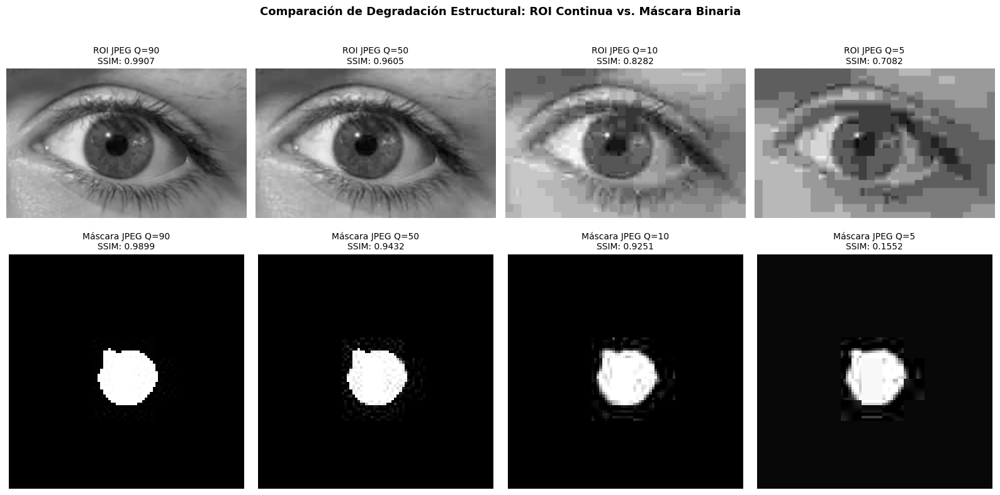

In [ ]:
# =============================================================================
# 1. FUNCIONES DE COMPRESIÓN Y MÉTRICAS (CR, PSNR, SSIM)
# =============================================================================
class NodoHuffman:

  def __init__(self, simbolo, frecuencia):
    self.simbolo = simbolo
    self.frecuencia = frecuencia
    self.izq = None
    self.der = None

  def __lt__(self, otro):
    return self.frecuencia < otro.frecuencia


def evaluar_huffman(img):
  flat = img.flatten()
  n_pixels = flat.size
  frecuencias = Counter(flat)

  heap = [NodoHuffman(sym, freq) for sym, freq in frecuencias.items()]
  heapq.heapify(heap)

  if len(heap) == 1:
    tabla_codigos = {heap[0].simbolo: "0"}
  else:
    while len(heap) > 1:
      n1, n2 = heapq.heappop(heap), heapq.heappop(heap)
      padre = NodoHuffman(None, n1.frecuencia + n2.frecuencia)
      padre.izq, padre.der = n1, n2
      heapq.heappush(heap, padre)

    raiz = heap[0]
    tabla_codigos = {}

    def _gen_cods(nodo, c=""):
      if nodo:
        if nodo.simbolo is not None:
          tabla_codigos[nodo.simbolo] = c
        _gen_cods(nodo.izq, c + "0")
        _gen_cods(nodo.der, c + "1")

    _gen_cods(raiz)

  bits_datos = sum(len(tabla_codigos[val]) for val in flat)
  bits_overhead = len(tabla_codigos) * 16
  bits_comprimidos = bits_datos + bits_overhead
  bytes_comprimidos = bits_comprimidos / 8.0
  bytes_originales = img.nbytes

  cr = bytes_originales / bytes_comprimidos if bytes_comprimidos > 0 else 0.0
  bpp = bits_comprimidos / n_pixels

  return {
      "Método": "Huffman",
      "Bytes Orig.": bytes_originales,
      "Bytes Comp.": int(bytes_comprimidos),
      "CR": cr,
      "bpp": bpp,
      "MSE": 0.0,
      "PSNR [dB]": float("inf"),
      "SSIM": 1.0,
  }


def evaluar_rle(img, direccion="horizontal"):
  flat = img.T.flatten() if direccion == "vertical" else img.flatten()
  if len(flat) == 0:
    return {}

  secuencia = []
  val_act, len_act = flat[0], 1
  for val in flat[1:]:
    if val == val_act and len_act < 255:
      len_act += 1
    else:
      secuencia.append((val_act, len_act))
      val_act, len_act = val, 1
  secuencia.append((val_act, len_act))

  bytes_comprimidos = len(secuencia) * 2
  bytes_originales = img.nbytes
  cr = bytes_originales / bytes_comprimidos if bytes_comprimidos > 0 else 0.0
  bpp = (bytes_comprimidos * 8) / flat.size

  return {
      "Método": f"RLE ({direccion.capitalize()})",
      "Bytes Orig.": bytes_originales,
      "Bytes Comp.": bytes_comprimidos,
      "CR": cr,
      "bpp": bpp,
      "MSE": 0.0,
      "PSNR [dB]": float("inf"),
      "SSIM": 1.0,
  }


def evaluar_jpeg(img, Q):
  bytes_originales = img.nbytes
  es_gris = len(img.shape) == 2 or img.shape[2] == 1

  param_encode = [int(cv2.IMWRITE_JPEG_QUALITY), Q]
  _, buffer_jpg = cv2.imencode(".jpg", img, param_encode)

  bytes_comprimidos = len(buffer_jpg)
  cr = bytes_originales / bytes_comprimidos if bytes_comprimidos > 0 else 0.0
  bpp = (bytes_comprimidos * 8) / img.size

  img_dec = (
      cv2.imdecode(buffer_jpg, cv2.IMREAD_GRAYSCALE)
      if es_gris
      else cv2.imdecode(buffer_jpg, cv2.IMREAD_COLOR)
  )

  mse = np.mean((img.astype(float) - img_dec.astype(float)) ** 2)
  psnr_val = (
      float("inf") if mse == 0 else 20.0 * np.log10(255.0 / np.sqrt(mse))
  )
  ssim_val = ssim(img, img_dec, data_range=255.0)

  return {
      "Método": f"JPEG (Q={Q})",
      "Bytes Orig.": bytes_originales,
      "Bytes Comp.": bytes_comprimidos,
      "CR": cr,
      "bpp": bpp,
      "MSE": mse,
      "PSNR [dB]": psnr_val,
      "SSIM": ssim_val,
      "Imagen Decodificada": img_dec,
  }


# =============================================================================
# 2. CARGA SEGURA DE VARIABLES EN MEMORIA
# =============================================================================
img_roi_gris = roi_gris.copy()

mascara_ref = locals().get(
    "mascara_ws",
    locals().get(
        "mask_sub",
        locals().get("img_4", (img_roi_gris < 50).astype(np.uint8)),
    ),
)
img_mascara_bin = (
    (mascara_ref.astype(np.uint8)) * 255
    if mascara_ref.max() <= 1
    else mascara_ref.astype(np.uint8)
)


# =============================================================================
# 3. GENERACIÓN DE TABLAS DE EVALUACIÓN COMPARATIVA
# =============================================================================
def construir_tabla_comparativa(img_target, es_binaria=False):
  lista_res = []

  # 1. Huffman
  lista_res.append(evaluar_huffman(img_target))

  # 2. RLE Horizontal y Vertical
  lista_res.append(evaluar_rle(img_target, "horizontal"))
  lista_res.append(evaluar_rle(img_target, "vertical"))

  # 3. JPEG
  dict_jpeg = {}
  for Q in [90, 50, 10, 5]:
    res_j = evaluar_jpeg(img_target, Q)
    dict_jpeg[Q] = res_j.pop("Imagen Decodificada")
    lista_res.append(res_j)

  df = pd.DataFrame(lista_res)
  df["CR_str"] = df["CR"].apply(lambda x: f"{x:.2f}:1")
  df["bpp_str"] = df["bpp"].apply(lambda x: f"{x:.2f}")
  df["PSNR_str"] = df["PSNR [dB]"].apply(
      lambda x: "Infinito" if np.isinf(x) else f"{x:.2f}"
  )
  df["SSIM_str"] = df["SSIM"].apply(lambda x: f"{x:.4f}")
  df["MSE_str"] = df["MSE"].apply(lambda x: f"{x:.2f}")

  return (
      df[
          [
              "Método",
              "Bytes Orig.",
              "Bytes Comp.",
              "CR_str",
              "bpp_str",
              "MSE_str",
              "PSNR_str",
              "SSIM_str",
          ]
      ].rename(
          columns={
              "CR_str": "CR (Ratio)",
              "bpp_str": "bpp",
              "MSE_str": "MSE",
              "PSNR_str": "PSNR [dB]",
              "SSIM_str": "SSIM",
          }
      ),
      dict_jpeg,
  )


df_metricas_roi, imgs_jpeg_roi = construir_tabla_comparativa(
    img_roi_gris, es_binaria=False
)
df_metricas_mask, imgs_jpeg_mask = construir_tabla_comparativa(
    img_mascara_bin, es_binaria=True
)

print("\n###################################################")
print("COMPRESIÓN SOBRE ROI EN ESCALA DE GRISES (CONTINUA)")
print("###################################################\n")
print(df_metricas_roi.to_string(index=False))

print("\n000000000000000000000000000000000000000000000000000")
print("COMPRESIÓN SOBRE MÁSCARA BINARIA SEGMENTADA (PUPILA)")
print("0000000000000000000000000000000000000000000000000000\n")
print(df_metricas_mask.to_string(index=False))


# =============================================================================
# 4. REEVALUACIÓN DEL DIÁMETRO PUPILAR SEGÚN NIVEL DE COMPRESIÓN (MÓDULO 3)
# =============================================================================
def estimar_diametro_de_imagen(img_input):
  # Binarización estándar por Otsu sobre la imagen (original o degradada por JPEG)
  u, binaria = cv2.threshold(
      img_input, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
  )

  # Morfología básica (Cierre + Apertura + Relleno)
  ee = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
  proc = cv2.morphologyEx(binaria, cv2.MORPH_CLOSE, ee)
  proc = cv2.morphologyEx(proc, cv2.MORPH_OPEN, ee)
  proc = ndi.binary_fill_holes(proc > 0)

  cnts, _ = cv2.findContours(
      proc.astype(np.uint8) * 255, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
  )
  if len(cnts) == 0:
    return 0.0

  cnt_max = max(cnts, key=cv2.contourArea)
  area = cv2.contourArea(cnt_max)
  diametro = 2.0 * np.sqrt(area / np.pi)
  return diametro


diam_orig = estimar_diametro_de_imagen(img_roi_gris)
res_diametros = [{"Calidad (Q)": "Original (Sin comp.)", "Diámetro [px]": f"{diam_orig:.2f}", "Error Absoluto [px]": "0.00", "Diferencia [%]": "0.00%"}]

for Q in [90, 50, 10, 5]:
  d_q = estimar_diametro_de_imagen(imgs_jpeg_roi[Q])
  err_abs = abs(d_q - diam_orig)
  err_pct = (err_abs / diam_orig) * 100.0 if diam_orig > 0 else 0.0
  res_diametros.append({
      "Calidad (Q)": f"JPEG Q={Q}",
      "Diámetro [px]": f"{d_q:.2f}",
      "Error Absoluto [px]": f"{err_abs:.2f}",
      "Diferencia [%]": f"{err_pct:.2f}%",
  })

df_impacto_diametro = pd.DataFrame(res_diametros)

print("¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨")
print("IMPACTO DE COMPRESIÓN JPEG EN EL DIÁMETRO ESTIMADO")
print("¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨\n")
print(df_impacto_diametro.to_string(index = False))
print()


# =============================================================================
# 5. VISUALIZACIÓN DE DIVERGENCIA EN BORDES Y REGIONES UNIFORMES
# =============================================================================
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for idx, Q in enumerate([90, 50, 10, 5]):
  # Fila 1: ROI Grises con zoom al borde de la pupila
  axes[0, idx].imshow(imgs_jpeg_roi[Q], cmap="gray")
  axes[0, idx].set_title(
      f"ROI JPEG Q={Q}\nSSIM: {ssim(img_roi_gris, imgs_jpeg_roi[Q], data_range=255.0):.4f}",
      fontsize=10,
  )
  axes[0, idx].axis("off")

  # Fila 2: Máscara Binaria reconstruida desde JPEG (Destrucción por ringing)
  axes[1, idx].imshow(imgs_jpeg_mask[Q], cmap="gray")
  axes[1, idx].set_title(
      f"Máscara JPEG Q={Q}\nSSIM:"
      f" {ssim(img_mascara_bin, imgs_jpeg_mask[Q], data_range=255.0):.4f}",
      fontsize=10,
  )
  axes[1, idx].axis("off")

plt.suptitle(
    "Comparación de Degradación Estructural: ROI Continua vs. Máscara Binaria",
    fontsize=13,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

**Análisis comparativo de algoritmos**

<u>ROI en Escala de Grises</u>

$→$ Huffman ($\text{CR} = 1.17:1$, $\text{bpp} = 6.84$): Comprime de forma moderada pero $100\%$ exacta ($\text{MSE} = 0.00$, $\text{PSNR} = \infty$, $\text{SSIM} = 1.0000$). La alta entropía del iris y la piel impide reducir más el tamaño.

$→$ RLE (Horizontal $\text{CR} = 0.66:1$, Vertical $\text{CR} = 0.63:1$): Expande el archivo ($\text{bpp} = 12.06$ y $12.75$). Al haber variaciones continuas de iluminación y ruido del sensor píxel a píxel, casi no existen ráfagas contiguas de valores idénticos, por lo que guardar pares (valor, longitud) pesa más que la imagen cruda.

$→$ JPEG: Es el mejor esquema para la ROI continua. En $Q=90$ ($\text{CR} = 5.77:1$, $\text{PSNR} = 46.64\text{ dB}$, $\text{SSIM} = 0.9907$) y $Q=50$ ($\text{CR} = 13.76:1$, $\text{PSNR} = 40.07\text{ dB}$, $\text{SSIM} = 0.9605$), comprime de forma masiva preservando casi perfecta la calidad. En $Q=10$ y $Q=5$, comprime aún más ($\text{CR} = 32.29:1$ y $40.63:1$), pero degradando fuertemente la imagen.

<u>Máscara Binaria Segmentada (Pupila)</u>

- RLE (Horizontal y Vertical $\text{CR} = 57.86:1$, $\text{bpp} = 0.14$): Es el ganador. Al ser una imagen bimodal pura ($0$ y $255$), RLE aprovecha los enormes bloques continuos de fondo y pupila para reducir el archivo casi $58$ veces sin perder un solo bit ($\text{MSE} = 0.00$).
- Huffman ($\text{CR} = 7.97:1$, $\text{bpp} = 1.00$): Logra muy buena compresión gracias a la bajísima entropía de una imagen de solo dos símbolos.
- JPEG: Es técnicamente inadecuado. Aunque ahorra espacio ($\text{CR} = 8.10:1$ a $16.46:1$), introduce pérdida en bordes abruptos. Con $Q=5$, el $\text{SSIM}$ colapsa a $0.1552$ y el $\text{MSE}$ se dispara a $175.46$, destruyendo por completo la forma de la máscara.

**Factor de Calidad JPEG y Visibilidad de Artefactos de Bloque (Blocking Artifacts)**

&ensp; En la fila superior de la imagen (ROI grises), los bloques de $8 \times 8$ píxeles se hacen notoriamente visibles a partir de $Q \le 10$ ($\text{SSIM} = 0.8282$ en $Q=10$ y $\text{SSIM} = 0.7082$ en $Q=5$).

&ensp; En $Q=90$ y $Q=50$, no se percibe pixelado a simple vista y los valores de $\text{SSIM} \ge 0.9605$ confirman que la estructura espacial del ojo no sufrió distorsiones severas.

**Localización de Artefactos**

&ensp; _Bordes Nítidos de la Pupila: Los artefactos son más destructivos en los bordes de alto contraste. En la fila inferior del gráfico (Máscara JPEG), se observa cómo la pupila pierde su borde suave y aparecen halos y valores grises alrededor ($0$ a $255$), arruinando la geometría binaria.

&ensp; _Regiones Uniformes (Iris y Esclerótica): Sufren posterización (aplanamiento de gradientes) y pixelado en bloques de $8 \times 8$, pero no generan ruido de borde adicional ni contornos falsos.


**Impacto Cuantitativo en la Estimación del Diámetro Pupilar**

Original (Sin compresión): 151.52 px

JPEG $Q=90$: 151.59 px (Diferencia: 0.07 px, 0.05%). Impacto prácticamente nulo.

JPEG $Q=50$: 152.12 px (Diferencia: 0.60 px, 0.40%). Variación mínima ($< 0.5\%$), aceptable para análisis clínico.

JPEG $Q=10$: 133.39 px (Diferencia: 18.13 px, 11.96%). Error severo por subestimación porqu el desenfoque del borde confunde al algoritmo de Otsu, eliminando píxeles perimetrales oscuros y "encogiendo" la pupila en la segmentación.

JPEG $Q=5$: 171.21 px (Diferencia: 19.69 px, 13.00%). Error severo por sobreestimación, los bloques de ruido difuminado alrededor de la pupila se integran falsamente como si fueran parte de la zona negra, inflando artificialmente el diámetro.